# Unde există informație predictivă în microstructura BTCUSDT, cât persistă și de unde vine

**Studiu exploratoriu pe datasetul `btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · iulie 2025 – octombrie 2026 · bare time, volume, dollar și CUSUM

## Rezumat

**Întrebare.** Unde există informație predictivă despre randamentul pe mid în datasetul `btcusdt_v2`, cât persistă, din ce features sau familii provine și cum se schimbă contribuția lor între orizonturi, ca bază pentru decizia privind un experiment cu istoric explicit al microstructurii.

**Toate rezultatele sunt `EXPLORATORII`:** întregul istoric (iulie 2025 – octombrie 2026) fusese deja folosit de notebook-urile anterioare. Ce urmează trebuie confirmat pe date de după 2026-10-31.

**Răspunsuri scurte.**

1. **Unde există semnal.** Doar în primele secunde după decizie. Pe `time_1m`, `qi_1` singur dă R² out-of-sample 0,54% la 1 minut, 0,23% la 2 minute și 0,08% la 5 minute, pozitiv în toate cele 13 luni. Pentru intervalele 30 s – 2 min, 2 – 5 min și 5 – 10 min, R² este zero pentru toate seturile, modelele și familiile: R²-ul cumulativ la 5–10 minute este mișcarea primelor secunde, rămasă în preț și diluată.
2. **Ce bare sunt mai bune.** La închiderile native, barele volume și dollar par superioare (1,3–1,9% la 1 minut, 6–8% pe bara următoare), dar avantajul vine din **prospețime și din momentul închiderii**: 75–90% dintre barele de evenimente încep în aceeași milisecundă în care s-a închis precedenta, iar sweep-ul care a închis bara nu este încă absorbit de mid. Cu 100 ms întârziere rămâne ~15% din R² pe bara următoare, iar cu 1 s nimic. **Pe un ceas comun, cu ultima bară deja închisă, toate reprezentările dau R² ≈ 0**, în timp ce `qi_1` proaspăt la același moment dă 0,45%. CUSUM este dominat de câteva zile și nu este interpretabil pe ceas. O țintă pe ultimul trade umflă artificial R² (51% pe CUSUM, mecanic).
3. **De unde vine.** Pe `time_1m`: starea nivelului 1 din book (imbalance plus cantitățile și adâncimile pe fiecare parte, substitute între ele; 1,28 pp la 1 minut când sunt permutate împreună). Peste `qi_1`, restul microstructurii adaugă cel mult 0,07 pp. Pe volume și dollar: fluxul semnat al ultimelor secunde (`run_sign`, modulat de lungimea și volumul seriei curente, care nu au informație proprie). Peste preț-volum-calendar, microstructura adaugă 0,5–0,9 pp la 1 minut (cu excepția LightGBM pe dollar); pe `time_1m` incrementul rămâne semnificativ până la 5 minute, dar mic (0,08 pp) și aproape în întregime prin `qi_1`, iar pe volume și dollar dispare de la 3 minute.
4. **Între orizonturi.** Aceleași familii domină la toate orizonturile până la 4–5 minute, iar contribuția lor scade monoton; nicio familie nu apare robust abia la orizonturi mai lungi, niciun semn nu se inversează, iar fereastra cea mai scurtă a unui feature domină la orice orizont al țintei. Reversia lentă din randamentele pe 1–24 h este sub pragul de semnificație. Funding-ul, open interest-ul și lichidările nu contribuie până la 10 minute (orizonturile de ore nu au fost testate).
5. **Relevanță economică.** Pe `time_1m`, brutul este sub 1 bps pe tranzacție. La închiderea barelor de evenimente, cele mai puternice 2% dintre semnale au ~3,5 bps brut cu 100 ms întârziere și ~0 cu 1 s; peste un cost ipotetic de 2 bps dus-întors, doar la latență foarte mică. Este un indiciu care cere o simulare cu latență reală, nu o strategie.

| Întrebare | Dovadă principală | Statut |
|---|---|---|
| Imbalance-ul top-of-book prezice mișcarea primelor secunde (`time_1m`) | R² 0,54% [0,45; 0,63] la 1 min, 13/13 luni, panta ≈ 1 | **Susținut** (replică primul studiu) |
| Informație despre mișcarea de după 30 s | R² ≈ 0 pe toate intervalele, zero features semnificative | **Nesusținut** (absență în acest eșantion) |
| Barele de evenimente au o reprezentare mai informativă | ceas comun: R² ≈ 0 pentru toate; avantajul nativ dispare în 0,1–1 s | **Nesusținut**; avantajul este prospețime + momentul închiderii |
| Microstructura adaugă peste `qi_1` pe bare de timp | +0,07 pp (ridge) / 0 (LightGBM) la 1 min | Indiciu foarte slab |
| Fluxul semnat la închiderea barelor de evenimente | importanță (MDA) 2,6 pp la 1 min; ~15% din R² rămâne după 100 ms | Susținut statistic, **neexecutabil** fără latență sub 100 ms |
| Semnal executabil după costuri | ~3,5 bps brut la 100 ms (top 2%), 0 la 1 s | Indiciu, netestat realist |

**Următorul pas propus** (secțiunea 16): un experiment sub-secundă cu istoric scurt (30 s pe grila de 100 ms a nivelului 1, plus tranzacții), pe ceas comun și cu întârziere explicită, în care contribuția istoricului se măsoară față de aceleași date rezumate manual și față de aceeași secvență cu ordinea amestecată.

## 1. Setup și reproductibilitate

**Mediu.** Notebook-ul rulează în mediul conda `disertatie` (Python 3.11, pandas, pyarrow, LightGBM, scikit-learn, scipy). Pachetul `chdds` este importat din sursă numai pentru `incident_rows`, `META_COLS` și `QUALITY_COLS`.

**Memorie și reluare.** Laptopul are ~32 GB RAM, iar o parte este ocupată de alte aplicații. Datele se citesc lunar și pe coloane, fiecare set de bare se procesează separat, iar matricile de features se păstrează ca `float32` pe disc (memory-mapped). Toate rezultatele grele (features, ținte, predicții out-of-sample, importanțe) se salvează compact în directorul de cache (`PIH_CACHE`, implicit `~/.cache/quantforge/predictive_horizons`), deci o rulare întreruptă se reia de unde a rămas. Paralelismul este limitat la `PIH_WORKERS` procese (implicit 8), fiecare cu un singur fir LightGBM/BLAS.

**Determinism.** Semințele sunt fixe și LightGBM rulează în mod determinist. Notebook-ul nu scrie nimic lângă date, iar ultima celulă verifică faptul că fișierele sursă nu s-au schimbat în timpul rulării.

In [1]:
import os, re, json, sys, time, gc, warnings, platform, resource, pickle, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import lightgbm as lgb
import sklearn, scipy
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 20261109
WORKERS = int(os.environ.get("PIH_WORKERS", "8"))
QUICK = os.environ.get("PIH_QUICK", "0") == "1"          # smoke test on a short history
VERSION = "v1"
CACHE = Path(os.environ.get("PIH_CACHE", str(Path.home() / ".cache/quantforge/predictive_horizons"))) / (VERSION + ("_quick" if QUICK else ""))
CACHE.mkdir(parents=True, exist_ok=True)


def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Rulează notebook-ul din interiorul repository-ului QuantForge.")


ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
GRID = CHDDS / "derived/book_grid/btcusdt_v2/grid100ms"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows, META_COLS, QUALITY_COLS
MAN = json.loads((DATA / "manifest.json").read_text())
SID = {v["name"]: k for k, v in MAN["bar_sets"].items()}


def source_fingerprint():
    files = [DATA / "manifest.json"] + sorted(GRID.glob("*.parquet"))
    for s in ["time_1m", "volume_50btc", "dollar_5musdt", "cusum_5bps"]:
        files += sorted((DATA / SID[s]).glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))


FINGERPRINT_START = source_fingerprint()


def cached(name, fn):
    """Compact intermediate results are cached on disk, so an interrupted run resumes where it stopped."""
    p = CACHE / f"{name}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    out = fn()
    tmp = p.with_suffix(".tmp")
    tmp.write_bytes(pickle.dumps(out, protocol=5))
    tmp.replace(p)
    return out


# Light chart surface; categorical slots in fixed order (bar sets keep their colour everywhere).
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRIDC, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "lines.markersize": 6, "legend.frameon": False, "legend.fontsize": 9})
DIVERGING = LinearSegmentedColormap.from_list("bluered", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2a"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#f4f8fe", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
pd.set_option("display.width", 240, "display.max_columns", 40, "display.max_rows", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | LightGBM {lgb.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")
print(f"Dataset {DATA.name}, creat {MAN['created_utc']} (config {MAN['config_hash']}) | workers {WORKERS} | "
      f"mod {'RAPID (test pe istoric scurt)' if QUICK else 'complet'} | cache {CACHE}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | LightGBM 4.6.0 | scikit-learn 1.7.2 | scipy 1.16.2
Dataset btcusdt_v2, creat 2026-11-05T20:01:10Z (config bf0f4edc96) | workers 8 | mod complet | cache /home/octa/.cache/quantforge/predictive_horizons/v1


## 2. Ce știm deja și ce reutilizez

Am citit notebook-urile din `research/cryptohftdata/claude/` și pe cele două ale tale din `research/cryptohftdata/`. Rezultatele relevante pentru întrebarea de aici:

| Studiu | Ce a găsit | Ce înseamnă pentru acest studiu |
|---|---|---|
| `btcusdt_v2_predictive_exploration` | Singurul semnal direcțional robust: imbalance-ul top-of-book. Panta randamentului pe `qi_1` ≈ 0,67 bps pe unitate, plată pe volatilitate și pe orizont (2 min – 1 h), sosește în ~30 s (64% în primele 5 s pe grila de 100 ms). Cu un minut de întârziere dispare. La 15 min și 1 h, nimic în plus față de același efect. | Punctul de plecare: un efect fix în bps, foarte rapid. Întrebarea nouă este dacă există și altceva, la alte orizonturi sau în alte reprezentări. |
| același | Capcane: IC-ul demediat pe zi e părtinitor pentru features persistente; `book_msg_count_*` măsoară cadența feed-ului; `bar_return_log` e null peste goluri; ferestrele stricte lungi lipsesc des; Clark–West e centrat la +0,7 sub placebo. | Folosesc IC nedemediat, exclud cadența feed-ului, construiesc ferestre lungi tolerante la goluri, calibrez testele cu placebo. |
| `btcusdt_v2_feature_importance_cusum_metalabeling` | Pe volume bars, 75% din bare se închid în aceeași milisecundă de piață în care începe următoarea: barele despart un singur sweep, iar features de 5 s „prezic” bara următoare cu IC 0,1–0,18, efect care dispare după 0,1–1 s. MDI cu etichete amestecate corelează 0,47 cu MDI real. | Orice scor pe bara următoare trebuie verificat cu întârziere; MDI rămâne doar diagnostic, calibrat cu etichete deplasate. |
| `btcusdt_v2_volatility_barrier_information` | Magnitudinea e previzibilă doar prin volatilitate; o reversie mică din features de preț (IC 0,02–0,03 la 10–60 min). | Volatilitatea nu este ținta aici; reversia lentă din prețuri este o ipoteză de verificat pe orizonturi mai lungi. |
| meta-labeling (pilot, multi-strategie, edge sintetic), delayed entry, reversal | Niciun filtru nu bate unul aleator; nicio regulă nu trece de costuri; AUC pe etichete nete reflectă volatilitatea. | Nu construiesc strategii; evaluez randamentul direct, în bps, cu baseline explicit. |
| `predictibility_test.ipynb`, `predictibility_test_volume.ipynb` (ale tale) | Corelații univariate pe `time_1m` dominate de `qi_*`; pe `volume_adapt60s`, R² de 1–5% pe bara următoare, cu `run_sign` și `tfi_ratio_5s` în frunte; feature-urile cu lag nu au ajutat. Ținta folosea **ultimul trade** (`bar_close`) și o împărțire unică train/validare/test. | Verific explicit cât din acel R² vine din ținta pe ultimul trade și din barele care despart același burst (secțiunile 8 și 10). |

**Perioade deja explorate.** Tot istoricul disponibil (iulie 2025 – octombrie 2026) a fost folosit pentru evaluare de notebook-urile anterioare, inclusiv holdout-ul iunie–octombrie 2026 (consumat pe 2026-11-06). **Prin urmare, toate rezultatele din acest notebook sunt `EXPLORATORII`.** Schimbarea împărțirii nu creează un holdout nou. Ca disciplină internă, selecția analizelor detaliate se face doar pe foldurile de dezvoltare (până în mai 2026), iar perioada iunie–octombrie 2026 este raportată separat ca *replicare internă*, nu ca test confirmatoriu. Orice concluzie de mai jos necesită confirmare pe date de după 2026-10-31.

**Ce reutilizez fără să refac.** Auditul datelor și reconstrucția book-ului (`docs/DATASET_V2.md`, `docs/D1_REPORT.md`), regulile de excludere a metadatelor de calitate, incidentele de calitate (`quality_incidents.json`) și fereastra crash-ului din 9–11 octombrie 2025 (exclusă din antrenare și din scorurile principale, raportată separat).

## 3. Întrebări, design și momentul deciziei

### 3.1 Întrebările

1. Ce tipuri de bare și reprezentări permit predicții mai bune, și din ce cauză (reprezentare, prospețime, selecția momentelor)?
2. Cât persistă informația în timp calendaristic și în număr de bare?
3. Ce aduce microstructura peste preț, volum și calendar, respectiv peste imbalance-ul curent?
4. Ce features sunt informative individual și ce aduc în combinație?
5. Cum se schimbă contribuția lor între orizonturi (întrebarea centrală)?
6. Ce rezultat justifică un experiment ulterior cu istoric explicit și ce anume trebuie testat?

### 3.2 Momentul deciziei, disponibilitatea features-urilor și prețurile

| Element | Definiție |
|---|---|
| Momentul deciziei `T` | `decision_time_ns`: pentru bare de timp, granița grilei; pentru bare de evenimente, momentul de recepție al tranzacției care închide bara. |
| Features | Ce era recepționat până la `eval_time` (time bars: `T − 1 ns`; bare de evenimente: `T` inclusiv tranzacția de închidere). Ceasul este cel de disponibilitate (recepție), nu cel de piață. |
| Preț | **Mid-price** (`(bid + ask) / 2`) peste tot. Randamentul este `1e4 · (log mid(capăt) − log mid(start))`, în bps. Nu înlocuiesc mid-ul cu ultimul trade; ultimul trade apare doar într-o verificare separată, etichetată ca atare. |
| Startul țintei | `mid` din dataset la `T` (valid doar în stările 0 sau 9 ale book-ului, adică ancorat sau reconstruit cu vârf certificat și vârsta de piață ≤ 1 s). |
| Capătul țintei, orizonturi de ceas | Mid-ul din grila de top-of-book de 100 ms produsă de același build (`derived/book_grid/btcusdt_v2/grid100ms`), la ultimul punct ≤ `T + h`, valid numai în stările 0/9 (starea 2 = cotație mai veche de 1 s, respinsă). Nicio cotație nu are deci mai mult de 1 s + 100 ms vechime. |
| Capătul țintei, orizonturi în bare | `mid` din dataset la închiderea barei `t + k` a aceluiași set; barele `t+1 … t+k` trebuie să fie complete și în același segment de continuitate a tranzacțiilor. Pentru `time_1m`, k bare = k minute (reutilizez țintele de ceas). |
| Intervale ulterioare | `mid(T + b) − mid(T + a)` pentru (0, 30 s), (30 s, 2 min), (2, 5 min), (5, 10 min), cu features fixate la `T`. |
| Întârzierea execuției | Aceeași prognoză formată la `T`, evaluată pe `mid(T + h) − mid(T + δ)`, δ ∈ {0,1 s; 1 s; 5 s; 30 s}. |

### 3.3 Design de validare (rezumat; detalii în secțiunea 9)

* **Walk-forward expanding**, 7 folduri de test de câte 2 luni (octombrie 2025 – octombrie 2026), refit la începutul fiecărui fold.
* **Purging pe capătul real al fiecărei etichete**: un rând de antrenare intră doar dacă eticheta lui se termină înainte de începutul foldului de test, inclusiv pentru orizonturile variabile în bare. Embargo-ul din AFML 7.4.2 apără de scurgeri când datele de antrenare *urmează* testului; în walk-forward antrenarea precede mereu testul, deci purging-ul este suficient (aceeași regulă se aplică și între partea internă de antrenare și validarea internă).
* **Toată preprocesarea** (winsorizare, imputare, indicatori de lipsă, standardizare, penalizarea Ridge, capacitatea și numărul de runde LightGBM) se învață doar pe fereastra de antrenare și pe validarea internă. Transformările statice, eliminarea duplicatelor și clusterele de features se învață pe fereastra inițială (22 iulie – 30 septembrie 2025), care precede orice fold de test.
* **Incertitudine**: bootstrap circular pe blocuri de 5 zile calendaristice, pe sume zilnice de erori. Numărul de rânduri nu este tratat ca număr de observații independente.
* **Controale negative**: ținte placebo (randamentul care începe la 7 zile și 13 minute după decizie) trecute prin exact același pipeline, și features placebo (coloane reale deplasate circular cu luni întregi) în analizele de importanță.

In [2]:
UTC = "UTC"
SETS = ["time_1m", "volume_50btc", "dollar_5musdt", "cusum_5bps"]
KIND = {"time_1m": "time", "volume_50btc": "volume", "dollar_5musdt": "dollar", "cusum_5bps": "cusum"}
COLOR = {"time_1m": C["blue"], "volume_50btc": C["orange"], "dollar_5musdt": C["aqua"], "cusum_5bps": C["yellow"]}
LABEL = {"time_1m": "time 1m", "volume_50btc": "volume 50 BTC", "dollar_5musdt": "dollar 5M USDT", "cusum_5bps": "CUSUM 5 bps"}
EVENT_SETS = SETS[1:]

START = pd.Timestamp("2025-07-22", tz=UTC)      # feed-cadence boundary documented in the first study; earlier days are warm-up
END = pd.Timestamp("2026-02-01" if QUICK else "2026-11-01", tz=UTC)
INIT_END = pd.Timestamp("2025-10-01", tz=UTC)   # initial training window: static transforms, de-duplication and clusters are learned here only
FOLD_EDGES = (["2025-10-01", "2025-12-01", "2026-02-01"] if QUICK else
              ["2025-10-01", "2025-12-01", "2026-02-01", "2026-04-01", "2026-06-01", "2026-08-01", "2026-10-01", "2026-11-01"])
FOLDS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in zip(FOLD_EDGES[:-1], FOLD_EDGES[1:])]
DEV_END = pd.Timestamp("2026-06-01", tz=UTC)    # development folds (selection of the detailed analyses) end here
CRASH = (pd.Timestamp("2025-10-08 23:00", tz=UTC), pd.Timestamp("2025-10-12 00:00", tz=UTC))

CLOCK_H = [1, 2, 3, 4, 5, 10]                    # minutes
BAR_K = [1, 2, 3, 4, 5]                          # bars of the same set
SEGMENTS = [(0, 30), (30, 120), (120, 300), (300, 600)]   # seconds after the decision, information fixed at the decision
DELAYS = [0.1, 1.0, 5.0, 30.0]                   # execution delay (s) applied to the clock forecasts
OFFSETS_S = sorted({0.1, 1.0, 5.0, 30.0} | {60.0 * h for h in CLOCK_H} | {float(b) for _, b in SEGMENTS} | {float(a) for a, _ in SEGMENTS if a > 0})
NS = 10**9
print("Folduri de test (expanding window, refit la începutul fiecărui fold):")
for i, (a, b) in enumerate(FOLDS):
    print(f"  F{i + 1}: {a:%Y-%m-%d} – {b - pd.Timedelta(days=1):%Y-%m-%d} ({'dezvoltare' if b <= DEV_END else 'perioadă târzie'})")
print("Offset-uri de mid citite din grila de 100 ms (s):", OFFSETS_S)

Folduri de test (expanding window, refit la începutul fiecărui fold):
  F1: 2025-10-01 – 2025-11-30 (dezvoltare)
  F2: 2025-12-01 – 2026-01-31 (dezvoltare)
  F3: 2026-02-01 – 2026-03-31 (dezvoltare)
  F4: 2026-04-01 – 2026-05-31 (dezvoltare)
  F5: 2026-06-01 – 2026-07-31 (perioadă târzie)
  F6: 2026-08-01 – 2026-09-30 (perioadă târzie)
  F7: 2026-10-01 – 2026-10-31 (perioadă târzie)
Offset-uri de mid citite din grila de 100 ms (s): [0.1, 1.0, 5.0, 30.0, 60.0, 120.0, 180.0, 240.0, 300.0, 600.0]


## 4. Dataseturile analizate

Câte un reprezentant din fiecare familie de bare: `time_1m` și variantele **cu prag fix** pentru celelalte (din manifest). Pentru CUSUM există două praguri fixe (5 și 10 bps); aleg **5 bps** pentru că numărul său de bare (1,50 milioane) este cel mai apropiat de al barelor volume (1,44 milioane) și dollar (1,22 milioane), deci orizonturile „k bare” au o densitate de eșantionare comparabilă. `cusum_10bps` (0,46 milioane de bare) nu este inclus: nicio incertitudine de mai jos nu cere extinderea. Seturile adaptive rămân în afara studiului, ca să nu amestec reprezentarea cu reglarea pragului.

In [3]:
rows = []
for s in SETS:
    bs = MAN["bar_sets"][SID[s]]
    sp = bs["spec"]["spec"]
    files = sorted((DATA / SID[s]).glob("*.parquet"))
    rows.append({"set": s, "director": SID[s], "tip": sp["kind"], "prag": sp["threshold"], "adaptiv": sp["adaptive"], "bare": bs["rows"],
                 "coloane": bs["n_columns"], "fișiere lunare": len(files), "prima lună": files[0].stem, "ultima lună": files[-1].stem})
SETS_TAB = pd.DataFrame(rows).set_index("set")
display(SETS_TAB)
others = [v["name"] for v in MAN["bar_sets"].values() if v["name"] not in SETS]
print("Seturi neincluse (adaptive sau variante redundante):", ", ".join(others))

,director,tip,prag,adaptiv,bare,coloane,fișiere lunare,prima lună,ultima lună
set,,,,,,,,,
time_1m,time_1m-bf7241b5e9,time,60,None,707040,664,17,2025-06,2026-10
volume_50btc,volume_50btc-4c31dd176d,volume,50,None,1435551,666,17,2025-06,2026-10
dollar_5musdt,dollar_5musdt-11d5f1c865,dollar,5000000,None,1220171,666,17,2025-06,2026-10
cusum_5bps,cusum_5bps-8a8066f116,cusum,5,None,1503182,670,17,2025-06,2026-10


Seturi neincluse (adaptive sau variante redundante): time_5m, volume_adapt60s, dollar_adapt60s, cusum_10bps, cusum_adapt_c1


## 5. Inventarul de features

Pornesc de la toate coloanele celor patru seturi și separ **informația economică** de **identitate, calitate și proveniență** prin reguli fixate înaintea oricărei ținte (tabelul următor). Excluderile nu se bazează pe performanță.

Familiile economice sunt definite o singură dată (aceleași pentru toate seturile și toate orizonturile):

| Bloc | Familii |
|---|---|
| **PVC** — preț, volum, calendar (fără partea agresorului, fără book, fără derivate) | randamente și traiectorie (randamente trecute, close location, drawdown, distanța față de VWAP, ticker 24h); volatilitate (RV, BV, salturi, range); activitate și volum (număr de tranzacții, volum, mărimea tranzacțiilor, burstiness, durata barei); calendar (oră, zi, faza ciclului de funding) |
| **Microstructură** | flux de tranzacții semnat (TFI, count imbalance, runs, autocorelația semnelor); imbalance în book (`qi_*`, `tw_qi_1_*`, weighted mid); lichiditate și forma book-ului (spread, adâncime, cost de execuție, minime și medii în timp); OFI și adăugări/retrageri; spread efectiv și markout; presiune flux vs book |
| **Derivate și piața extinsă** | bază mark−index și mid−index, randamente ale indexului; funding; open interest; lichidări |

Cele trei modele comparate sunt: `QI` = doar `qi_1`; `PVC`; `PVC+QI`; `FULL` = toate familiile. „Microstructura peste imbalance-ul curent” este `FULL − PVC+QI`.

**Transformări și lipsuri.** Valorile lipsă **nu** devin zero. LightGBM le tratează nativ; pentru Ridge imputez mediana din train și adaug indicatori de lipsă (câte unul pe tipar de lipsă). Ferestrele stricte de 4 h și 24 h (și câteva ferestre de 1 h ale bazei mid−index) lipsesc pe peste 25% din bare în fereastra inițială, din cauza celor 2.846 de goluri de ID din fluxul de tranzacții: le înlocuiesc cu variante tolerante la goluri (`lrvb_1h/4h/24h`, log-ul sumei randamentelor pătratice ale barelor), iar randamentele `ret_trade_4h/24h`, definite doar de două prețuri, rămân. Nivelurile de activitate și adâncime, care derivă de două ori în eșantion, devin niveluri relative (log minus media log din ultimele 7 zile, strict anterioare). Duplicatele aproape perfecte (|ρ Spearman| ≥ 0,97 în fereastra inițială `time_1m`) sunt eliminate, păstrând primul feature în ordinea registrului (`qi_1` este păstrat întotdeauna); inventarul rezultat este comun tuturor seturilor, plus coloanele specifice barei (durata, overshoot-ul, starea CUSUM).

In [4]:
EXCLUDE_RULES = [
    ("identitate / timp al barei", lambda c: c in META_COLS),
    ("metadate de calitate (excluse implicit de chdds)", lambda c: c in QUALITY_COLS),
    ("cod de stare (calitate, nu economie)", r"^(tw_state_|mark_state$|oi_state$|liq_state_|ticker_state$|liq_inferred_zero_)|_censored$"),
    ("vârsta datelor (prospețimea feed-ului)", r"(_age_ms|_age_s)$|^oi_reference_ts_ns$"),
    ("acoperire / număr de observații", r"^(book_coverage_|basis_coverage_|basis_mark_index_coverage_|rv_n_returns_|eff_spread_n_|oi_points_received_|oi_ref_dtau_known_)"
                                        r"|^markout_\d+s_n_|^(oi_reference_dtau_s|ticker_window_s|funding_interval_s_observed)$"),
    ("cadența feed-ului de book (nu activitate)", r"^(book_msg_count_|book_level_changes_)"),
    ("nivel de preț (nestaționar)", r"^(bar_open|bar_high|bar_low|bar_close|bar_vwap|last_trade_price|mark_price|index_price|best_bid|best_ask|mid|oi_value_price_implied)$|^vwap_(5s|30s|2m|15m|1h)$"),
    ("nivel de open interest (nestaționar)", r"^(oi_btc_asof|oi_usdt_asof|oi_btc_known_delayed|oi_reference_change_btc)$|^tw_oi_known_"),
    ("constantă a specificației barei", r"^(bar_threshold_(btc|usdt|bps)|cusum_threshold_log)$"),
    ("diagnostic / identitate (registru)", r"^(settle_est_index_bps_p2|ticker_return_consistency|basis_mid_mark_bps|time_to_funding_s)$|^(tw|std)_basis_mid_mark_bps_"),
    ("duplicat de unitate (USDT pentru o coloană în BTC)", r"^(tfi_\w+_usdt|notional_(5s|30s|2m|15m|1h)_usdt|trade_size_p\d+_\w+_usdt|notional_(bid|ask)_\w+_usdt|bar_tfi_usdt|bar_notional_usdt|bar_overshoot_usdt)$"),
    ("rată = nivel / lungimea ferestrei (duplicat)", r"^(trade_rate_\w+_per_s|volume_rate_\w+_btc_s|notional_rate_(5s|30s|2m|15m|1h)_usdt_s|ofi_rate_\w+|liq_rate_\w+|liq_notional_rate_\w+|bar_volume_rate_btc_s|bar_notional_rate_usdt_s)$"),
    ("lichidări pe o parte (redundant: total + semnat)", r"^liq_notional_(short|long)_\w+_usdt$"),
]


def rule_reason(c):
    for why, rule in EXCLUDE_RULES:
        if (rule(c) if callable(rule) else re.search(rule, c)):
            return why
    return None


FAMILY_RULES = [   # (family code, block, regex) — first match wins; definitions are fixed before any target is seen
    ("calendar", "PVC", r"^(hour_of_day_|day_of_week_|is_weekend|funding_phase_)"),
    ("funding", "DERIV", r"^(funding_|settle_)"),
    ("open_interest", "DERIV", r"^(oi_|turnover_to_oi_)"),
    ("lichidări", "DERIV", r"^(liq_|log1p_liq_|time_since_)"),
    ("bază_index", "DERIV", r"^(basis_|tw_basis_|std_basis_|ret_index_|ret_mark_|ret_trade_minus_index_)"),
    ("presiune_book_flux", "MICRO", r"^(pressure_|tfi_over_tw_depth1_|tfi_ratio_x_)"),
    ("calitate_execuție", "MICRO", r"^(eff_spread_|markout_)"),
    ("ofi", "MICRO", r"^(ofi_|mlofi_|add_|rem_)"),
    ("imbalance_book", "MICRO", r"^(qi_|tw_qi_|weighted_mid_offset)"),
    ("lichiditate_book", "MICRO", r"^(spread_bps|qty_|gap_|depth_|conc_|cost_|tw_spread|tw_depth|max_spread|min_depth)"),
    ("flux_semnat", "MICRO", r"^(tfi_|count_imbalance_|signed_large_flow_|bar_tfi_|bar_count_imbalance|run_|sign_acf_)"),
    ("volatilitate", "PVC", r"^(rv_|bv_|jump_|max_abs_ret_|range_log_|bar_range_log|ticker_range_log|lrvb_)"),
    ("randamente_traiectorie", "PVC", r"^(ret_trade_|bar_return_log|bar_oc_log|path_efficiency_|close_location_|bar_close_location|drawdown_from_high_|rebound_from_low_|vwap_distance_|ticker_return|ticker_range_position|ticker_vwap_distance|cusum_)"),
    ("activitate_volum", "PVC", r"^(trade_count_|volume_|mean_trade_size_|size_concentration_|large_trade_share_|trade_size_p|burstiness_|notional_rate_ratio_|notional_15m_vs_slot|activity_vs_ticker24h_|ticker_quote_rate|ticker_avg_fill|ticker_base_volume|bar_n_trades|bar_volume_btc|bar_mean_trade_size|bar_duration_s|bar_overshoot)"),
]
FAMILY_ORDER = [f for f, _, _ in FAMILY_RULES]
BLOCK_OF = {f: b for f, b, _ in FAMILY_RULES}
FAMILY_LABEL = {"randamente_traiectorie": "randamente și traiectorie", "volatilitate": "volatilitate", "activitate_volum": "activitate și volum",
                "calendar": "calendar", "flux_semnat": "flux de tranzacții semnat", "imbalance_book": "imbalance în book",
                "lichiditate_book": "lichiditate și formă book", "ofi": "OFI și adăugări/retrageri", "calitate_execuție": "spread efectiv / markout",
                "presiune_book_flux": "presiune flux vs book", "bază_index": "bază, mark, index", "funding": "funding",
                "open_interest": "open interest", "lichidări": "lichidări"}
PVC_FAMILIES = ["randamente_traiectorie", "volatilitate", "activitate_volum", "calendar"]
FAMILY_DISPLAY_ORDER = PVC_FAMILIES + ["flux_semnat", "imbalance_book", "lichiditate_book", "ofi", "calitate_execuție", "presiune_book_flux",
                                       "bază_index", "funding", "open_interest", "lichidări"]


def family_of(c):
    for f, _, pat in FAMILY_RULES:
        if re.search(pat, c):
            return f
    return None


ALL_COLS = sorted(set().union(*[MAN["bar_sets"][SID[s]]["columns"] for s in SETS]), key=lambda c: MAN["bar_sets"][SID["cusum_5bps"]]["columns"].index(c)
                  if c in MAN["bar_sets"][SID["cusum_5bps"]]["columns"] else 10**6)
INV = pd.DataFrame({"coloana": ALL_COLS})
INV["excludere"] = INV["coloana"].map(rule_reason)
INV["familie"] = INV["coloana"].map(family_of)
unassigned = INV.loc[INV["excludere"].isna() & INV["familie"].isna(), "coloana"].tolist()
assert not unassigned, f"coloane fără familie: {unassigned}"
print(f"{len(INV)} coloane în cele patru seturi (unificate). Excluse prin reguli fixe: {INV['excludere'].notna().sum()}; candidate economice: {INV['excludere'].isna().sum()}.")
display(INV["excludere"].value_counts().rename("coloane").to_frame())

674 coloane în cele patru seturi (unificate). Excluse prin reguli fixe: 207; candidate economice: 467.


,coloane
excludere,
acoperire / număr de observații,41
rată = nivel / lungimea ferestrei (duplicat),30
duplicat de unitate (USDT pentru o coloană în BTC),29
identitate / timp al barei,18
nivel de preț (nestaționar),17
"cod de stare (calitate, nu economie)",17
vârsta datelor (prospețimea feed-ului),12
diagnostic / identitate (registru),12
cadența feed-ului de book (nu activitate),10


In [5]:
NAN_RULE = 0.25          # strict windows missing on more than 25% of bars in the initial window are replaced by gap-tolerant versions


def read_set(s):
    """Reads one bar set month by month (selected columns only) and returns (meta frame, raw candidate features as float32)."""
    cols = MAN["bar_sets"][SID[s]]["columns"]
    cand = [c for c in cols if rule_reason(c) is None]
    meta = ["decision_time_ns", "eval_time_ns", "t_start_ns", "t_open_recv_ns", "m_open_ms", "m_close_ms", "seg", "complete", "feed_complete",
            "close_reason", "book_state", "bar_close", "bar_return_log", "mid", "last_trade_age_ms", "bar_duration_s"]
    M, F = [], []
    for f in sorted((DATA / SID[s]).glob("*.parquet")):
        if pd.Timestamp(f.stem + "-01", tz=UTC) >= END:
            continue
        t = pq.read_table(f, columns=list(dict.fromkeys(meta + cand))).to_pandas()
        M.append(t[meta].copy())
        F.append(t[cand].astype(np.float32))
        del t
    M = pd.concat(M, ignore_index=True)
    F = pd.concat(F, ignore_index=True)
    assert (np.diff(M["decision_time_ns"].to_numpy()) >= 0).all()
    return M, F


def trailing_mean(times_ns, x, window_ns, min_count):
    """Mean of x over (t - window, t), strictly before t (closed left), via cumulative sums; NaN-aware."""
    v = np.isfinite(x)
    cs = np.r_[0.0, np.cumsum(np.where(v, x, 0.0))]
    cn = np.r_[0, np.cumsum(v)]
    lo = np.searchsorted(times_ns, times_ns - window_ns, side="right")
    hi = np.searchsorted(times_ns, times_ns, side="left")          # excludes rows at exactly t (and t itself)
    n = cn[hi] - cn[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n >= min_count, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan), n


REL_PAT = re.compile(r"^(trade_count_|volume_\w+_btc$|mean_trade_size_|trade_size_p|run_volume_btc$|bar_n_trades$|bar_volume_btc$|bar_mean_trade_size_btc$|"
                     r"qty_(bid|ask)1_btc$|depth_|tw_depth|min_depth|add_|rem_|ticker_quote_rate|ticker_avg_fill|ticker_base_volume)")


BAR_SPECIFIC = re.compile(r"^(bar_duration_s|bar_overshoot_btc|cusum_trigger_side|cusum_pre_reset|cusum_opposite_state|cusum_filter_overshoot|bar_volume_btc|bar_n_trades)$")


def build_features(s, common=None):
    """Static, causal feature construction for one bar set: exclusions, gap-tolerant long windows, relative levels, monotone transforms,
    de-duplication. Everything data-dependent is estimated on the initial window (before 2025-10-01), which precedes every test fold.
    The inventory decisions (structural missingness, near-duplicates) are taken once on time_1m and reused for the event sets (`common`),
    so all sets share the same economic inventory; bar-specific columns are kept per set."""
    M, F = read_set(s)
    tns = M["decision_time_ns"].to_numpy()
    init = (tns >= START.value) & (tns < INIT_END.value)
    nan_init = F.loc[init].isna().mean()
    # 1) strict long windows that are structurally missing (trade-ID gaps void the whole window) -> replaced
    strict_drop = nan_init[nan_init > NAN_RULE].index.tolist() if common is None else [c for c in common["strict_drop"] if c in F.columns]
    F = F.drop(columns=strict_drop)
    # 2) gap-tolerant realized variance from the set's own bar returns (bar_return_log is null across segment breaks)
    r = M["bar_return_log"].to_numpy(np.float64)
    r2 = np.where(np.isfinite(r), r * r, np.nan)
    for w, h in (("1h", 3600), ("4h", 4 * 3600), ("24h", 86400)):
        m_, n_ = trailing_mean(tns, r2, h * NS, 30)
        F[f"lrvb_{w}"] = np.log(m_ * n_ + 1e-12).astype(np.float32)        # log of the sum of squared bar returns over the window
    # 3) transforms: relative level (log minus its trailing 7-day mean), log for skewed non-negative, asinh for heavy-tailed signed
    tr = {}
    for c in list(F.columns):
        x = F[c].to_numpy(np.float64)
        xi = x[init & np.isfinite(x)]
        if xi.size < 100 or np.nanstd(xi) == 0:
            tr[c] = "constantă în fereastra inițială (exclusă)"
            continue
        if REL_PAT.search(c) and xi.min() >= 0:
            lx = np.log(x + max(np.median(xi[xi > 0]) * 1e-3, 1e-9) if (xi > 0).any() else x + 1e-9)
            mu, _ = trailing_mean(tns, lx, 7 * 86400 * NS, 50)
            F[c] = (lx - mu).astype(np.float32)
            tr[c] = "nivel relativ (log − media log pe 7 zile anterioare)"
        elif xi.min() >= 0 and pd.Series(xi).skew() > 2:
            med = np.median(xi[xi > 0]) if (xi > 0).any() else 1.0
            F[c] = np.log1p(x / med).astype(np.float32)
            tr[c] = "log1p(x / mediană)"
        elif pd.Series(xi).kurt() > 10:
            sc = np.median(np.abs(xi - np.median(xi))) or np.std(xi) or 1.0
            F[c] = np.arcsinh(x / sc).astype(np.float32)
            tr[c] = "asinh(x / MAD)"
        else:
            tr[c] = "neschimbată"
    const = [c for c, v in tr.items() if v.startswith("constantă")]
    F = F.drop(columns=const)
    if common is None:
        # 4) near-duplicates in the initial window: |Spearman| >= 0.97 -> keep the first in registry order (qi_1 is always kept)
        rng = np.random.default_rng(SEED)
        pick = np.flatnonzero(init)
        pick = np.sort(rng.choice(pick, min(pick.size, 120_000), replace=False))
        R = F.iloc[pick].rank(pct=True)
        R = R.fillna(R.median())
        rho = np.corrcoef(R.to_numpy(np.float64).T)
        cols = list(F.columns)
        order = sorted(range(len(cols)), key=lambda i: (cols[i] != "qi_1", i))
        kept, dup_of = [], {}
        for i in order:
            j = next((k for k in kept if abs(rho[i, k]) >= 0.97), None)
            if j is None:
                kept.append(i)
            else:
                dup_of[cols[i]] = cols[j]
        keep = [cols[i] for i in sorted(kept)]
    else:
        dup_of = common["dup_of"]
        keep = [c for c in F.columns if c in common["keep"] or BAR_SPECIFIC.search(c)]
    F = F[keep]
    fam = {c: family_of(c) for c in F.columns}
    return M, F, {"strict_drop": strict_drop, "transform": tr, "const": const, "dup_of": dup_of, "family": fam, "nan_init": nan_init,
                  "keep": keep}


def get_set(s):
    """Feature matrix cached as .npy (float32, memory-mapped on reload) + meta parquet + json description."""
    d = CACHE / f"feat_{s}"
    if not (d / "X.npy").exists():
        common = None if s == "time_1m" else pickle.loads((CACHE / "feat_time_1m" / "info.pkl").read_bytes())
        meta, F, info = build_features(s, common)
        d.mkdir(parents=True, exist_ok=True)
        np.save(d / "X.npy", np.ascontiguousarray(F.to_numpy(np.float32)))
        meta.to_parquet(d / "meta.parquet")
        (d / "info.pkl").write_bytes(pickle.dumps({**info, "columns": list(F.columns)}))
        del F
        gc.collect()
    info = pickle.loads((d / "info.pkl").read_bytes())
    X = np.load(d / "X.npy", mmap_mode="r")
    meta = pd.read_parquet(d / "meta.parquet")
    return meta, X, info


t_ = time.time()
INFO = {}
for s in SETS:
    meta_, X_, INFO[s] = get_set(s)
    print(f"{s:14s} {len(meta_):>9,} bare, {X_.shape[1]} features după excluderi, înlocuiri și de-duplicare  ({time.time() - t_:.0f} s)")
    del meta_, X_

time_1m          707,040 bare, 355 features după excluderi, înlocuiri și de-duplicare  (0 s)


volume_50btc   1,435,551 bare, 357 features după excluderi, înlocuiri și de-duplicare  (0 s)


dollar_5musdt  1,220,171 bare, 356 features după excluderi, înlocuiri și de-duplicare  (0 s)
cusum_5bps     1,503,182 bare, 359 features după excluderi, înlocuiri și de-duplicare  (0 s)


In [6]:
inv = INFO["time_1m"]
fam_counts = pd.DataFrame({s: pd.Series(INFO[s]["family"]).value_counts() for s in SETS}).reindex(FAMILY_DISPLAY_ORDER)
fam_counts.index = [f"{FAMILY_LABEL[g]} ({BLOCK_OF[g]})" for g in fam_counts.index]
display(Markdown("**Features păstrate pe familie și set** (după excluderi, înlocuirea ferestrelor stricte și eliminarea duplicatelor)."))
display(fam_counts.fillna(0).astype(int))
print(f"Ferestre stricte înlocuite ({len(inv['strict_drop'])}):", ", ".join(inv["strict_drop"]))
dup = pd.Series(inv["dup_of"], name="păstrat în locul lui")
print(f"Duplicate aproape perfecte eliminate: {len(dup)}. Exemple:")
display(dup.groupby(dup).apply(lambda x: ", ".join(x.index[:5]) + (" …" if len(x) > 5 else "")).to_frame("eliminate (|ρ| ≥ 0,97)").head(15))
tr_counts = pd.Series(inv["transform"]).value_counts()
display(tr_counts.rename("features (time_1m)").to_frame())

**Features păstrate pe familie și set** (după excluderi, înlocuirea ferestrelor stricte și eliminarea duplicatelor).

,time_1m,volume_50btc,dollar_5musdt,cusum_5bps
randamente și traiectorie (PVC),34,34,34,37
volatilitate (PVC),45,45,45,45
activitate și volum (PVC),42,44,43,43
calendar (PVC),7,7,7,7
flux de tranzacții semnat (MICRO),27,27,27,27
imbalance în book (MICRO),11,11,11,11
lichiditate și formă book (MICRO),64,64,64,64
OFI și adăugări/retrageri (MICRO),24,24,24,24
spread efectiv / markout (MICRO),9,9,9,9
presiune flux vs book (MICRO),21,21,21,21


Ferestre stricte înlocuite (21): rv_trade_4h_grid1m, rv_neg_trade_4h_grid1m, rv_pos_trade_4h_grid1m, rv_asym_trade_4h_grid1m, bv_trade_4h_grid1m, jump_trade_4h_grid1m, max_abs_ret_trade_4h_grid1m, rv_trade_24h_grid1m, rv_neg_trade_24h_grid1m, rv_pos_trade_24h_grid1m, rv_asym_trade_24h_grid1m, bv_trade_24h_grid1m, jump_trade_24h_grid1m, max_abs_ret_trade_24h_grid1m, notional_rate_ratio_5s_vs_24h, notional_rate_ratio_30s_vs_24h, notional_rate_ratio_2m_vs_24h, notional_rate_ratio_15m_vs_24h, notional_rate_ratio_1h_vs_24h, tw_basis_mid_index_bps_1h, std_basis_mid_index_bps_1h
Duplicate aproape perfecte eliminate: 88. Exemple:


,"eliminate (|ρ| ≥ 0,97)"
păstrat în locul lui,
add_ask_10bps_15m_btc,rem_ask_10bps_15m_btc
add_ask_10bps_1s_btc,rem_ask_10bps_1s_btc
add_ask_10bps_2m_btc,rem_ask_10bps_2m_btc
add_ask_10bps_30s_btc,rem_ask_10bps_30s_btc
add_ask_10bps_5s_btc,rem_ask_10bps_5s_btc
add_bid_10bps_15m_btc,rem_bid_10bps_15m_btc
add_bid_10bps_1s_btc,rem_bid_10bps_1s_btc
add_bid_10bps_2m_btc,rem_bid_10bps_2m_btc
add_bid_10bps_30s_btc,rem_bid_10bps_30s_btc


,features (time_1m)
neschimbată,130
log1p(x / mediană),117
nivel relativ (log − media log pe 7 zile anterioare),103
asinh(x / MAD),93
constantă în fereastra inițială (exclusă),1


**Inventarul final.** 355 de features economice comune (plus coloanele specifice fiecărei bare: durata, overshoot-ul, starea CUSUM), repartizate pe 14 familii. Cele mai numeroase sunt lichiditatea book-ului (64), volatilitatea (45) și activitatea (42–44); imbalance-ul are 11 coloane. Cele 88 de duplicate eliminate sunt redundanțe reale (de exemplu, după transformarea în nivel relativ, retragerile vizibile `rem_*` și adăugările `add_*` din aceeași bandă sunt aproape identice; `bar_oc_log` dublează `bar_return_log`; `weighted_mid_offset_bps` este, prin identitatea din registru, `qi_1` înmulțit cu jumătate de spread). Selecția nu s-a uitat la nicio țintă.

## 6. Ținte și verificări de aliniere

Țintele se construiesc o singură dată pe set (secțiunea 3.2). Verificările de mai jos confirmă că prețurile vin exact de unde spune designul și că niciun capăt nu precede decizia.

In [7]:
def grid_lookup(q_ns):
    """Mid (USDT) and level-1 queue imbalance at the last 100 ms grid point <= q. A grid point carries the book after every message with
    effective time <= that point. Valid only in states 0 (anchored) and 9 (rebuilt, certified top); state 2 means market age > 1 s
    (stale quote) and returns NaN, so no quote older than 1 s (+ < 100 ms of grid flooring) is ever used."""
    q = np.asarray(q_ns, np.int64)
    g = (q // 100_000_000) * 100_000_000
    day = (g - 1) // (86400 * NS)                    # a day file covers (day 00:00, day+1 00:00]
    mid = np.full(q.size, np.nan)
    qi = np.full(q.size, np.nan)
    order = np.argsort(day, kind="stable")
    ds = day[order]
    cuts = np.flatnonzero(np.r_[True, ds[1:] != ds[:-1], True])
    for a, b in zip(cuts[:-1], cuts[1:]):
        f = GRID / f"{pd.Timestamp(int(ds[a]) * 86400 * NS, tz=UTC):%Y-%m-%d}.parquet"
        if not f.exists():
            continue
        t = pq.read_table(f, columns=["t_ns", "state", "mid2_ticks", "qty_bid1_e3", "qty_ask1_e3"])
        tn, st, m2 = (t.column(c).to_numpy() for c in ("t_ns", "state", "mid2_ticks"))
        qb, qa = t.column("qty_bid1_e3").to_numpy().astype(np.float64), t.column("qty_ask1_e3").to_numpy().astype(np.float64)
        idx = order[a:b]
        j = np.minimum(np.searchsorted(tn, g[idx]), tn.size - 1)
        hit = (tn[j] == g[idx]) & ((st[j] == 0) | (st[j] == 9)) & (m2[j] > 0)
        mid[idx[hit]] = m2[j[hit]] * 0.05            # tick = 0.1 USDT, mid2 = bid + ask in ticks
        with np.errstate(invalid="ignore", divide="ignore"):
            qi[idx[hit]] = ((qb[j] - qa[j]) / (qb[j] + qa[j]))[hit]
    return mid, qi


def build_targets(s):
    meta = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet")
    tns = meta["decision_time_ns"].to_numpy()
    n = len(tns)
    lm0 = np.log(meta["mid"].to_numpy(np.float64))                    # mid at the decision (as of eval_time, book valid and fresh)
    LM = {}
    for o in OFFSETS_S:
        m_, _ = grid_lookup(tns + int(round(o * NS)))
        LM[o] = np.log(m_)
    Y, T1 = {}, {}
    for h in CLOCK_H:
        Y[f"C{h}"] = 1e4 * (LM[60.0 * h] - lm0)
        T1[f"C{h}"] = tns + h * 60 * NS
    for a, b in SEGMENTS:
        start = lm0 if a == 0 else LM[float(a)]
        Y[f"S{a}_{b}"] = 1e4 * (LM[float(b)] - start)
        T1[f"S{a}_{b}"] = tns + b * NS
    for d in DELAYS:                                                  # delayed start, used only to score clock forecasts (no refit)
        for h in CLOCK_H:
            Y[f"D{d:g}_C{h}"] = 1e4 * (LM[60.0 * h] - LM[d])
    dur = {}
    if KIND[s] != "time":
        seg = meta["seg"].to_numpy()
        comp = meta["complete"].to_numpy() == 1
        for k in BAR_K:
            ok = np.zeros(n, bool)
            ok[:-k] = (seg[k:] == seg[:-k])
            for j in range(1, k + 1):                                  # every bar t+1..t+k complete (no partial bar at a gap)
                ok[:-k] &= comp[j:n - k + j]
            y = np.full(n, np.nan)
            y[:-k] = 1e4 * (lm0[k:] - lm0[:-k])
            Y[f"B{k}"] = np.where(ok, y, np.nan)
            t1 = np.full(n, np.iinfo(np.int64).max)
            t1[:-k] = tns[k:]
            T1[f"B{k}"] = t1
            dur[f"B{k}"] = np.where(ok, (t1 - tns) / NS, np.nan)
        close = meta["bar_close"].to_numpy(np.float64)                 # last-trade price, for the representation check only
        yl = np.full(n, np.nan)
        yl[:-1] = 1e4 * np.log(close[1:] / close[:-1])
        Y["LT_B1"] = np.where(np.isfinite(Y["B1"]), yl, np.nan)
    else:
        for k in BAR_K:                                               # time bars: k bars = k minutes, reuse the clock targets
            Y[f"B{k}"] = Y[f"C{k}"]
            T1[f"B{k}"] = T1[f"C{k}"]
            dur[f"B{k}"] = np.where(np.isfinite(Y[f"C{k}"]), 60.0 * k, np.nan)
    inc = incident_rows(meta["t_start_ns"].to_numpy(), meta["eval_time_ns"].to_numpy(), MAN["quality_incidents"])
    elig = (tns >= START.value) & (tns < END.value) & np.isfinite(lm0) & ~inc
    crash = (tns >= CRASH[0].value) & (tns < CRASH[1].value)
    out = {"Y": {k: v.astype(np.float32) for k, v in Y.items()}, "T1": T1, "dur": {k: v.astype(np.float32) for k, v in dur.items()},
           "elig": elig, "crash": crash, "inc": inc, "lm0": lm0, "lm_check": LM[60.0]}
    return out


def get_targets(s):
    p = CACHE / f"targets_{s}.pkl"
    if not p.exists():
        p.write_bytes(pickle.dumps(build_targets(s), protocol=5))
    return pickle.loads(p.read_bytes())


t_ = time.time()
TG = {}
for s in SETS:
    TG[s] = get_targets(s)
    e = TG[s]["elig"]
    print(f"{s:14s} eligibile la decizie: {e.mean():.1%} din bare; ținta C1 validă pe {np.isfinite(TG[s]['Y']['C1'][e]).mean():.1%} din ele "
          f"({time.time() - t_:.0f} s)")

time_1m        eligibile la decizie: 92.5% din bare; ținta C1 validă pe 99.6% din ele (0 s)


volume_50btc   eligibile la decizie: 91.6% din bare; ținta C1 validă pe 99.0% din ele (1 s)


dollar_5musdt  eligibile la decizie: 90.4% din bare; ținta C1 validă pe 98.9% din ele (1 s)


cusum_5bps     eligibile la decizie: 89.2% din bare; ținta C1 validă pe 98.5% din ele (2 s)


In [8]:
# Alignment checks: (1) on time_1m the grid mid one minute later equals the dataset mid of the next row (same instant up to 1 ns);
# (2) the target uses exactly the documented prices; (3) no target reaches before its decision time.
meta_t = pd.read_parquet(CACHE / "feat_time_1m" / "meta.parquet")
lm_next = np.r_[np.log(meta_t["mid"].to_numpy(np.float64))[1:], np.nan]
both = np.isfinite(lm_next) & np.isfinite(TG["time_1m"]["lm_check"])
diff_bps = 1e4 * np.abs(lm_next[both] - TG["time_1m"]["lm_check"][both])
print(f"time_1m: |mid grilă la T+60 s − mid din rândul următor| : mediană {np.median(diff_bps):.4f} bps, p99.9 {np.percentile(diff_bps, 99.9):.4f} bps, "
      f"identice {np.mean(diff_bps < 1e-9):.2%} (n = {both.sum():,})")
for s in SETS:
    T1 = TG[s]["T1"]
    tns = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy()
    assert all((T1[k] > tns).all() for k in T1), s
print("Toate capetele țintelor sunt strict după momentul deciziei.")
CHECK_ROWS = []
for s in SETS:
    Y = TG[s]["Y"]
    e = TG[s]["elig"] & ~TG[s]["crash"]
    for k in ["C1", "C2", "C5", "C10"] + (["B1", "B5"] if s != "time_1m" else []):
        y = Y[k][e]
        f = np.isfinite(y)
        CHECK_ROWS.append({"set": s, "țintă": k, "valide %": 100 * f.mean(), "std (bps)": np.nanstd(y), "medie (bps)": np.nanmean(y),
                           "p1": np.nanpercentile(y, 1), "p99": np.nanpercentile(y, 99), "kurtosis exces": pd.Series(y[f]).kurt(),
                           "zero exact %": 100 * np.mean(y[f] == 0)})
display(pd.DataFrame(CHECK_ROWS).set_index(["set", "țintă"]).round(3))
del meta_t, lm_next

time_1m: |mid grilă la T+60 s − mid din rândul următor| : mediană 0.0000 bps, p99.9 0.0000 bps, identice 100.00% (n = 687,950)


Toate capetele țintelor sunt strict după momentul deciziei.


valide %  std (bps)  medie (bps)          p1         p99  kurtosis exces  zero exact %
set           țintă                                                                                        
time_1m       C1       99.557   5.845000       -0.003  -16.681999   16.704000       19.599001         4.316
              C2       99.471   8.215000       -0.007  -23.447001   23.493000       17.091000         1.615
              C5       99.389  12.890000       -0.023  -36.633999   37.043999       15.026000         0.360
              C10      99.348  18.062000       -0.046  -51.334000   51.647999       13.659000         0.125
volume_50btc  C1       98.971  11.129000        0.060  -31.237000   32.874001       24.562000         0.671
              C2       98.930  14.890000        0.075  -41.944000   44.709999       16.041000         0.294
              C5       98.948  21.934999        0.097  -63.471001   66.389999       10.748000         0.113
              C10      98.933  29.677999        0.156  -85.655998   88.726997       10.095000         0.068
              B1       99.391   4.008000       -0.003  -10.326000   10.360000        1.917000         6.260
              B5       98.647   9.045000       -0.012  -22.149000   22.388000        0.838000         0.626
dollar_5musdt C1       98.954  10.772000        0.067  -30.063999   31.764999       25.591000         0.695
              C2       98.912  14.396000        0.080  -40.444000   43.061001       16.073999         0.297
              C5       98.946  21.198000        0.094  -60.882000   63.896000       10.810000         0.112
              C10      98.937  28.601999        0.126  -82.489998   85.399002        9.873000         0.067
              B1       99.337   4.387000       -0.003  -11.437000   11.429000        1.969000         5.372
              B5       98.527   9.891000       -0.013  -24.448999   24.840000        1.042000         0.543
cusum_5bps    C1       98.504  16.597000        0.472  -46.411999   53.728001       13.139000         0.122
              C2       98.575  21.313999        0.318  -60.661999   66.794998       10.465000         0.074
              C5       98.782  29.827000        0.214  -87.406998   93.772003        7.038000         0.040
              C10      98.785  39.811001        0.688 -113.213997  127.689003        7.736000         0.041
              B1       99.479   3.247000       -0.002   -6.037000    6.047000        0.310000        21.956
              B5       98.806   8.628000       -0.010  -20.837999   20.882000        0.213000        17.183

**Verificările trec.** Pe `time_1m`, mid-ul din grilă la `T + 60 s` este identic cu `mid` din rândul următor pe toate rândurile (aceeași clipă până la 1 ns), deci capetele țintelor vin exact din sursa declarată. Niciun capăt nu precede decizia. Barele de evenimente au ținte de ceas cu varianță mult mai mare decât `time_1m` (de exemplu, abaterea standard la 1 minut e aproape dublă): ele se închid mai des când piața se mișcă, deci eșantionează alte momente. Asta contează pentru orice comparație între seturi și este tratat explicit în secțiunea 11. Barele CUSUM au și o medie pozitivă a randamentului ulterior (secțiunea 10.5).

## 7. Eligibilitate: ce eșantion descriu rezultatele

Un rând este eligibil dacă la `T` există un mid valid (book ancorat sau reconstruit certificat, proaspăt) și dacă bara nu atinge un incident de calitate. Aceeași regulă se aplică tuturor modelelor, deci un bloc de features nu poate câștiga fiind absent în perioadele grele. Celelalte features pot lipsi (sunt tratate de modele). Condițiile de piață (regim de volatilitate, activitate, sesiune) sunt calculate numai din informație cunoscută la `T`.

In [9]:
def build_conditions():
    """Market conditions known at the decision, on the one-minute grid of time_1m, then mapped to any timestamp (last closed minute)."""
    t = pd.concat([pq.read_table(f, columns=["decision_time_ns", "bar_n_trades", "mid"]).to_pandas()
                   for f in sorted((DATA / SID["time_1m"]).glob("*.parquet"))], ignore_index=True)
    tn = t["decision_time_ns"].to_numpy()
    r = np.diff(np.log(t["mid"].to_numpy()), prepend=np.nan)
    rv24, _ = trailing_mean(tn, r * r, 86400 * NS, 600)
    rv24 = pd.Series(np.sqrt(rv24 * 1440) * 1e4, index=pd.to_datetime(tn, utc=True))
    pct = rv24.rolling("30D", min_periods=7 * 1440).rank(pct=True)                 # rank of today's 24h vol within the trailing 30 days
    act, _ = trailing_mean(tn, t["bar_n_trades"].to_numpy(np.float64), 3600 * NS, 30)
    act7, _ = trailing_mean(tn, t["bar_n_trades"].to_numpy(np.float64), 7 * 86400 * NS, 1440)
    rel = act / act7
    hour = pd.to_datetime(tn, utc=True).hour
    return pd.DataFrame({"tns": tn, "vol_pct": pct.to_numpy(), "vol_24h_bps_day": rv24.to_numpy(), "activ_rel": rel,
                         "sesiune": np.select([hour < 8, hour < 13, hour < 21], ["1 Asia 00–08", "2 Europa 08–13", "3 SUA 13–21"], "4 târziu 21–24"),
                         "weekend": pd.to_datetime(tn, utc=True).dayofweek >= 5})


COND = cached("conditions", build_conditions)


def cond_at(tns):
    j = np.searchsorted(COND["tns"].to_numpy(), tns, side="right") - 1
    c = COND.iloc[np.maximum(j, 0)].reset_index(drop=True)
    out = pd.DataFrame({"regim_vol": pd.cut(c["vol_pct"], [0, 1 / 3, 2 / 3, 1.0001], labels=["1 calm", "2 normal", "3 turbulent"]),
                        "activitate": pd.cut(c["activ_rel"], [0, 0.75, 1.25, np.inf], labels=["1 scăzută", "2 normală", "3 ridicată"]),
                        "sesiune": c["sesiune"], "weekend": np.where(c["weekend"], "weekend", "zi lucrătoare")})
    return out

In [10]:
rows = []
for s in SETS:
    meta = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns", "book_state"])
    tns = meta["decision_time_ns"].to_numpy()
    inwin = (tns >= START.value) & (tns < END.value)
    e = TG[s]["elig"]
    y = np.isfinite(TG[s]["Y"]["C1"])
    cd = cond_at(tns[inwin])
    base = pd.DataFrame({"elig": e[inwin], "elig_y": (e & y)[inwin], "crash": TG[s]["crash"][inwin], "regim_vol": cd["regim_vol"].to_numpy(),
                         "activitate": cd["activitate"].to_numpy(), "luna": pd.to_datetime(tns[inwin], utc=True).strftime("%Y-%m")})
    rec = {"set": s, "bare în fereastră": int(inwin.sum()), "eligibile %": 100 * base["elig"].mean(), "eligibile + C1 valid %": 100 * base["elig_y"].mean(),
           "crash 9–11 oct %": 100 * base.loc[base["crash"], "elig"].mean()}
    for k, g in base.groupby("regim_vol", observed=True):
        rec[f"vol {k} %"] = 100 * g["elig"].mean()
    for k, g in base.groupby("activitate", observed=True):
        rec[f"activitate {k} %"] = 100 * g["elig"].mean()
    rec["luna cea mai slabă"] = base.groupby("luna")["elig"].mean().idxmin()
    rec["eligibile în luna cea mai slabă %"] = 100 * base.groupby("luna")["elig"].mean().min()
    rows.append(rec)
ELIG_TAB = pd.DataFrame(rows).set_index("set")
display(ELIG_TAB.round(1).T)
mon_rows = {}
for s in SETS:
    tns = META_TNS_ALL[s] if "META_TNS_ALL" in globals() else pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy()
    inwin = (tns >= START.value) & (tns < END.value)
    mon_rows[s] = pd.Series(TG[s]["elig"][inwin]).groupby(pd.to_datetime(tns[inwin], utc=True).strftime("%Y-%m")).mean() * 100
display(Markdown("**Acoperire: procentul de bare eligibile pe lună.**"))
display(pd.DataFrame(mon_rows).T.round(1))

set,time_1m,volume_50btc,dollar_5musdt,cusum_5bps
bare în fereastră,672480,1374524,1150745,1454657
eligibile %,97.2,95.7,95.9,92.2
eligibile + C1 valid %,96.8,94.7,94.9,90.8
crash 9–11 oct %,96.2,79.1,79.9,24.7
vol 1 calm %,99.1,97.1,97.2,94.4
vol 2 normal %,99.0,97.8,97.9,96.3
vol 3 turbulent %,99.2,97.4,97.2,91.7
activitate 1 scăzută %,97.6,97.3,97.6,96.4
activitate 2 normală %,97.3,96.4,96.8,93.4
activitate 3 ridicată %,96.4,94.4,94.5,90.1


**Acoperire: procentul de bare eligibile pe lună.**

,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
time_1m,99.5,99.7,99.6,99.1,99.3,99.7,99.6,99.7,94.2,76.0,92.4,99.2,99.7,99.8,99.8,99.5
volume_50btc,99.0,97.4,98.1,95.3,97.1,98.7,97.6,99.5,92.8,77.4,84.8,97.8,99.5,98.4,99.1,98.0
dollar_5musdt,99.1,97.5,98.1,95.4,97.2,98.7,97.7,99.5,93.0,78.7,85.2,97.5,99.5,98.3,99.1,98.0
cusum_5bps,98.7,89.0,94.8,72.3,91.8,97.4,92.6,99.3,92.9,76.7,81.3,98.6,98.1,92.7,97.7,97.4


**Ce acoperă eșantionul.** Între 92% (CUSUM) și 97% (`time_1m`) din bare sunt eligibile. Excluderile nu sunt neutre:

* **Crash-ul (9–11 octombrie 2025)** rămâne acoperit 96% pe `time_1m`, 79–80% pe volume/dollar și doar 25% pe CUSUM, exact cum documentează `DATASET_V2.md`: barele de evenimente se închid cel mai des când book-ul este învechit.
* **Perioadele active** pierd mai mult: 90–96% eligibile la activitate ridicată, față de 96–98% la activitate scăzută.
* **Aprilie 2026** (gol de book 30 martie – 9 aprilie) coboară la 76–79%, iar mai 2026 (furtuna de reconectări) la 81–92%.

Rezultatele descriu deci piața când pipeline-ul de date este sănătos; despre momentele extreme, în special pe CUSUM, nu spun aproape nimic.

## 8. Barele de evenimente: durate reale și burst-uri

„Două bare” nu înseamnă „două minute”. Tabelul dă intervalele reale dintre închideri și durata țintelor în bare. Verific și cât de des bara următoare începe în aceeași milisecundă de piață în care s-a închis cea curentă: atunci ținta „bara următoare” măsoară continuarea aceluiași burst, nu o mișcare la care se poate reacționa.

In [11]:
rows, drows = [], []
for s in SETS:
    meta = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet")
    tns = meta["decision_time_ns"].to_numpy()
    inw = (tns >= START.value) & (tns < END.value)
    dt = np.diff(tns) / NS
    same_ms = (meta["m_open_ms"].to_numpy()[1:] == meta["m_close_ms"].to_numpy()[:-1])
    gap_us = (meta["t_open_recv_ns"].to_numpy()[1:] - tns[:-1]) / 1e3
    w = inw[:-1]
    rows.append({"set": s, "bare/zi": inw.sum() / ((END - START).days), "interval mediu între închideri (s)": np.median(dt[w]),
                 "p10 (s)": np.percentile(dt[w], 10), "p90 (s)": np.percentile(dt[w], 90), "p99 (s)": np.percentile(dt[w], 99),
                 "următoarea bară începe în aceeași ms de piață %": 100 * same_ms[w].mean() if s != "time_1m" else np.nan,
                 "gap recepție median până la bara următoare (µs)": np.median(gap_us[w]) if s != "time_1m" else np.nan,
                 "următoarea închidere în < 100 ms %": 100 * (dt[w] < 0.1).mean(), "următoarea închidere în < 1 s %": 100 * (dt[w] < 1).mean()})
    for k in BAR_K:
        dd = TG[s]["dur"][f"B{k}"][TG[s]["elig"] & ~TG[s]["crash"]]
        dd = dd[np.isfinite(dd)]
        drows.append({"set": s, "k bare": k, "durata mediană (s)": np.median(dd), "p10": np.percentile(dd, 10), "p25": np.percentile(dd, 25),
                      "p75": np.percentile(dd, 75), "p90": np.percentile(dd, 90), "p99": np.percentile(dd, 99), "< 1 s %": 100 * (dd < 1).mean(),
                      "> 5 min %": 100 * (dd > 300).mean()})
BARS_TAB = pd.DataFrame(rows).set_index("set")
DUR_TAB = pd.DataFrame(drows).set_index(["set", "k bare"])
display(BARS_TAB.round(2).T)
display(DUR_TAB.round(1))

set,time_1m,volume_50btc,dollar_5musdt,cusum_5bps
bare/zi,1440.0,2943.31,2464.12,3114.90
interval mediu între închideri (s),60.0,14.44,17.73,6.51
p10 (s),60.0,0.43,0.75,0.00
p90 (s),60.0,76.09,89.82,70.78
p99 (s),60.0,195.67,231.17,299.89
următoarea bară începe în aceeași ms de piață %,NaN,75.47,75.25,90.21
gap recepție median până la bara următoare (µs),NaN,11.76,11.25,7.97
următoarea închidere în < 100 ms %,0.0,6.56,5.29,25.43
următoarea închidere în < 1 s %,0.0,13.22,11.15,31.52


durata mediană (s)    p10         p25         p75         p90          p99  < 1 s %  > 5 min %
set           k bare                                                                                                
time_1m       1                60.000000   60.0   60.000000   60.000000   60.000000    60.000000      0.0        0.0
              2               120.000000  120.0  120.000000  120.000000  120.000000   120.000000      0.0        0.0
              3               180.000000  180.0  180.000000  180.000000  180.000000   180.000000      0.0        0.0
              4               240.000000  240.0  240.000000  240.000000  240.000000   240.000000      0.0        0.0
              5               300.000000  300.0  300.000000  300.000000  300.000000   300.000000      0.0        0.0
volume_50btc  1                14.900000    0.5    4.100000   38.900002   77.000000   197.000000     12.9        0.2
              2                32.599998    2.5   10.600000   79.199997  150.000000   363.200012      6.2        1.8
              3                50.900002    5.1   17.700001  119.800003  221.500000   523.799988      3.7        5.1
              4                69.599998    7.9   25.200001  160.600006  292.000000   678.900024      2.4        9.5
              5                88.900002   11.0   33.000000  201.500000  361.299988   831.299988      1.7       14.1
dollar_5musdt 1                18.299999    0.8    5.400000   46.500000   90.800003   232.100006     10.8        0.4
              2                39.799999    3.6   13.600000   94.400002  176.699997   429.299988      4.9        3.0
              3                61.900002    7.0   22.500000  142.500000  260.899994   617.799988      2.8        7.5
              4                84.800003   10.7   31.799999  191.100006  343.799988   801.299988      1.8       12.9
              5               108.099998   14.7   41.599998  239.699997  426.100006   979.099976      1.2       18.5
cusum_5bps    1                 7.500000    0.0    0.300000   28.299999   74.000000   307.899994     28.8        1.1
              2                18.400000    0.0    1.400000   61.799999  150.000000   559.500000     24.1        3.4
              3                29.799999    0.0    2.900000   96.400002  226.000000   799.799988     22.3        6.6
              4                41.500000    0.0    4.600000  131.100006  300.899994  1030.599976     21.3       10.0
              5                53.400002    0.0    6.300000  166.699997  376.200012  1264.599976     20.6       13.5

**Barele de evenimente au durate foarte neuniforme și se închid adesea în rafale.** Mediana intervalului dintre închideri este 14 s (volume), 18 s (dollar) și 6,5 s (CUSUM), dar p99 trece de 3–5 minute. **75% dintre barele volume și dollar și 90% dintre cele CUSUM încep în aceeași milisecundă de piață în care s-a închis bara precedentă** (gap median de recepție ~8–12 µs): bara următoare continuă același sweep. 25% dintre barele CUSUM se închid la mai puțin de 100 ms după precedenta.

Prin urmare „k bare” nu are o durată fixă: bara următoare durează în mediană 15 s pe volume, dar 13% durează sub o secundă; cinci bare CUSUM au mediana 53 s, însă 21% dintre ele se termină în sub o secundă (aceeași rafală), iar 14% depășesc 5 minute. Orice comparație „2 bare vs 2 minute” ar amesteca orizonturi complet diferite.

## 9. Protocolul de validare și modelele

**Folduri.** Expanding window de la 22 iulie 2025, 7 folduri de test de 2 luni. Rândurile din crash (9–11 octombrie 2025) sunt excluse din antrenare și din scorurile principale.

**Același buget pentru toate variantele.** Fiecare celulă (eșantion × set × țintă × set de features) rulează exact aceeași procedură:

* *Validare internă*: ultimele 20% din fereastra de antrenare (în timp), cu purging pe capătul etichetei între partea internă și validare.
* *Ridge* fără intercept (prognoza de referință este zero, deci un drift din perioada de antrenare nu poate trece drept semnal): winsorizare 0,1%/99,9%, imputare, indicatori de lipsă, standardizare, penalizare aleasă pe validarea internă dintr-o grilă de 17 valori, refit pe toată fereastra de antrenare (eșantion uniform de cel mult 300.000 de rânduri).
* *LightGBM* (L2, fără `boost_from_average`): calibrare restrânsă între două capacități (7 frunze / 2.000 de observații pe frunză și 31 de frunze / 1.000), alese pe validarea internă, cu early stopping pe aceeași felie (cel mult 800 de runde, rata 0,05). Antrenarea folosește un eșantion uniform de cel mult 200.000 de rânduri din partea internă. Nu am copiat configurația „conservatoare” din notebook-ul inițial; cele două capacități acoperă un model aproape aditiv și unul cu interacțiuni.
* *Ținta de antrenare* este winsorizată la percentilele 0,1/99,9 din train; evaluarea folosește randamentul brut în bps.

**Eșantionări raportate.** Subeșantionarea din train este uniformă în timp (păstrează reprezentarea tuturor perioadelor); foldurile de test sunt scorate integral.

**Ceasul comun.** Un moment pe minut, cu offset aleator în minut (sămânță fixă). La fiecare moment, fiecare set contribuie cu ultima bară deja închisă (`decision_time ≤ τ`), iar ținta pornește de la mid-ul din grilă la τ. Momentele sunt eligibile numai dacă toate cele patru seturi au ultima bară validă, deci comparația folosește exact aceleași rânduri. Pe lângă cele trei seturi de features, rulez referința `QI_FRESH`: `qi_1` proaspăt la τ, citit din grilă.

In [12]:
from threadpoolctl import threadpool_limits

LGB_BASE = dict(objective="regression", learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.7, bagging_freq=1, lambda_l2=10.0,
                max_bin=63, num_threads=1, deterministic=True, force_col_wise=True, verbosity=-1, seed=SEED, boost_from_average=False)
LGB_CONFIGS = {"superficial": dict(num_leaves=7, min_data_in_leaf=2000), "mediu": dict(num_leaves=31, min_data_in_leaf=1000)}
MAX_ROUNDS, EARLY_STOP = 800, 25
N_LGB_TRAIN, N_LGB_VAL, N_RIDGE, N_MDA = 200_000, 150_000, 300_000, 40_000
ALPHAS = np.logspace(-5, 3, 17)          # ridge penalty in units of the training size (standardized features)
VAL_SHARE = 0.2
CELLS = CACHE / "cells"
CELLS.mkdir(exist_ok=True)
CTX = {}                                  # filled in the parent before forking; workers read it copy-on-write


def featuresets(cols, fam):
    pvc = [c for c in cols if fam[c] in PVC_FAMILIES]
    return {"QI": ["qi_1"], "PVC": pvc, "PVC+QI": pvc + ["qi_1"], "FULL": list(cols)}


class RidgePipe:
    """Train-only preprocessing (winsorizing, median imputation, missing indicators, standardization) + ridge without intercept."""

    def fit_prep(self, X, rng):
        sub = X[rng.choice(len(X), min(len(X), 200_000), replace=False)] if len(X) > 200_000 else X
        self.lo, self.hi = np.nanpercentile(sub, 0.1, axis=0), np.nanpercentile(sub, 99.9, axis=0)
        self.med = np.nanmedian(sub, axis=0)
        self.med = np.where(np.isfinite(self.med), self.med, 0.0)
        miss = np.isnan(sub)
        cand = np.flatnonzero(miss.mean(0) > 0.02)
        self.ind = []
        if cand.size:                                    # one indicator per missingness pattern (patterns with phi >= 0.95 merged)
            M = miss[:, cand].astype(np.float32)
            Mc = (M - M.mean(0)) / np.maximum(M.std(0), 1e-9)
            phi = (Mc.T @ Mc) / len(M)
            for a, j in enumerate(cand):
                if all(abs(phi[a, b]) < 0.95 for b in [list(cand).index(k) for k in self.ind]):
                    self.ind.append(j)
        Z = self._raw(sub)
        self.mu, self.sd = Z.mean(0), Z.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def _raw(self, X):
        Z = np.clip(X.astype(np.float64), self.lo, self.hi)
        nan = np.isnan(Z)
        Z = np.where(nan, self.med, Z)
        if self.ind:
            Z = np.hstack([Z, nan[:, self.ind].astype(np.float64)])
        return Z

    def design(self, X):
        return (self._raw(X) - self.mu) / self.sd


def gram(pipe, X, y, chunk=100_000):
    p = len(pipe.mu)
    G, c = np.zeros((p, p)), np.zeros(p)
    for a in range(0, len(X), chunk):
        Z = pipe.design(X[a:a + chunk])
        G += Z.T @ Z
        c += Z.T @ y[a:a + chunk]
    return G, c


def ridge_select_fit(X, cidx, idx_in, y_in, idx_va, y_va, idx_full, y_full, rng):
    """Penalty chosen on the purged inner validation (closed form over the whole grid), then refit on the full training window.
    Arrays are materialized one at a time to bound the memory of each worker."""
    Xa = take(X, idx_in, cidx)
    pipe = RidgePipe().fit_prep(Xa, rng)
    G, c = gram(pipe, Xa, y_in)
    del Xa
    w, V = np.linalg.eigh(G)
    B = V @ ((V.T @ c)[:, None] / (np.maximum(w, 0)[:, None] + ALPHAS[None, :] * len(y_in)))      # p x A
    sse = np.zeros(len(ALPHAS))
    for a in range(0, len(idx_va), 50_000):
        P = pipe.design(take(X, idx_va[a:a + 50_000], cidx)) @ B
        sse += ((P - y_va[a:a + 50_000, None]) ** 2).sum(0)
    mse = sse / len(idx_va)
    ia = int(np.argmin(mse))
    Xa = take(X, idx_full, cidx)
    pipe = RidgePipe().fit_prep(Xa, rng)                                                       # refit on the full training window
    G, c = gram(pipe, Xa, y_full)
    del Xa
    beta = np.linalg.solve(G + ALPHAS[ia] * len(y_full) * np.eye(len(c)), c)
    return pipe, beta, ALPHAS[ia], float(mse[ia]), float(np.mean(y_va ** 2))


def take(X, idx, cols_idx):
    return np.ascontiguousarray(X[idx][:, cols_idx]) if len(cols_idx) < X.shape[1] else np.ascontiguousarray(X[idx])


def fold_rows(tns, t1, y, ok_train, ok_test, a, b):
    fin = np.isfinite(y)
    tr = np.flatnonzero(ok_train & fin & (tns >= START.value) & (t1 < a.value))       # purge on the real end of each label
    te = np.flatnonzero(ok_test & fin & (tns >= a.value) & (tns < b.value))
    return tr, te


def run_cell(job):
    """One (sample, set, target, feature set): walk-forward over all folds, ridge + LightGBM, OOS predictions, grouped permutation importance."""
    kind, s, target, fset = job
    out_p = CELLS / f"{kind}__{s}__{target}__{fset}.pkl"
    if out_p.exists():
        return out_p.name
    threadpool_limits(1)
    X, tns, Y, T1 = CTX["X"], CTX["tns"], CTX["Y"], CTX["T1"]
    y_all, t1 = Y[target].astype(np.float64), T1[target]
    cols = CTX["fsets"][fset]
    cidx = np.array([CTX["col_index"][c] for c in cols])
    fam = CTX["family"]
    rng = np.random.default_rng(int(hashlib.md5(repr((SEED, kind, s, target, fset)).encode()).hexdigest()[:8], 16))
    preds, folds = [], []
    for fi, (a, b) in enumerate(FOLDS):
        tr, te = fold_rows(tns, t1, y_all, CTX["ok_train"], CTX["ok_test"], a, b)
        if len(tr) < 5000 or len(te) < 500:
            continue
        lo, hi = np.percentile(y_all[tr], [0.1, 99.9])
        ytr = np.clip(y_all[tr], lo, hi)
        cut = tns[tr][int((1 - VAL_SHARE) * len(tr))]
        inner = tr[t1[tr] < cut]                                # purged inner training part
        val = tr[tns[tr] >= cut]
        yin, yva = np.clip(y_all[inner], lo, hi), np.clip(y_all[val], lo, hi)
        # ---- ridge (subsampled uniformly when large; the order inside the window does not matter for ridge)
        rin = np.sort(rng.choice(len(inner), min(len(inner), N_RIDGE), replace=False))
        rfull = np.sort(rng.choice(len(tr), min(len(tr), N_RIDGE), replace=False))
        pipe, beta, alpha, rmse_va, ry2_va = ridge_select_fit(X, cidx, inner[rin], yin[rin], val, yva, tr[rfull], ytr[rfull], rng)
        Xte = take(X, te, cidx)
        p_ridge = np.concatenate([pipe.design(Xte[a:a + 50_000]) @ beta for a in range(0, len(te), 50_000)])
        # ---- LightGBM: restricted calibration (two capacities) on the inner validation, early stopping on the same slice
        lin = np.sort(rng.choice(len(inner), min(len(inner), N_LGB_TRAIN), replace=False))
        lva = np.sort(rng.choice(len(val), min(len(val), N_LGB_VAL), replace=False))
        Xin, Xva = take(X, inner[lin], cidx), take(X, val[lva], cidx)
        best = None
        for cname, cfg in (LGB_CONFIGS.items() if fset != "QI" else [("superficial", LGB_CONFIGS["superficial"])]):
            dtr = lgb.Dataset(Xin, yin[lin], free_raw_data=False)
            dva = lgb.Dataset(Xva, yva[lva], reference=dtr)
            bst = lgb.train({**LGB_BASE, **cfg}, dtr, MAX_ROUNDS, valid_sets=[dva], callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
            sc = bst.best_score["valid_0"]["l2"]
            if best is None or sc < best[1]:
                best = (cname, sc, bst)
        cname, lmse_va, bst = best
        p_lgb = bst.predict(Xte, num_iteration=bst.best_iteration)
        rec = {"fold": fi, "n_train": len(tr), "n_inner": len(inner), "n_val": len(val), "n_test": len(te), "alpha": alpha,
               "ridge_val_r2": 1 - rmse_va / ry2_va, "lgb_cfg": cname, "lgb_iter": bst.best_iteration,
               "lgb_val_r2": 1 - lmse_va / float(np.mean(yva[lva] ** 2)), "clip": (lo, hi)}
        # ---- grouped permutation importance (families) and ridge coefficients, FULL models only
        if fset == "FULL" and CTX.get("mda", True):
            pool = te[~CTX["crash"][te]]
            ms = np.sort(rng.choice(pool, min(len(pool), N_MDA), replace=False))
            Xm, ym = take(X, ms, cidx), y_all[ms]
            base_r = ((pipe.design(Xm) @ beta - ym) ** 2).sum()
            base_l = ((bst.predict(Xm, num_iteration=bst.best_iteration) - ym) ** 2).sum()
            groups = {g: [i for i, c in enumerate(cols) if fam[c] == g] for g in FAMILY_DISPLAY_ORDER}
            groups = {g: v for g, v in groups.items() if v}
            dr, dl = {}, {}
            for g, gi in groups.items():
                vr, vl = [], []
                for rep in range(2):
                    sh = int(rng.integers(len(ms) // 4, 3 * len(ms) // 4))
                    Xp = Xm.copy()
                    Xp[:, gi] = np.roll(Xm[:, gi], sh, axis=0)        # circular shift: keeps the joint distribution of the group
                    vr.append(((pipe.design(Xp) @ beta - ym) ** 2).sum() - base_r)
                    vl.append(((bst.predict(Xp, num_iteration=bst.best_iteration) - ym) ** 2).sum() - base_l)
                dr[g], dl[g] = vr, vl
            rec.update({"mda_n": len(ms), "mda_y2": float((ym ** 2).sum()), "mda_base_ridge": base_r, "mda_base_lgb": base_l,
                        "mda_ridge": dr, "mda_lgb": dl, "coef": beta[:len(cols)] / 1.0, "lgb_model": bst.model_to_string(num_iteration=bst.best_iteration)})
        folds.append(rec)
        preds.append(pd.DataFrame({"row": te, "fold": fi, "ridge": p_ridge.astype(np.float32), "lgb": p_lgb.astype(np.float32)}))
        del Xin, Xva, Xte
    res = {"job": job, "cols": cols, "folds": folds, "pred": pd.concat(preds, ignore_index=True) if preds else None}
    tmp = out_p.with_suffix(".tmp")
    tmp.write_bytes(pickle.dumps(res, protocol=5))
    tmp.replace(out_p)
    return out_p.name


def run_jobs(jobs, workers=WORKERS):
    todo = [j for j in jobs if not (CELLS / f"{j[0]}__{j[1]}__{j[2]}__{j[3]}.pkl").exists()]
    if not todo:
        return
    # heaviest first, so the pool stays busy
    weight = {"FULL": 4, "PVC+QI": 2, "PVC": 2, "QI": 0.2, "QI_FRESH": 0.2}
    todo.sort(key=lambda j: -weight.get(j[3], 1))
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=min(workers, len(todo)), mp_context=mp.get_context("fork")) as ex:
        for i, name in enumerate(ex.map(run_cell, todo), 1):
            pass
    print(f"   {len(todo)} celule calculate în {(time.time() - t0) / 60:.1f} min")


def load_cell(kind, s, target, fset):
    return pickle.loads((CELLS / f"{kind}__{s}__{target}__{fset}.pkl").read_bytes())


def set_context_native(s):
    meta = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])
    X = np.load(CACHE / f"feat_{s}" / "X.npy", mmap_mode="r")
    cols, fam = INFO[s]["columns"], INFO[s]["family"]
    tg = TG[s]
    CTX.clear()
    CTX.update({"X": X, "tns": meta["decision_time_ns"].to_numpy(), "Y": tg["Y"], "T1": tg["T1"], "fsets": featuresets(cols, fam),
                "col_index": {c: i for i, c in enumerate(cols)}, "family": fam, "crash": tg["crash"],
                "ok_train": tg["elig"] & ~tg["crash"], "ok_test": tg["elig"]})

In [13]:
def build_common():
    """Common clock: one moment per minute at a random offset inside the minute (fixed seed). At each moment every set contributes only
    its last bar already closed (decision_time <= tau). Targets start from the grid mid at tau."""
    rng = np.random.default_rng(SEED + 1)
    n = int((END.value - 11 * 60 * NS - START.value) // (60 * NS))
    tau = START.value + np.arange(n, dtype=np.int64) * 60 * NS + (rng.random(n) * 60 * NS).astype(np.int64)
    mid0, qi0 = grid_lookup(tau)
    lm0 = np.log(mid0)
    Y, T1 = {}, {}
    for h in CLOCK_H:
        Y[f"C{h}"] = (1e4 * (np.log(grid_lookup(tau + h * 60 * NS)[0]) - lm0)).astype(np.float32)
        T1[f"C{h}"] = tau + h * 60 * NS
    J, AGE, OK = {}, {}, np.isfinite(lm0)
    for s in SETS:
        tns = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy()
        j = np.searchsorted(tns, tau, side="right") - 1
        okj = (j >= 0) & TG[s]["elig"][np.maximum(j, 0)]
        J[s], AGE[s] = j, np.where(j >= 0, (tau - tns[np.maximum(j, 0)]) / NS, np.nan)
        OK &= okj
    inc = incident_rows(tau - 60 * NS, tau, MAN["quality_incidents"])
    crash = (tau >= CRASH[0].value) & (tau < CRASH[1].value)
    return {"tau": tau, "Y": Y, "T1": T1, "qi_fresh": qi0.astype(np.float32), "J": J, "AGE": AGE, "elig": OK & ~inc, "crash": crash}


CC = cached("common_clock", build_common)
sel_cc = np.flatnonzero(CC["elig"])
print(f"Ceas comun: {len(CC['tau']):,} momente (unul pe minut, offset aleator), eligibile pentru toate cele patru seturi: {len(sel_cc):,} "
      f"({len(sel_cc) / len(CC['tau']):.1%}).")
display(pd.DataFrame({s: pd.Series(CC["AGE"][s][sel_cc]).describe(percentiles=[.1, .25, .5, .75, .9, .99]) for s in SETS}).T.round(1)
        .rename(columns=lambda c: f"vechime {c}" if c not in ("count",) else "n"))


def set_context_common(s):
    X = np.load(CACHE / f"feat_{s}" / "X.npy", mmap_mode="r")
    cols, fam = list(INFO[s]["columns"]), dict(INFO[s]["family"])
    Xc = np.empty((len(sel_cc), len(cols) + 1), np.float32)
    jj = CC["J"][s][sel_cc]
    for a in range(0, len(sel_cc), 100_000):
        Xc[a:a + 100_000, :-1] = X[jj[a:a + 100_000]]
    Xc[:, -1] = CC["qi_fresh"][sel_cc]
    fsets = featuresets(cols, fam)
    fsets["QI_FRESH"] = ["qi_fresh"]
    fam["qi_fresh"] = "imbalance_book"
    CTX.clear()
    CTX.update({"X": Xc, "tns": CC["tau"][sel_cc], "Y": {k: v[sel_cc] for k, v in CC["Y"].items()}, "T1": {k: v[sel_cc] for k, v in CC["T1"].items()},
                "fsets": fsets, "col_index": {c: i for i, c in enumerate(cols + ["qi_fresh"])}, "family": fam, "crash": CC["crash"][sel_cc],
                "ok_train": ~CC["crash"][sel_cc], "ok_test": np.ones(len(sel_cc), bool)})

Ceas comun: 672,469 momente (unul pe minut, offset aleator), eligibile pentru toate cele patru seturi: 647,663 (96.3%).


,n,vechime mean,vechime std,vechime min,vechime 10%,vechime 25%,vechime 50%,vechime 75%,vechime 90%,vechime 99%,vechime max
time_1m,647663.0,30.0,17.3,0.0,5.9,15.0,30.0,45.0,54.0,59.4,60.0
volume_50btc,647663.0,44.2,53.3,0.0,3.6,10.2,26.7,58.3,105.6,253.7,1099.2
dollar_5musdt,647663.0,51.6,62.8,0.0,4.1,11.9,30.9,67.7,123.3,297.5,1396.5
cusum_5bps,647663.0,110.1,245.1,0.0,4.4,13.6,40.9,110.3,255.9,1069.7,9471.2


In [14]:
PLACEBO_LAG = 7 * 86400 * NS + 13 * 60 * NS


def add_placebo_targets(s):
    """Negative control: the return that starts 7 days and 13 minutes after the decision. It has the same distribution and overlap
    structure as a real target but no plausible link to the features at the decision. Purging uses its real end time."""
    tns = META_TNS_ALL[s]
    j = np.searchsorted(tns, tns + PLACEBO_LAG, side="left")
    ok = j < len(tns)
    for h in (1, 5):
        y = np.full(len(tns), np.nan, np.float32)
        y[ok] = TG[s]["Y"][f"C{h}"][j[ok]]
        TG[s]["Y"][f"P{h}"] = y
        TG[s]["T1"][f"P{h}"] = tns + PLACEBO_LAG + h * 60 * NS
    if "LT_B1" in TG[s]["Y"]:
        TG[s]["T1"]["LT_B1"] = TG[s]["T1"]["B1"]


META_TNS_ALL = {s: pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy() for s in SETS}
for s in SETS:
    add_placebo_targets(s)
print("Ținte placebo adăugate: P1 și P5 (randamentul de 1 și 5 minute care începe la 7 zile și 13 minute după decizie).")

Ținte placebo adăugate: P1 și P5 (randamentul de 1 și 5 minute care începe la 7 zile și 13 minute după decizie).


In [15]:
SMOKE = os.environ.get("PIH_SMOKE", "0") == "1"
NATIVE_FS = ["QI", "PVC", "PVC+QI", "FULL"]
COMMON_H = [1, 2, 5, 10]                     # common clock: a subset of horizons, FULL and qi_1 only (compute budget)
JOBS_NATIVE, JOBS_COMMON = {}, {}
for s in SETS:
    tg = [f"C{h}" for h in CLOCK_H] + ([f"B{k}" for k in BAR_K] if s != "time_1m" else [])
    jobs = [("native", s, t, fs) for t in tg for fs in NATIVE_FS]
    jobs += [("native", s, f"S{a}_{b}", fs) for a, b in SEGMENTS for fs in ["QI", "PVC", "FULL"]]
    jobs += [("native", s, p, "FULL") for p in ("P1", "P5")]
    if s != "time_1m":
        jobs += [("native", s, "LT_B1", fs) for fs in ("QI", "PVC", "FULL")]
    JOBS_COMMON[s] = [("common", s, f"C{h}", fs) for h in COMMON_H for fs in ["QI", "FULL"]] + \
                     ([("common", s, f"C{h}", "QI_FRESH") for h in COMMON_H] if s == "time_1m" else [])
    if SMOKE:
        jobs = [j for j in jobs if j[2] in ("C1", "B1", "S30_120") and j[3] in ("QI", "FULL")]
        JOBS_COMMON[s] = [j for j in JOBS_COMMON[s] if j[2] == "C1"]
    JOBS_NATIVE[s] = jobs
t_ = time.time()
for s in SETS:
    set_context_native(s)
    print(f"{s}: {len(JOBS_NATIVE[s])} celule pe eșantionul nativ")
    run_jobs(JOBS_NATIVE[s])
for s in SETS:
    set_context_common(s)
    print(f"{s}: {len(JOBS_COMMON[s])} celule pe ceasul comun")
    run_jobs(JOBS_COMMON[s])
CTX.clear()
gc.collect()
print(f"Modelare walk-forward: {(time.time() - t_) / 60:.1f} min (0 dacă totul era deja în cache).")

time_1m: 38 celule pe eșantionul nativ
volume_50btc: 61 celule pe eșantionul nativ
dollar_5musdt: 61 celule pe eșantionul nativ
cusum_5bps: 61 celule pe eșantionul nativ


time_1m: 12 celule pe ceasul comun


volume_50btc: 8 celule pe ceasul comun


dollar_5musdt: 8 celule pe ceasul comun


cusum_5bps: 8 celule pe ceasul comun
Modelare walk-forward: 0.0 min (0 dacă totul era deja în cache).


Toate celulele sunt în cache după prima rulare (aproximativ două ore de calcul pe 8–10 procese); o reluare citește doar rezultatele.

## 10. Rezultate: unde există semnal peste baseline

Metrici: R² out-of-sample pe randamentul brut în bps față de **prognoza zero** (`1 − Σ(y − f)² / Σy²`), cu interval bootstrap pe blocuri de 5 zile; IC (corelația Pearson pe tot eșantionul out-of-sample); panta de calibrare (regresia lui y pe f, fără intercept; 1 = calibrat în bps); numărul de luni cu R² pozitiv. Rândurile din crash nu intră în aceste scoruri.

In [16]:
META_TNS = {s: pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy() for s in SETS}
EVAL_DAYS = pd.date_range(FOLDS[0][0], FOLDS[-1][1] - pd.Timedelta(days=1), freq="D", tz=UTC)
DAY0 = EVAL_DAYS[0].value // (86400 * NS)
ND = len(EVAL_DAYS)
B_BOOT, BLOCK = 1000, 5


def block_weights(nd, b=B_BOOT, block=BLOCK, seed=SEED):
    """Circular moving-block bootstrap over calendar days (5-day blocks): returns a (b, nd) matrix of day multiplicities.
    The same matrix is used for every cell, so paired differences between models share the resampled days."""
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(nd / block))
    W = np.zeros((b, nd))
    starts = rng.integers(0, nd, size=(b, nb))
    for k in range(block):
        idx = (starts + k) % nd
        for i in range(b):
            np.add.at(W[i], idx[i], 1.0)
    return W[:, :nd] * (nd / W.sum(1, keepdims=True))


WBOOT = block_weights(ND)


def cell_data(kind, s, target, fset, y_override=None):
    r = load_cell(kind, s, target, fset)
    P = r["pred"]
    rows = P["row"].to_numpy()
    if kind == "native":
        tns, y, crash = META_TNS[s][rows], TG[s]["Y"][target if y_override is None else y_override][rows], TG[s]["crash"][rows]
    else:
        tns, y, crash = CC["tau"][sel_cc][rows], CC["Y"][target][sel_cc][rows], CC["crash"][sel_cc][rows]
    d = pd.DataFrame({"row": rows, "tns": tns, "y": y.astype(np.float64), "ridge": P["ridge"].astype(np.float64), "lgb": P["lgb"].astype(np.float64),
                      "fold": P["fold"].to_numpy(), "crash": crash})
    d["day"] = (d["tns"] // (86400 * NS) - DAY0).astype(int)
    clip = {f["fold"]: f["clip"] for f in r["folds"]}                       # training-window clip bounds of each fold
    lo = d["fold"].map(lambda k: clip[k][0]).to_numpy()
    hi = d["fold"].map(lambda k: clip[k][1]).to_numpy()
    d["yc"] = np.clip(d["y"].to_numpy(), lo, hi)
    return d


def daily_sums(d, f):
    ok = ~d["crash"].to_numpy() & np.isfinite(d["y"].to_numpy()) & np.isfinite(f)
    day, y, f = d["day"].to_numpy()[ok], d["y"].to_numpy()[ok], f[ok]
    A = np.bincount(day, y * y, ND)
    Bm = np.bincount(day, (y - f) ** 2, ND)
    return A, Bm


def r2_stats(d, model, base=None):
    """OOS R² against the zero forecast, its 95% block-bootstrap interval and the months with R² > 0. With `base` (another model's forecast
    on the same rows) it returns the paired difference R²(model) - R²(base) instead."""
    f = d[model].to_numpy() if isinstance(model, str) else model
    A, Bm = daily_sums(d, f)
    if base is not None:
        A0, B0 = daily_sums(d, base)
        assert np.allclose(A, A0)
        stat = (B0.sum() - Bm.sum()) / A.sum()
        boot = (WBOOT @ (B0 - Bm)) / (WBOOT @ A)
    else:
        stat = 1 - Bm.sum() / A.sum()
        boot = 1 - (WBOOT @ Bm) / (WBOOT @ A)
    mon = pd.Series(A - Bm if base is None else B0 - Bm, index=EVAL_DAYS).groupby(EVAL_DAYS.strftime("%Y-%m")).sum()
    return {"r2": 100 * stat, "lo": 100 * np.percentile(boot, 2.5), "hi": 100 * np.percentile(boot, 97.5), "p": float(np.mean(boot <= 0)),
            "luni_poz": f"{int((mon > 0).sum())}/{int((mon != 0).sum())}"}


def ic_stats(d, model):
    ok = ~d["crash"].to_numpy() & np.isfinite(d["y"].to_numpy()) & np.isfinite(d[model].to_numpy())
    f, y = d[model].to_numpy()[ok], d["y"].to_numpy()[ok]
    ic = np.corrcoef(f, y)[0, 1]
    slope = (f * y).sum() / (f * f).sum() if (f * f).sum() > 0 else np.nan
    return {"IC": ic, "panta_calibrare": slope, "RMSE (bps)": np.sqrt(np.mean((y - f) ** 2)), "RMSE zero (bps)": np.sqrt(np.mean(y ** 2)),
            "|f| mediu (bps)": np.abs(f).mean(), "n": int(ok.sum())}


def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for r, i in enumerate(o):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


def bh(p):
    p = np.asarray(p, float)
    n = len(p)
    o = np.argsort(p)
    q = np.empty(n)
    prev = 1.0
    for r in range(n - 1, -1, -1):
        i = o[r]
        prev = min(prev, p[i] * n / (r + 1))
        q[i] = prev
    return q


def results_table(kind, sets, targets, fsets, models=("ridge", "lgb")):
    """r2 on the raw target; r2_clip on the target winsorized at each fold's training bounds (robustness to a few extreme moves)."""
    rows = []
    for s in sets:
        for t in targets:
            for fs in fsets:
                if not (CELLS / f"{kind}__{s}__{t}__{fs}.pkl").exists():
                    continue
                d = cell_data(kind, s, t, fs)
                for m in models:
                    rc = r2_stats(d.assign(y=d["yc"]), m)
                    rows.append({"set": s, "țintă": t, "features": fs, "model": m, **r2_stats(d, m), **ic_stats(d, m),
                                 "r2_clip": rc["r2"], "lo_clip": rc["lo"], "hi_clip": rc["hi"]})
    return pd.DataFrame(rows)


print(f"Zile de evaluare: {ND} ({EVAL_DAYS[0]:%Y-%m-%d} – {EVAL_DAYS[-1]:%Y-%m-%d}); bootstrap pe blocuri circulare de {BLOCK} zile, {B_BOOT} replici.")

Zile de evaluare: 396 (2025-10-01 – 2026-10-31); bootstrap pe blocuri circulare de 5 zile, 1000 replici.


**R² out-of-sample (%) față de prognoza zero, cu interval bootstrap 95% (blocuri de 5 zile), orizonturi de ceas, eșantion nativ.**

,,C1,C2,C3,C4,C5,C10
time_1m,QI · ridge,"0.537 [0.45, 0.63]","0.232 [0.20, 0.27]","0.148 [0.12, 0.18]","0.113 [0.09, 0.14]","0.083 [0.07, 0.10]","0.042 [0.03, 0.05]"
volume_50btc,QI · ridge,"0.138 [0.10, 0.19]","0.074 [0.05, 0.10]","0.052 [0.03, 0.08]","0.039 [0.02, 0.06]","0.031 [0.02, 0.05]","0.017 [0.01, 0.03]"
dollar_5musdt,QI · ridge,"0.143 [0.10, 0.19]","0.072 [0.05, 0.10]","0.056 [0.03, 0.08]","0.033 [0.02, 0.05]","0.028 [0.01, 0.05]","0.014 [0.00, 0.03]"
cusum_5bps,QI · ridge,"0.403 [0.25, 0.59]","0.285 [0.16, 0.44]","0.157 [0.06, 0.24]","0.186 [0.12, 0.25]","0.165 [0.10, 0.23]","0.112 [0.05, 0.18]"
time_1m,PVC · lgb,"0.012 [-0.04, 0.06]","0.015 [-0.02, 0.05]","-0.023 [-0.07, 0.03]","-0.027 [-0.08, 0.02]","-0.016 [-0.08, 0.04]","-0.016 [-0.08, 0.05]"
volume_50btc,PVC · lgb,"1.163 [0.87, 1.46]","0.341 [-0.00, 0.65]","0.338 [-0.02, 0.68]","0.254 [-0.17, 0.66]","-0.163 [-0.92, 0.38]","-0.411 [-0.82, -0.06]"
dollar_5musdt,PVC · lgb,"1.389 [1.11, 1.71]","0.551 [0.24, 0.84]","0.428 [0.09, 0.77]","0.446 [0.07, 0.79]","0.084 [-0.37, 0.51]","-0.412 [-0.99, 0.13]"
cusum_5bps,PVC · lgb,"0.522 [-2.98, 3.95]","2.768 [-2.76, 6.75]","1.770 [-2.85, 4.71]","1.108 [-3.01, 4.03]","-0.398 [-4.52, 2.23]","1.472 [-1.14, 3.42]"
time_1m,PVC+QI · lgb,"0.505 [0.42, 0.60]","0.197 [0.14, 0.25]","0.114 [0.07, 0.16]","0.107 [0.06, 0.16]","0.044 [-0.01, 0.10]","-0.013 [-0.09, 0.07]"
volume_50btc,PVC+QI · lgb,"1.118 [0.84, 1.41]","0.565 [0.17, 0.90]","0.268 [-0.14, 0.66]","0.083 [-0.21, 0.35]","-0.109 [-0.51, 0.21]","-0.301 [-0.81, 0.14]"


**Robustețe la mișcări extreme: R² OOS (%) pe ținta winsorizată la limitele 0,1%/99,9% din train ale fiecărui fold (aceleași prognoze).**

,,C1,C2,C3,C4,C5,C10
time_1m,QI · ridge,"0.588 [0.50, 0.68]","0.254 [0.22, 0.29]","0.158 [0.13, 0.19]","0.120 [0.10, 0.14]","0.089 [0.07, 0.11]","0.046 [0.04, 0.06]"
volume_50btc,QI · ridge,"0.151 [0.11, 0.20]","0.078 [0.05, 0.11]","0.054 [0.04, 0.08]","0.042 [0.03, 0.06]","0.033 [0.02, 0.05]","0.018 [0.01, 0.03]"
dollar_5musdt,QI · ridge,"0.155 [0.12, 0.20]","0.075 [0.05, 0.10]","0.058 [0.03, 0.08]","0.036 [0.02, 0.06]","0.031 [0.01, 0.05]","0.015 [0.00, 0.03]"
cusum_5bps,QI · ridge,"0.412 [0.25, 0.60]","0.295 [0.17, 0.45]","0.157 [0.06, 0.24]","0.187 [0.12, 0.26]","0.167 [0.10, 0.23]","0.115 [0.05, 0.19]"
time_1m,PVC · lgb,"0.026 [-0.03, 0.07]","0.032 [-0.00, 0.07]","-0.008 [-0.06, 0.04]","-0.020 [-0.08, 0.03]","-0.012 [-0.08, 0.05]","-0.024 [-0.09, 0.04]"
volume_50btc,PVC · lgb,"1.230 [0.93, 1.53]","0.346 [-0.01, 0.66]","0.307 [-0.05, 0.66]","0.225 [-0.21, 0.65]","-0.218 [-0.99, 0.33]","-0.427 [-0.84, -0.06]"
dollar_5musdt,PVC · lgb,"1.475 [1.19, 1.78]","0.552 [0.22, 0.84]","0.375 [0.08, 0.69]","0.416 [0.03, 0.75]","0.025 [-0.42, 0.46]","-0.442 [-1.07, 0.11]"
cusum_5bps,PVC · lgb,"0.440 [-3.07, 3.74]","2.557 [-2.96, 6.52]","1.814 [-2.89, 4.85]","1.076 [-3.13, 4.08]","-0.999 [-4.67, 1.54]","1.450 [-1.17, 3.61]"
time_1m,PVC+QI · lgb,"0.565 [0.48, 0.66]","0.233 [0.17, 0.29]","0.137 [0.09, 0.19]","0.124 [0.07, 0.18]","0.059 [-0.00, 0.11]","-0.011 [-0.09, 0.07]"
volume_50btc,PVC+QI · lgb,"1.171 [0.87, 1.48]","0.545 [0.14, 0.88]","0.222 [-0.18, 0.61]","0.056 [-0.25, 0.34]","-0.156 [-0.54, 0.18]","-0.321 [-0.81, 0.13]"


**Eroare, IC și calibrare în bps pentru aceleași celule** (panta 1 = prognoză calibrată; RMSE zero = eroarea prognozei zero).

IC                                    panta_calibrare                                    RMSE (bps)                                         luni_poz                                   
țintă                            C1     C2     C3     C4     C5    C10              C1     C2     C3     C4     C5    C10         C1      C2      C3      C4      C5     C10       C1     C2     C3     C4     C5    C10
set           features model                                                                                                                                                                                            
cusum_5bps    FULL     lgb    0.162  0.169  0.149  0.101  0.117  0.118           0.604  0.650  0.592  0.550  0.470  0.575     16.377  21.407  24.304  28.039  30.283  40.376     9/13   4/13   3/13   3/13   5/13   6/13
                       ridge  0.148  0.182  0.162  0.125  0.139  0.096           0.524  0.775  0.931  0.764  0.662  0.576     16.473  21.294  24.127  27.888  30.012  40.421     9/13   5/13   8/13   7/13   7/13   7/13
              QI       ridge  0.064  0.054  0.040  0.044  0.041  0.034           1.001  0.981  0.979  1.204  1.071  1.210     16.472  21.597  24.426  28.059  30.203  40.483    12/13  13/13  11/13  12/13  12/13  12/13
dollar_5musdt FULL     lgb    0.126  0.090  0.066  0.055  0.040  0.012           0.723  0.878  0.813  0.745  0.581  0.147     11.207  15.045  17.809  20.362  22.319  30.301    12/13  11/13  11/13  10/13   9/13   8/13
                       ridge  0.135  0.086  0.064  0.054  0.047  0.038           0.943  0.876  0.871  0.833  0.729  0.706     11.181  15.049  17.810  20.362  22.307  30.212    13/13  11/13  12/13  10/13  10/13   9/13
              QI       ridge  0.038  0.027  0.024  0.018  0.017  0.012           0.980  0.910  0.896  0.860  0.866  0.804     11.276  15.099  17.840  20.387  22.325  30.228    13/13  13/13  13/13  12/13  12/13  11/13
time_1m       FULL     lgb    0.074  0.046  0.031  0.026  0.019  0.010           0.817  0.823  0.606  0.646  0.433  0.313      6.090   8.568  10.470  12.059  13.466  18.883    13/13  12/13   9/13  10/13   9/13   4/13
                       ridge  0.078  0.051  0.041  0.035  0.032  0.024           0.912  0.871  0.923  0.853  0.772  0.653      6.087   8.565  10.464  12.054  13.458  18.876    13/13  13/13  13/13  12/13  11/13   9/13
              QI       ridge  0.073  0.048  0.038  0.034  0.029  0.020           0.949  0.974  0.977  0.997  1.007  0.974      6.089   8.566  10.465  12.055  13.459  18.875    13/13  13/13  13/13  13/13  13/13  13/13
volume_50btc  FULL     lgb    0.139  0.093  0.066  0.056  0.036  0.007           0.895  0.905  0.851  0.666  0.464  0.103     11.416  15.375  18.197  20.806  22.805  30.989    13/13  11/13  11/13   9/13   7/13   8/13
                       ridge  0.129  0.078  0.061  0.054  0.045  0.037           0.875  0.771  0.744  0.755  0.710  0.635     11.431  15.397  18.206  20.804  22.781  30.907    12/13  10/13  10/13  10/13  10/13   9/13
              QI       ridge  0.037  0.027  0.023  0.020  0.018  0.013           1.018  0.981  0.966  1.027  1.033  0.879     11.518  15.435  18.231  20.827  22.797  30.918    13/13  13/13  13/13  13/13  12/13  11/13

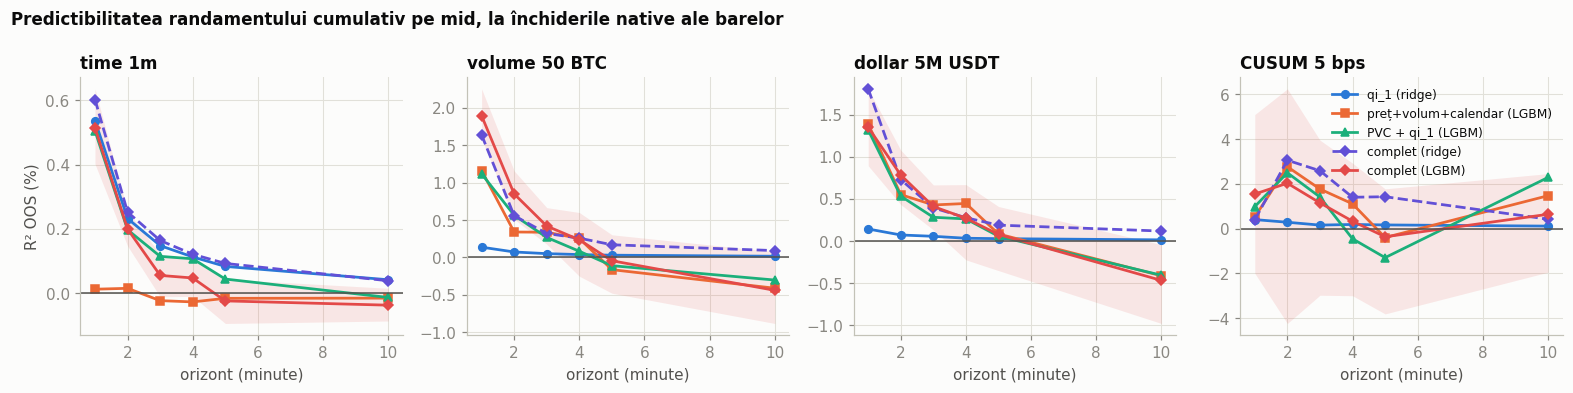

In [17]:
NAT_T = [f"C{h}" for h in CLOCK_H]
NAT = cached("res_native_clock", lambda: results_table("native", SETS, NAT_T, NATIVE_FS))
BAR = cached("res_native_bars", lambda: results_table("native", EVENT_SETS, [f"B{k}" for k in BAR_K], NATIVE_FS))


def wide(T, fs_models, targets, fmt="{:.2f}"):
    out = {}
    for fs, m in fs_models:
        for s in T["set"].unique():
            sub = T[(T["features"] == fs) & (T["model"] == m) & (T["set"] == s)].set_index("țintă")
            out[(s, f"{fs} · {m}")] = {t: f"{sub.at[t, 'r2']:.3f} [{sub.at[t, 'lo']:.2f}, {sub.at[t, 'hi']:.2f}]" for t in targets if t in sub.index}
    return pd.DataFrame(out).T


SHOW = [("QI", "ridge"), ("PVC", "lgb"), ("PVC+QI", "lgb"), ("FULL", "ridge"), ("FULL", "lgb")]
display(Markdown("**R² out-of-sample (%) față de prognoza zero, cu interval bootstrap 95% (blocuri de 5 zile), orizonturi de ceas, eșantion nativ.**"))
display(wide(NAT, SHOW, NAT_T))
display(Markdown("**Robustețe la mișcări extreme: R² OOS (%) pe ținta winsorizată la limitele 0,1%/99,9% din train ale fiecărui fold (aceleași prognoze).**"))
display(wide(NAT.assign(r2=NAT["r2_clip"], lo=NAT["lo_clip"], hi=NAT["hi_clip"]), SHOW, NAT_T))
display(Markdown("**Eroare, IC și calibrare în bps pentru aceleași celule** (panta 1 = prognoză calibrată; RMSE zero = eroarea prognozei zero)."))
_v = NAT[NAT.apply(lambda r: (r["features"], r["model"]) in [("QI", "ridge"), ("FULL", "ridge"), ("FULL", "lgb")], axis=1)]
display(_v.set_index(["set", "features", "model", "țintă"])[["IC", "panta_calibrare", "RMSE (bps)", "RMSE zero (bps)", "|f| mediu (bps)", "luni_poz", "n"]]
        .unstack("țintă").loc[:, (["IC", "panta_calibrare", "RMSE (bps)", "luni_poz"], NAT_T)].round(3))

MODEL_STYLE = {("QI", "ridge"): (C["blue"], "-", "o"), ("PVC", "lgb"): (C["orange"], "-", "s"), ("PVC+QI", "lgb"): (C["aqua"], "-", "^"),
               ("FULL", "ridge"): (C["violet"], "--", "D"), ("FULL", "lgb"): (C["red"], "-", "D")}
MODEL_LABEL = {("QI", "ridge"): "qi_1 (ridge)", ("PVC", "lgb"): "preț+volum+calendar (LGBM)", ("PVC+QI", "lgb"): "PVC + qi_1 (LGBM)",
               ("FULL", "ridge"): "complet (ridge)", ("FULL", "lgb"): "complet (LGBM)"}


def plot_r2_curves(T, targets, xvals, xlabel, sets, title):
    fig, axes = plt.subplots(1, len(sets), figsize=(3.6 * len(sets), 3.6), sharey=False)      # own scale per set: CUSUM intervals would flatten time_1m
    axes = np.atleast_1d(axes)
    for ax, s in zip(axes, sets):
        for key, (col, ls, mk) in MODEL_STYLE.items():
            sub = T[(T["set"] == s) & (T["features"] == key[0]) & (T["model"] == key[1])].set_index("țintă").reindex(targets)
            ax.plot(xvals, sub["r2"], color=col, ls=ls, marker=mk, ms=5, lw=1.8, label=MODEL_LABEL[key])
            if key == ("FULL", "lgb"):
                ax.fill_between(xvals, sub["lo"], sub["hi"], color=col, alpha=0.12, lw=0)
        ax.axhline(0, color=INK2, lw=1)
        ax.set_title(LABEL[s])
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel("R² OOS (%)")
    axes[-1].legend(loc="upper right", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout()
    plt.show()


plot_r2_curves(NAT, NAT_T, CLOCK_H, "orizont (minute)", SETS, "Predictibilitatea randamentului cumulativ pe mid, la închiderile native ale barelor")

**Ce arată tabelele (eșantion nativ, ceas).**

* **`time_1m`:** `qi_1` singur (ridge) atinge R² 0,54% la 1 minut, 0,23% la 2 minute, 0,08% la 5 minute și 0,04% la 10 minute, cu intervale care exclud zero la toate orizonturile și 13/13 luni pozitive. Prețul, volumul și calendarul nu aduc nimic (R² ≈ 0). Modelul complet adaugă puțin peste `qi_1` (ridge: 0,60% la 1 minut), iar LightGBM complet rămâne *sub* `qi_1` liniar la toate orizonturile: cu ~355 de features și un semnal atât de slab, flexibilitatea costă mai mult decât aduce.
* **Barele volume și dollar:** R² mult mai mare la 1 minut (1,3–1,9%) și la 2 minute (0,56–0,85%), dar `qi_1` singur dă doar 0,14% la 1 minut; diferența vine din alte familii (secțiunea 13). De la 5 minute în sus, intervalele includ zero, iar la 10 minute LightGBM devine negativ.
* **CUSUM:** intervalele sunt de câteva puncte procentuale și includ zero pentru modelele complet și PVC, chiar și la 1 minut; doar `qi_1` este stabil (0,40% la 1 minut). Secțiunea 10.4 arată de ce.
* **Robustețe:** pe ținta winsorizată la limitele din train, cifrele cresc ușor, dar ordinea și concluziile nu se schimbă.
* **Calibrare:** prognoza `qi_1` are panta ≈ 1 (calibrată în bps); modelele complete sunt supra-încrezătoare (panta 0,8–0,9 la 1–2 minute, sub 0,5 pentru LightGBM la 5–10 minute).

In [18]:
def increments(kind, sets, targets):
    rows = []
    for s in sets:
        for t in targets:
            D = {fs: cell_data(kind, s, t, fs) for fs in ["QI", "PVC", "PVC+QI", "FULL"]}
            for m in ("ridge", "lgb"):
                for a_, b_ in [("FULL", "PVC+QI"), ("PVC+QI", "PVC"), ("FULL", "PVC")]:
                    da, db = D[a_], D[b_]
                    assert np.array_equal(da["row"].to_numpy(), db["row"].to_numpy())
                    rc = r2_stats(da.assign(y=da["yc"]), m, base=db[m].to_numpy())
                    rows.append({"set": s, "țintă": t, "model": m, "comparație": f"{a_} − {b_}", **r2_stats(da, m, base=db[m].to_numpy()),
                                 "r2_clip": rc["r2"], "lo_clip": rc["lo"], "hi_clip": rc["hi"], "p_clip": rc["p"]})
    T = pd.DataFrame(rows)
    T["p_holm"], T["p_holm_clip"] = np.nan, np.nan
    for (m, cmp), g in T.groupby(["model", "comparație"]):
        T.loc[g.index, "p_holm"] = holm(g["p"].to_numpy())
        T.loc[g.index, "p_holm_clip"] = holm(g["p_clip"].to_numpy())
    return T


INC = cached("res_increments", lambda: increments("native", SETS, NAT_T))
INC_B = cached("res_increments_bars", lambda: increments("native", EVENT_SETS, [f"B{k}" for k in BAR_K]))


def inc_view(T, m, clip=False):
    v = T[T["model"] == m].copy()
    if clip:
        v = v.assign(r2=v["r2_clip"], lo=v["lo_clip"], hi=v["hi_clip"], p_holm=v["p_holm_clip"])
    v["ΔR² [IC 95%]"] = v.apply(lambda r: f"{r['r2']:+.3f} [{r['lo']:+.2f}, {r['hi']:+.2f}]{'*' if r['p_holm'] < 0.05 else ''}", axis=1)
    return v.pivot_table(index=["comparație", "set"], columns="țintă", values="ΔR² [IC 95%]", aggfunc="first")[[t for t in T["țintă"].unique()]]


display(Markdown("**Increment de R² (puncte procentuale), LightGBM, același eșantion; `*` = Holm p < 0,05 pe familia de 24 de comparații a rândului.**"))
display(inc_view(INC, "lgb"))
display(Markdown("**Același tabel pentru ridge.**"))
display(inc_view(INC, "ridge"))
display(Markdown("**Robustețe: incrementele LightGBM pe ținta winsorizată la limitele din train.**"))
display(inc_view(INC, "lgb", clip=True))

**Increment de R² (puncte procentuale), LightGBM, același eșantion; `*` = Holm p < 0,05 pe familia de 24 de comparații a rândului.**

țintă                                            C1                      C2                      C3                      C4                      C5                    C10
comparație    set                                                                                                                                                         
FULL − PVC    cusum_5bps      +1.025 [-0.03, +2.24]   -0.737 [-2.73, +1.06]   -0.620 [-2.03, +0.97]   -0.777 [-2.14, +0.74]   +0.033 [-1.85, +2.33]  -0.831 [-2.02, -0.03]
              dollar_5musdt   -0.040 [-0.46, +0.34]   +0.232 [+0.03, +0.42]   -0.018 [-0.32, +0.22]   -0.176 [-0.49, +0.08]   -0.006 [-0.35, +0.31]  -0.055 [-0.37, +0.33]
              time_1m        +0.502 [+0.41, +0.61]*  +0.185 [+0.14, +0.24]*   +0.078 [+0.02, +0.14]   +0.074 [+0.02, +0.14]   -0.008 [-0.07, +0.06]  -0.022 [-0.10, +0.06]
              volume_50btc   +0.732 [+0.57, +0.91]*  +0.509 [+0.29, +0.71]*   +0.082 [-0.16, +0.32]   -0.018 [-0.42, +0.34]   +0.119 [-0.34, +0.75]  -0.029 [-0.44, +0.43]
FULL − PVC+QI cusum_5bps      +0.563 [-0.66, +2.13]   -0.466 [-2.06, +1.20]   -0.261 [-1.43, +1.29]   +0.787 [-1.35, +4.11]   +0.932 [-1.22, +3.21]  -1.647 [-3.16, -0.71]
              dollar_5musdt   +0.032 [-0.33, +0.37]   +0.250 [-0.00, +0.50]   +0.128 [-0.20, +0.53]   +0.007 [-0.38, +0.39]   +0.021 [-0.32, +0.35]  -0.061 [-0.41, +0.33]
              time_1m         +0.009 [-0.03, +0.05]   +0.003 [-0.03, +0.03]   -0.059 [-0.11, -0.01]   -0.060 [-0.11, -0.01]   -0.068 [-0.13, -0.00]  -0.024 [-0.10, +0.06]
              volume_50btc   +0.777 [+0.57, +1.01]*  +0.285 [+0.10, +0.52]*   +0.152 [-0.09, +0.40]   +0.153 [-0.24, +0.49]   +0.066 [-0.28, +0.35]  -0.138 [-0.56, +0.35]
PVC+QI − PVC  cusum_5bps      +0.462 [-0.30, +1.12]   -0.271 [-1.15, +0.63]   -0.359 [-1.41, +0.64]   -1.564 [-3.77, -0.14]   -0.899 [-2.00, +0.20]  +0.816 [+0.11, +1.75]
              dollar_5musdt   -0.071 [-0.23, +0.08]   -0.018 [-0.26, +0.22]   -0.146 [-0.48, +0.10]   -0.183 [-0.44, +0.08]   -0.027 [-0.16, +0.10]  +0.006 [-0.37, +0.44]
              time_1m        +0.493 [+0.42, +0.57]*  +0.182 [+0.14, +0.22]*  +0.138 [+0.11, +0.17]*  +0.134 [+0.10, +0.17]*  +0.060 [+0.02, +0.09]*  +0.002 [-0.05, +0.05]
              volume_50btc    -0.045 [-0.25, +0.11]   +0.224 [+0.02, +0.41]   -0.070 [-0.29, +0.20]   -0.171 [-0.47, +0.12]   +0.053 [-0.36, +0.65]  +0.109 [-0.15, +0.32]

**Același tabel pentru ridge.**

țintă                                            C1                      C2                        C3                      C4                      C5                     C10
comparație    set                                                                                                                                                            
FULL − PVC    cusum_5bps      +0.770 [-0.54, +1.93]   +0.568 [-1.50, +2.15]  +15.973 [+1.89, +30.42]*  +7.934 [-0.00, +16.07]   +3.280 [-0.93, +6.79]   +2.667 [-1.16, +5.65]
              dollar_5musdt  +0.924 [+0.62, +1.20]*  +0.414 [+0.15, +0.68]*     +0.240 [+0.07, +0.41]   +0.237 [+0.07, +0.41]   +0.253 [+0.07, +0.44]   +0.230 [+0.03, +0.48]
              time_1m        +0.576 [+0.50, +0.66]*  +0.212 [+0.17, +0.26]*    +0.132 [+0.10, +0.17]*  +0.080 [+0.05, +0.11]*  +0.080 [+0.04, +0.12]*   +0.054 [-0.00, +0.10]
              volume_50btc   +0.766 [+0.38, +1.11]*   +0.203 [-0.07, +0.46]     +0.206 [-0.02, +0.44]   +0.167 [+0.00, +0.35]   +0.169 [+0.00, +0.34]   +0.182 [-0.05, +0.41]
FULL − PVC+QI cusum_5bps      +0.842 [-0.50, +2.01]   -0.626 [-2.36, +1.15]   +13.544 [+1.78, +25.48]  +7.479 [+0.04, +15.05]   +2.289 [-0.93, +4.73]   +2.288 [-1.26, +4.96]
              dollar_5musdt  +0.910 [+0.62, +1.17]*  +0.393 [+0.14, +0.64]*     +0.227 [+0.04, +0.41]   +0.244 [+0.10, +0.39]   +0.191 [+0.02, +0.38]   +0.183 [-0.01, +0.42]
              time_1m        +0.072 [+0.03, +0.11]*   +0.029 [+0.00, +0.06]     +0.019 [-0.01, +0.04]   +0.007 [-0.03, +0.04]   +0.014 [-0.02, +0.05]   +0.023 [-0.03, +0.07]
              volume_50btc   +0.774 [+0.39, +1.12]*   +0.194 [-0.08, +0.46]     +0.184 [-0.03, +0.39]   +0.196 [+0.03, +0.38]   +0.147 [-0.03, +0.33]   +0.171 [-0.05, +0.40]
PVC+QI − PVC  cusum_5bps      -0.071 [-0.16, +0.01]  +1.194 [+0.06, +2.48]*     +2.429 [-0.04, +5.04]   +0.455 [-0.12, +1.08]   +0.992 [-0.01, +2.15]  +0.379 [+0.03, +0.72]*
              dollar_5musdt   +0.014 [-0.02, +0.06]   +0.022 [-0.00, +0.05]     +0.013 [-0.03, +0.06]   -0.007 [-0.09, +0.06]   +0.062 [+0.01, +0.12]  +0.047 [+0.01, +0.09]*
              time_1m        +0.504 [+0.44, +0.57]*  +0.183 [+0.15, +0.22]*    +0.113 [+0.09, +0.14]*  +0.073 [+0.05, +0.09]*  +0.067 [+0.05, +0.08]*  +0.032 [+0.02, +0.04]*
              volume_50btc    -0.008 [-0.04, +0.02]   +0.009 [-0.02, +0.04]     +0.022 [-0.02, +0.07]   -0.029 [-0.07, +0.00]   +0.023 [-0.03, +0.08]   +0.011 [-0.02, +0.04]

**Robustețe: incrementele LightGBM pe ținta winsorizată la limitele din train.**

țintă                                            C1                      C2                      C3                      C4                      C5                    C10
comparație    set                                                                                                                                                         
FULL − PVC    cusum_5bps      +1.066 [-0.04, +2.33]   -0.838 [-2.87, +0.98]   -0.615 [-2.05, +0.99]   -0.752 [-2.17, +0.81]   +0.226 [-1.81, +2.53]  -0.915 [-2.08, -0.02]
              dollar_5musdt   -0.066 [-0.54, +0.37]   +0.257 [+0.06, +0.43]   +0.034 [-0.26, +0.26]   -0.159 [-0.48, +0.12]   +0.010 [-0.34, +0.34]  -0.069 [-0.40, +0.33]
              time_1m        +0.540 [+0.44, +0.64]*  +0.196 [+0.15, +0.25]*   +0.083 [+0.02, +0.15]   +0.076 [+0.02, +0.14]   -0.006 [-0.07, +0.06]  -0.016 [-0.09, +0.07]
              volume_50btc   +0.818 [+0.68, +0.98]*  +0.543 [+0.33, +0.74]*   +0.109 [-0.13, +0.35]   -0.018 [-0.42, +0.35]   +0.134 [-0.34, +0.77]  -0.018 [-0.42, +0.41]
FULL − PVC+QI cusum_5bps      +0.596 [-0.66, +2.20]   -0.541 [-2.16, +1.09]   -0.248 [-1.43, +1.32]   +0.920 [-1.26, +4.31]   +1.098 [-1.18, +3.38]  -1.788 [-3.24, -0.76]
              dollar_5musdt   +0.015 [-0.39, +0.40]   +0.313 [+0.06, +0.56]   +0.169 [-0.17, +0.57]   +0.053 [-0.36, +0.46]   +0.027 [-0.32, +0.36]  -0.081 [-0.44, +0.32]
              time_1m         +0.001 [-0.04, +0.05]   -0.005 [-0.04, +0.03]   -0.062 [-0.12, -0.01]   -0.067 [-0.12, -0.01]   -0.077 [-0.15, -0.01]  -0.029 [-0.11, +0.06]
              volume_50btc   +0.876 [+0.66, +1.11]*  +0.344 [+0.16, +0.57]*   +0.194 [-0.01, +0.42]   +0.151 [-0.24, +0.50]   +0.072 [-0.30, +0.38]  -0.124 [-0.53, +0.33]
PVC+QI − PVC  cusum_5bps      +0.470 [-0.28, +1.13]   -0.296 [-1.19, +0.63]   -0.367 [-1.44, +0.64]   -1.671 [-3.93, -0.19]   -0.872 [-2.00, +0.23]  +0.873 [+0.11, +1.81]
              dollar_5musdt   -0.081 [-0.25, +0.08]   -0.056 [-0.29, +0.18]   -0.135 [-0.48, +0.12]   -0.212 [-0.48, +0.05]   -0.016 [-0.17, +0.11]  +0.012 [-0.38, +0.47]
              time_1m        +0.539 [+0.47, +0.62]*  +0.201 [+0.16, +0.24]*  +0.146 [+0.11, +0.18]*  +0.144 [+0.11, +0.18]*  +0.070 [+0.03, +0.11]*  +0.013 [-0.04, +0.06]
              volume_50btc    -0.058 [-0.28, +0.11]   +0.199 [+0.01, +0.38]   -0.085 [-0.29, +0.14]   -0.169 [-0.46, +0.12]   +0.062 [-0.36, +0.67]  +0.106 [-0.15, +0.32]

**Ce aduce microstructura.**

* **Peste preț, volum și calendar** (`FULL − PVC`): pe `time_1m`, +0,50–0,58 pp la 1 minut și +0,19–0,21 pp la 2 minute (semnificative după Holm), aproape în întregime prin `qi_1` (`PVC+QI − PVC` dă +0,49–0,50 pp). Pe volume, +0,73–0,77 pp la 1 minut și +0,5 pp la 2 minute în LightGBM.
* **Peste imbalance-ul curent** (`FULL − PVC+QI`): pe `time_1m`, +0,07 pp la 1 minut doar în ridge, iar în LightGBM zero; de la 3 minute este zero sau negativ. Pe volume și dollar, +0,8–0,9 pp la 1 minut (ridge și LightGBM pe volume; doar ridge pe dollar, unde LightGBM complet e mai slab), +0,2–0,4 pp la 2 minute (semnificativ doar într-unul din cele două modele), apoi nimic semnificativ după Holm.
* **Imbalance-ul peste PVC** contează mult pe `time_1m` și deloc pe barele volume/dollar: la închiderea unei bare de evenimente, informația lui `qi_1` este deja conținută în traiectoria și fluxul ultimelor tranzacții.

Pe CUSUM, incrementele sunt instabile și nu trec corecția (cu excepția artefactelor ridge, unde modelul PVC are R² puternic negativ).

**R² OOS (%) pentru randamentul până la închiderea barei t+k, același set (pentru `time 1m`, k bare = k minute).**

,,B1,B2,B3,B4,B5
volume_50btc,QI · ridge,"1.235 [1.08, 1.42]","0.598 [0.52, 0.69]","0.377 [0.33, 0.44]","0.277 [0.24, 0.32]","0.216 [0.18, 0.26]"
dollar_5musdt,QI · ridge,"0.947 [0.80, 1.12]","0.454 [0.37, 0.55]","0.275 [0.22, 0.34]","0.192 [0.15, 0.24]","0.160 [0.12, 0.20]"
cusum_5bps,QI · ridge,"6.695 [6.24, 7.12]","3.215 [2.97, 3.45]","1.994 [1.83, 2.15]","1.459 [1.34, 1.59]","1.127 [1.03, 1.23]"
time_1m,QI · ridge,"0.537 [0.45, 0.63]","0.232 [0.20, 0.27]","0.148 [0.12, 0.18]","0.113 [0.09, 0.14]","0.083 [0.07, 0.10]"
volume_50btc,PVC · lgb,"5.602 [5.27, 5.98]","3.815 [3.60, 4.06]","2.852 [2.69, 3.03]","2.320 [2.19, 2.47]","1.923 [1.80, 2.06]"
dollar_5musdt,PVC · lgb,"4.844 [4.53, 5.21]","3.170 [2.95, 3.42]","2.405 [2.24, 2.60]","1.940 [1.80, 2.11]","1.591 [1.46, 1.74]"
cusum_5bps,PVC · lgb,"13.063 [12.23, 13.90]","6.496 [6.00, 7.01]","4.175 [3.82, 4.55]","3.055 [2.76, 3.35]","2.356 [2.12, 2.59]"
time_1m,PVC · lgb,"0.012 [-0.04, 0.06]","0.015 [-0.02, 0.05]","-0.023 [-0.07, 0.03]","-0.027 [-0.08, 0.02]","-0.016 [-0.08, 0.04]"
volume_50btc,PVC+QI · lgb,"5.948 [5.60, 6.35]","3.939 [3.71, 4.19]","2.905 [2.74, 3.10]","2.371 [2.24, 2.53]","1.944 [1.82, 2.08]"
dollar_5musdt,PVC+QI · lgb,"5.060 [4.71, 5.46]","3.270 [3.05, 3.54]","2.434 [2.25, 2.65]","1.969 [1.83, 2.14]","1.603 [1.47, 1.76]"


**Același tabel pe ținta winsorizată la limitele din train.**

,,B1,B2,B3,B4,B5
volume_50btc,QI · ridge,"1.251 [1.10, 1.43]","0.604 [0.53, 0.70]","0.380 [0.33, 0.44]","0.280 [0.24, 0.32]","0.218 [0.18, 0.26]"
dollar_5musdt,QI · ridge,"0.961 [0.82, 1.12]","0.461 [0.38, 0.55]","0.279 [0.22, 0.34]","0.194 [0.15, 0.24]","0.162 [0.13, 0.20]"
cusum_5bps,QI · ridge,"6.816 [6.34, 7.26]","3.242 [3.00, 3.48]","2.004 [1.84, 2.16]","1.463 [1.34, 1.59]","1.128 [1.03, 1.23]"
time_1m,QI · ridge,"0.588 [0.50, 0.68]","0.254 [0.22, 0.29]","0.158 [0.13, 0.19]","0.120 [0.10, 0.14]","0.089 [0.07, 0.11]"
volume_50btc,PVC · lgb,"5.647 [5.33, 6.00]","3.843 [3.64, 4.07]","2.867 [2.71, 3.05]","2.330 [2.20, 2.48]","1.931 [1.81, 2.06]"
dollar_5musdt,PVC · lgb,"4.902 [4.59, 5.24]","3.207 [2.99, 3.44]","2.425 [2.26, 2.61]","1.953 [1.81, 2.12]","1.592 [1.46, 1.74]"
cusum_5bps,PVC · lgb,"13.150 [12.28, 14.02]","6.478 [5.98, 6.99]","4.152 [3.79, 4.52]","3.043 [2.75, 3.34]","2.349 [2.12, 2.58]"
time_1m,PVC · lgb,"0.026 [-0.03, 0.07]","0.032 [-0.00, 0.07]","-0.008 [-0.06, 0.04]","-0.020 [-0.08, 0.03]","-0.012 [-0.08, 0.05]"
volume_50btc,PVC+QI · lgb,"5.997 [5.66, 6.40]","3.967 [3.75, 4.21]","2.921 [2.75, 3.11]","2.381 [2.25, 2.54]","1.950 [1.83, 2.09]"
dollar_5musdt,PVC+QI · lgb,"5.122 [4.78, 5.51]","3.308 [3.09, 3.57]","2.453 [2.28, 2.66]","1.981 [1.84, 2.15]","1.609 [1.47, 1.76]"


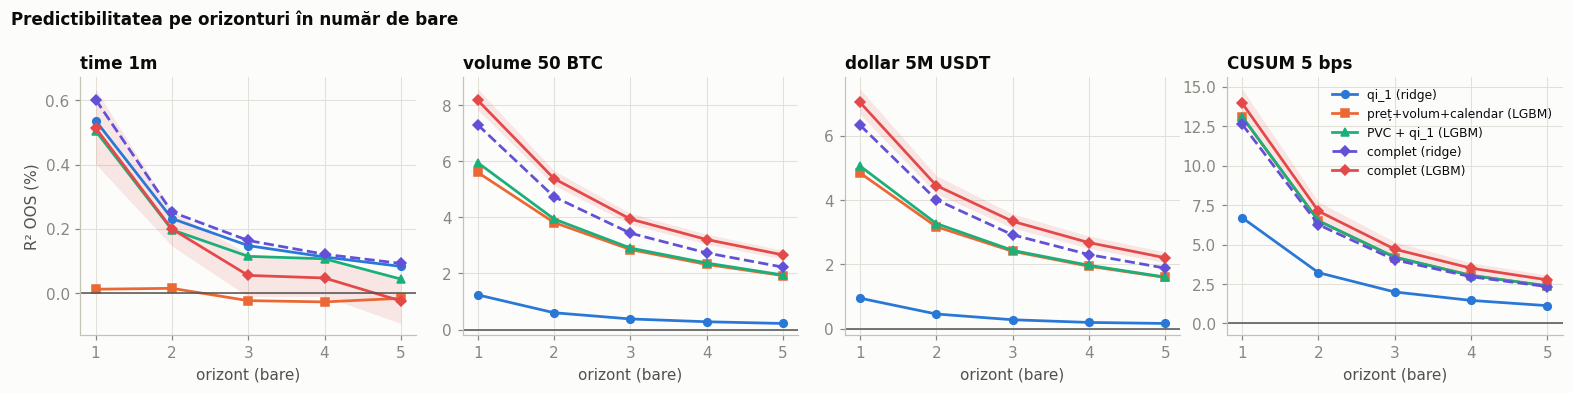

**Increment de R² pe orizonturi în bare (LightGBM; al doilea tabel: ținta winsorizată).**

țintă                                            B1                      B2                      B3                      B4                      B5
comparație    set                                                                                                                                  
FULL − PVC    cusum_5bps     +0.886 [+0.79, +0.97]*  +0.612 [+0.52, +0.70]*  +0.526 [+0.42, +0.62]*  +0.445 [+0.36, +0.52]*  +0.404 [+0.32, +0.48]*
              dollar_5musdt  +2.196 [+2.08, +2.31]*  +1.282 [+1.20, +1.37]*  +0.933 [+0.87, +1.01]*  +0.734 [+0.66, +0.81]*  +0.613 [+0.54, +0.68]*
              volume_50btc   +2.570 [+2.46, +2.67]*  +1.564 [+1.49, +1.63]*  +1.087 [+1.02, +1.15]*  +0.889 [+0.83, +0.95]*  +0.737 [+0.69, +0.79]*
FULL − PVC+QI cusum_5bps     +0.847 [+0.76, +0.93]*  +0.612 [+0.52, +0.70]*  +0.492 [+0.41, +0.57]*  +0.468 [+0.39, +0.54]*  +0.372 [+0.30, +0.44]*
              dollar_5musdt  +1.980 [+1.86, +2.10]*  +1.182 [+1.09, +1.26]*  +0.904 [+0.81, +0.99]*  +0.705 [+0.63, +0.78]*  +0.601 [+0.53, +0.66]*
              volume_50btc   +2.224 [+2.10, +2.34]*  +1.440 [+1.36, +1.51]*  +1.033 [+0.97, +1.10]*  +0.839 [+0.77, +0.90]*  +0.716 [+0.66, +0.77]*
PVC+QI − PVC  cusum_5bps     +0.039 [+0.01, +0.06]*   -0.000 [-0.02, +0.02]  +0.034 [+0.01, +0.06]*   -0.023 [-0.05, +0.01]  +0.032 [+0.01, +0.06]*
              dollar_5musdt  +0.216 [+0.15, +0.29]*  +0.100 [+0.06, +0.14]*   +0.029 [-0.03, +0.08]   +0.029 [+0.00, +0.06]   +0.012 [-0.02, +0.04]
              volume_50btc   +0.346 [+0.29, +0.41]*  +0.124 [+0.09, +0.16]*  +0.054 [+0.03, +0.08]*  +0.050 [+0.03, +0.08]*   +0.021 [-0.01, +0.05]

țintă                                            B1                      B2                      B3                      B4                      B5
comparație    set                                                                                                                                  
FULL − PVC    cusum_5bps     +0.847 [+0.76, +0.93]*  +0.578 [+0.49, +0.66]*  +0.504 [+0.41, +0.60]*  +0.433 [+0.35, +0.50]*  +0.398 [+0.31, +0.48]*
              dollar_5musdt  +2.217 [+2.10, +2.33]*  +1.290 [+1.21, +1.38]*  +0.945 [+0.88, +1.02]*  +0.742 [+0.66, +0.82]*  +0.625 [+0.55, +0.70]*
              volume_50btc   +2.586 [+2.48, +2.69]*  +1.570 [+1.50, +1.64]*  +1.093 [+1.03, +1.15]*  +0.897 [+0.84, +0.95]*  +0.742 [+0.69, +0.79]*
FULL − PVC+QI cusum_5bps     +0.808 [+0.72, +0.89]*  +0.579 [+0.49, +0.66]*  +0.470 [+0.39, +0.55]*  +0.456 [+0.38, +0.52]*  +0.366 [+0.30, +0.43]*
              dollar_5musdt  +1.997 [+1.86, +2.13]*  +1.189 [+1.09, +1.27]*  +0.916 [+0.82, +1.01]*  +0.714 [+0.63, +0.79]*  +0.609 [+0.53, +0.67]*
              volume_50btc   +2.236 [+2.11, +2.35]*  +1.446 [+1.36, +1.52]*  +1.039 [+0.97, +1.10]*  +0.846 [+0.78, +0.91]*  +0.723 [+0.66, +0.78]*
PVC+QI − PVC  cusum_5bps     +0.039 [+0.01, +0.06]*   -0.001 [-0.02, +0.02]  +0.035 [+0.01, +0.06]*   -0.023 [-0.05, +0.01]  +0.032 [+0.01, +0.06]*
              dollar_5musdt  +0.220 [+0.16, +0.29]*  +0.102 [+0.07, +0.14]*   +0.028 [-0.03, +0.08]   +0.027 [-0.00, +0.06]   +0.016 [-0.02, +0.05]
              volume_50btc   +0.350 [+0.29, +0.41]*  +0.124 [+0.09, +0.16]*  +0.054 [+0.03, +0.08]*  +0.051 [+0.03, +0.08]*   +0.019 [-0.01, +0.05]

In [19]:
display(Markdown("**R² OOS (%) pentru randamentul până la închiderea barei t+k, același set (pentru `time 1m`, k bare = k minute).**"))
BAR_ALL = pd.concat([BAR, NAT[NAT["set"] == "time_1m"].assign(țintă=lambda d: d["țintă"].str.replace("C", "B"))
                     [lambda d: d["țintă"].isin([f"B{k}" for k in BAR_K])]], ignore_index=True)
display(wide(BAR_ALL, SHOW, [f"B{k}" for k in BAR_K]))
display(Markdown("**Același tabel pe ținta winsorizată la limitele din train.**"))
display(wide(BAR_ALL.assign(r2=BAR_ALL["r2_clip"], lo=BAR_ALL["lo_clip"], hi=BAR_ALL["hi_clip"]), SHOW, [f"B{k}" for k in BAR_K]))
plot_r2_curves(BAR_ALL, [f"B{k}" for k in BAR_K], BAR_K, "orizont (bare)", SETS, "Predictibilitatea pe orizonturi în număr de bare")
display(Markdown("**Increment de R² pe orizonturi în bare (LightGBM; al doilea tabel: ținta winsorizată).**"))
display(inc_view(INC_B, "lgb"))
display(inc_view(INC_B, "lgb", clip=True))

**Orizonturi în bare.** Pe bara următoare, R² urcă la 7–8% (volume, dollar) și 13–14% (CUSUM), apoi scade monoton până la 2–3% la cinci bare. Pe barele de evenimente, PVC singur explică o mare parte (4,8–5,6% pe volume/dollar, 13% pe CUSUM), iar microstructura adaugă încă 2–2,6 pp (volume/dollar) la k = 1. Aceste cifre sunt de un ordin de mărime peste cele de ceas, însă orizontul real este de câteva secunde (secțiunea 8), iar următoarea verificare arată că nu sunt executabile.

In [20]:
rows = []
for s in EVENT_SETS:
    d = cell_data("native", s, "B1", "FULL")
    Y = TG[s]["Y"]
    r = d["row"].to_numpy()
    dur1 = TG[s]["dur"]["B1"][r]
    for delay in [0.0] + DELAYS[:3]:
        if delay == 0:
            yd = d["y"].to_numpy()
            keep = np.ones(len(d), bool)
        else:
            jump = (Y["C1"][r] - Y[f"D{delay:g}_C1"][r]).astype(np.float64)     # mid move from T to T+delay
            yd = d["y"].to_numpy() - jump
            keep = dur1 > delay
        dd = d.assign(y=yd)[keep & np.isfinite(yd)]
        for m in ("ridge", "lgb"):
            rows.append({"set": s, "întârziere (s)": delay, "model": m, "rânduri păstrate %": 100 * keep.mean(), **r2_stats(dd, m)})
    lt = cell_data("native", s, "LT_B1", "FULL")
    lt_pvc = cell_data("native", s, "LT_B1", "PVC")
    for m in ("ridge", "lgb"):
        rows.append({"set": s, "întârziere (s)": "ținta pe ultimul trade", "model": m, "rânduri păstrate %": 100.0, **r2_stats(lt, m)})
        rows.append({"set": s, "întârziere (s)": "ultimul trade, doar PVC", "model": m, "rânduri păstrate %": 100.0, **r2_stats(lt_pvc, m)})
BURST = pd.DataFrame(rows)
display(Markdown("**Bara următoare (k = 1): R² al modelului complet antrenat pe ținta mid→mid, evaluat cu startul întârziat cu δ (mid la T+δ → mid la închiderea barei t+1), "
                 "numai pe rândurile unde bara t+1 se închide după T+δ; ultimele rânduri: modele reantrenate pe ținta pe ultimul trade (bar_close).**"))
display(BURST.pivot_table(index=["set", "întârziere (s)"], columns="model", values=["r2", "rânduri păstrate %"], aggfunc="first").round(3))

**Bara următoare (k = 1): R² al modelului complet antrenat pe ținta mid→mid, evaluat cu startul întârziat cu δ (mid la T+δ → mid la închiderea barei t+1), numai pe rândurile unde bara t+1 se închide după T+δ; ultimele rânduri: modele reantrenate pe ținta pe ultimul trade (bar_close).**

r2         rânduri păstrate %         
model                                     lgb   ridge                lgb    ridge
set           întârziere (s)                                                     
cusum_5bps    0.0                      13.949  12.612            100.000  100.000
              0.1                       0.487   0.646             76.356   76.356
              1.0                     -15.885 -15.144             70.360   70.360
              5.0                     -19.269 -19.107             54.914   54.914
              ultimul trade, doar PVC  51.195  50.999            100.000  100.000
              ținta pe ultimul trade   51.380  52.269            100.000  100.000
dollar_5musdt 0.0                       7.040   6.334            100.000  100.000
              0.1                       1.055   0.777             95.020   95.020
              1.0                      -5.800  -5.567             89.450   89.450
              5.0                      -7.472  -7.212             76.383   76.383
              ultimul trade, doar PVC   1.781   0.788            100.000  100.000
              ținta pe ultimul trade    3.099   2.457            100.000  100.000
volume_50btc  0.0                       8.172   7.297            100.000  100.000
              0.1                       1.240   1.004             93.362   93.362
              1.0                      -7.029  -6.502             86.817   86.817
              5.0                      -9.327  -8.722             71.517   71.517
              ultimul trade, doar PVC   2.157   0.978            100.000  100.000
              ținta pe ultimul trade    3.824   3.046            100.000  100.000

**Scorul pe bara următoare nu este un semnal executabil.** Aceeași prognoză, evaluată pe mișcarea dintre `T + δ` și închiderea barei următoare:

| | δ = 0 | δ = 100 ms | δ = 1 s | δ = 5 s |
|---|---|---|---|---|
| volume (LightGBM) | 8,2% | 1,2% | −7,0% | −9,3% |
| dollar | 7,0% | 1,1% | −5,8% | −7,5% |
| CUSUM | 13,9% | 0,5% | −15,9% | −19,3% |

Peste 85% din R² dispare în primele 100 ms, iar după o secundă prognoza devine dăunătoare: mișcarea anticipată s-a produs deja, iar prognoza o mai pariază o dată. (Rândurile cu bara următoare închisă înainte de `T + δ` nu au țintă; diagnosticul e condiționat de durată, deci doar descriptiv.)

**Ținta pe ultimul trade este o altă capcană.** Pe volume și dollar, R² pe `bar_close` (2,5–3,8%) este sub cel pe mid, iar pe CUSUM sare la 51–52% chiar și doar cu PVC: bara CUSUM se închide când prețul tranzacției a parcurs ±5 bps, iar ultimul trade al barei următoare este legat mecanic de aceeași construcție. Aceasta explică ordinul de mărime al R² din notebook-urile `predictibility_test*` și arată de ce ținta trebuie să fie pe mid.

In [21]:
rows = []
for s in SETS:
    for t in ["C1", "C2", "C5"] + (["B1", "B5"] if s != "time_1m" else []):
        for fs, m in [("QI", "ridge"), ("PVC", "lgb"), ("FULL", "ridge"), ("FULL", "lgb")]:
            d = cell_data("native", s, t, fs)
            A, Bm = daily_sums(d, d[m].to_numpy())
            gain = A - Bm
            top = np.argsort(-np.abs(gain))[:5]
            keep = np.ones(ND, bool)
            keep[top] = False
            rows.append({"set": s, "țintă": t, "model": f"{fs} · {m}", "R² (%)": 100 * gain.sum() / A.sum(),
                         "R² fără cele 5 zile cele mai influente (%)": 100 * gain[keep].sum() / A[keep].sum(),
                         "pondere a celor 5 zile în Σy² (%)": 100 * A[top].sum() / A.sum(),
                         "zilele": ", ".join(str(EVAL_DAYS[i].date()) for i in top[:3]) + " …"})
INFL = pd.DataFrame(rows)
display(Markdown("**Influența câtorva zile: R² OOS recalculat fără cele 5 zile cu cea mai mare contribuție absolută la câștigul față de prognoza zero.**"))
display(INFL.set_index(["set", "țintă", "model"]).round(3))

**Influența câtorva zile: R² OOS recalculat fără cele 5 zile cu cea mai mare contribuție absolută la câștigul față de prognoza zero.**

R² (%)  R² fără cele 5 zile cele mai influente (%)  pondere a celor 5 zile în Σy² (%)                                zilele
set           țintă model                                                                                                                                    
time_1m       C1    QI · ridge     0.537                                       0.522                              2.508  2026-02-01, 2025-11-20, 2025-11-25 …
                    PVC · lgb      0.012                                       0.029                              5.418  2026-02-05, 2026-02-04, 2025-12-17 …
                    FULL · ridge   0.602                                       0.593                              3.339  2026-06-08, 2025-11-21, 2026-02-01 …
                    FULL · lgb     0.514                                       0.545                              6.477  2026-02-05, 2026-02-04, 2025-11-21 …
              C2    QI · ridge     0.232                                       0.222                              2.232  2026-02-01, 2025-11-20, 2025-11-06 …
                    PVC · lgb      0.015                                       0.029                              6.402  2026-02-06, 2026-06-05, 2025-11-21 …
                    FULL · ridge   0.252                                       0.258                              3.544  2026-02-25, 2026-06-05, 2025-10-15 …
                    FULL · lgb     0.200                                       0.215                              5.103  2026-02-25, 2026-02-26, 2026-02-06 …
              C5    QI · ridge     0.083                                       0.080                              2.904  2026-02-01, 2026-01-30, 2025-11-16 …
                    PVC · lgb     -0.016                                       0.016                              4.733  2026-02-06, 2026-06-04, 2025-12-01 …
                    FULL · ridge   0.092                                       0.112                              7.109  2026-02-05, 2026-02-06, 2026-03-10 …
                    FULL · lgb    -0.024                                      -0.019                              7.351  2026-02-06, 2026-02-12, 2026-02-05 …
volume_50btc  C1    QI · ridge     0.138                                       0.152                             11.748  2026-08-19, 2026-02-05, 2025-12-01 …
                    PVC · lgb      1.163                                       1.040                              8.936  2026-02-05, 2026-01-31, 2026-06-03 …
                    FULL · ridge   1.639                                       1.811                             13.297  2026-02-05, 2026-08-19, 2026-09-21 …
                    FULL · lgb     1.895                                       1.790                              8.793  2026-02-05, 2026-06-03, 2026-07-14 …
              C2    QI · ridge     0.074                                       0.077                             12.929  2026-08-19, 2026-02-05, 2026-02-04 …
                    PVC · lgb      0.341                                       0.485                             13.893  2026-06-25, 2026-02-05, 2026-06-07 …
                    FULL · ridge   0.558                                       0.804                             13.014  2026-08-19, 2026-09-04, 2026-09-18 …
                    FULL · lgb     0.850                                       0.926                             12.311  2026-02-05, 2026-06-05, 2026-06-25 …
              C5    QI · ridge     0.031                                       0.033                             10.574  2026-02-05, 2026-08-19, 2026-02-04 …
                    PVC · lgb     -0.163                                       0.151                              7.318  2026-06-25, 2026-08-21, 2026-09-18 …
                    FULL · ridge   0.170                                       0.236                              7.207  2026-09-18, 2026-06-05, 2026-09-04 …
                    FULL · lgb    -0.044                                       0.128

**Câteva zile domină rezultatele CUSUM.** Pentru CUSUM, cele 5 zile cele mai influente (5–6 februarie 2026, 30 ianuarie, 22 august) reprezintă 14–28% din Σy², iar fără ele R²-ul modelelor complet și PVC devine negativ la 1 și 2 minute (de exemplu LightGBM complet la 1 minut: +1,5% → −2,4%). `qi_1` rămâne stabil (0,40% → 0,36%). Pe `time_1m`, volume și dollar, eliminarea celor 5 zile nu schimbă concluziile. **Rezultatele modelelor complete pe ceas pentru CUSUM nu sunt deci interpretabile**; selecția momentelor CUSUM concentrează eșantionul în câteva episoade violente.

In [22]:
rows = []
for s in ["cusum_5bps"]:
    X = np.load(CACHE / f"feat_{s}" / "X.npy", mmap_mode="r")
    side = np.asarray(X[:, INFO[s]["columns"].index("cusum_trigger_side")])
    tns = META_TNS_ALL[s]
    e = TG[s]["elig"] & ~TG[s]["crash"]
    for fi, (a, b) in enumerate(FOLDS):
        m = e & (tns >= a.value) & (tns < b.value)
        for sd, nm in ((1, "declanșare în sus"), (-1, "declanșare în jos")):
            mm = m & (side == sd)
            rows.append({"fold": f"F{fi + 1}", "parte": nm, "bare": int(mm.sum()), "C1 medie (bps)": np.nanmean(TG[s]["Y"]["C1"][mm]),
                         "C5 medie (bps)": np.nanmean(TG[s]["Y"]["C5"][mm]), "B1 medie (bps)": np.nanmean(TG[s]["Y"]["B1"][mm])})
CUSUM_SIDE = pd.DataFrame(rows)
display(Markdown("**CUSUM 5 bps: randamentul mediu pe mid după închidere, pe direcția declanșării și pe fold.**"))
display(CUSUM_SIDE.pivot_table(index="fold", columns="parte", values=["C1 medie (bps)", "C5 medie (bps)", "B1 medie (bps)"]).round(2))

**CUSUM 5 bps: randamentul mediu pe mid după închidere, pe direcția declanșării și pe fold.**

B1 medie (bps)                      C1 medie (bps)                      C5 medie (bps)                  
parte declanșare în jos declanșare în sus declanșare în jos declanșare în sus declanșare în jos declanșare în sus
fold                                                                                                             
F1                -1.09              1.08              0.01              2.50             -0.56              1.86
F2                -1.05              1.04             -0.59              1.83             -1.62              0.91
F3                -1.09              1.09             -1.28              1.43             -1.62              0.95
F4                -1.01              1.02             -1.37              0.98             -1.47              0.56
F5                -0.93              0.92             -0.26              2.04             -1.57              0.29
F6                -0.81              0.83             -1.32              0.66              0.42              2.16
F7                -0.91              0.89              0.96              2.89             -0.54              1.19

**Asimetria CUSUM persistă în toate foldurile.** După o declanșare în sus, mid-ul crește în medie 0,7–2,9 bps în minutul următor; după una în jos, variază între −1,4 și +1,0 bps. Pe bara următoare efectul este simetric (±1 bps, mecanic). Asimetria la 1 minut este reală în acest eșantion, dar provine din selecția momentelor (închideri după mișcări de 5 bps), are varianță mare și nu se transformă într-un R² stabil (secțiunea 10.4).

## 11. Comparație echitabilă între bare: ceasul comun

Pe închiderile native, fiecare set este evaluat la alte momente: barele de evenimente se închid mai des când piața e activă, iar informația lor are vechime zero. Ceasul comun scoate ambele avantaje: aceleași momente, informație din ultima bară închisă. Descompunerea care urmează separă (A→B) selecția momentelor pentru un predictor fix, (B→C) restul reprezentării la acele momente și (D) costul vechimii.

**Ceas comun: aceleași momente pentru toate seturile, features din ultima bară deja închisă. R² OOS (%) [IC 95%]. `QI_FRESH` = `qi_1` proaspăt la momentul comun (din grila de 100 ms), referința fără reprezentare.**

,,C1,C2,C5,C10
time_1m,QI · ridge,"-0.001 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]"
volume_50btc,QI · ridge,"0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]","-0.001 [-0.00, 0.00]","-0.001 [-0.00, 0.00]"
dollar_5musdt,QI · ridge,"-0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.001 [-0.00, 0.00]","-0.000 [-0.00, 0.00]"
cusum_5bps,QI · ridge,"-0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]"
(toate),QI · ridge,NaN,NaN,NaN,NaN
time_1m,FULL · ridge,"0.002 [-0.01, 0.01]","0.014 [-0.00, 0.03]","0.003 [-0.03, 0.03]","-0.026 [-0.09, 0.03]"
volume_50btc,FULL · ridge,"-0.002 [-0.02, 0.01]","0.016 [0.00, 0.03]","-0.005 [-0.05, 0.03]","-0.045 [-0.11, 0.01]"
dollar_5musdt,FULL · ridge,"0.002 [-0.01, 0.01]","0.012 [-0.00, 0.03]","-0.005 [-0.05, 0.03]","-0.045 [-0.11, 0.01]"
cusum_5bps,FULL · ridge,"0.004 [-0.01, 0.02]","0.012 [-0.01, 0.03]","-0.003 [-0.05, 0.04]","-0.035 [-0.10, 0.02]"
(toate),FULL · ridge,NaN,NaN,NaN,NaN


C1                  C2                  C5                 C10
(toate) QI_FRESH · ridge  0.447 [0.38, 0.52]  0.210 [0.18, 0.25]  0.071 [0.05, 0.09]  0.033 [0.02, 0.05]
        QI_FRESH · lgb    0.450 [0.38, 0.52]  0.210 [0.18, 0.25]  0.067 [0.05, 0.09]  0.026 [0.01, 0.04]

**Ceas comun, ținta winsorizată la limitele din train.**

,,C1,C2,C5,C10
time_1m,QI · ridge,"-0.001 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]"
volume_50btc,QI · ridge,"0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]","-0.001 [-0.00, 0.00]","-0.001 [-0.00, 0.00]"
dollar_5musdt,QI · ridge,"-0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.001 [-0.00, 0.00]","-0.000 [-0.00, 0.00]"
cusum_5bps,QI · ridge,"-0.000 [-0.00, 0.00]","0.001 [-0.00, 0.00]","0.000 [-0.00, 0.00]","-0.000 [-0.00, 0.00]"
(toate),QI · ridge,NaN,NaN,NaN,NaN
time_1m,FULL · ridge,"0.005 [-0.01, 0.02]","0.024 [0.01, 0.04]","0.009 [-0.02, 0.04]","-0.022 [-0.08, 0.03]"
volume_50btc,FULL · ridge,"0.010 [-0.00, 0.02]","0.030 [0.01, 0.05]","0.008 [-0.03, 0.05]","-0.037 [-0.10, 0.02]"
dollar_5musdt,FULL · ridge,"0.008 [-0.00, 0.02]","0.024 [0.01, 0.04]","0.008 [-0.03, 0.04]","-0.036 [-0.10, 0.02]"
cusum_5bps,FULL · ridge,"0.012 [0.00, 0.02]","0.024 [0.00, 0.05]","0.012 [-0.03, 0.05]","-0.023 [-0.08, 0.03]"
(toate),FULL · ridge,NaN,NaN,NaN,NaN


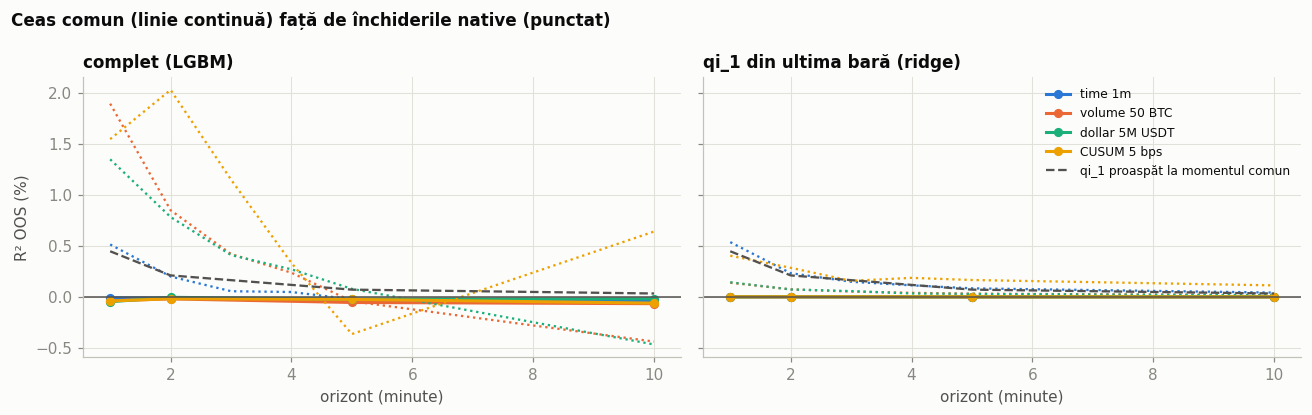

In [23]:
COM_T = [f"C{h}" for h in COMMON_H]
COM = cached("res_common", lambda: pd.concat([results_table("common", SETS, COM_T, ["QI", "FULL"]),
                                               results_table("common", ["time_1m"], COM_T, ["QI_FRESH"]).assign(set="(toate)")], ignore_index=True))
display(Markdown("**Ceas comun: aceleași momente pentru toate seturile, features din ultima bară deja închisă. R² OOS (%) [IC 95%]. "
                 "`QI_FRESH` = `qi_1` proaspăt la momentul comun (din grila de 100 ms), referința fără reprezentare.**"))
display(wide(COM, [("QI", "ridge"), ("FULL", "ridge"), ("FULL", "lgb")], COM_T))
display(wide(COM[COM["features"] == "QI_FRESH"], [("QI_FRESH", "ridge"), ("QI_FRESH", "lgb")], COM_T))
display(Markdown("**Ceas comun, ținta winsorizată la limitele din train.**"))
display(wide(COM.assign(r2=COM["r2_clip"], lo=COM["lo_clip"], hi=COM["hi_clip"]), [("QI", "ridge"), ("FULL", "ridge"), ("FULL", "lgb"), ("QI_FRESH", "ridge")], COM_T))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (fs, m) in zip(axes, [("FULL", "lgb"), ("QI", "ridge")]):
    for s in SETS:
        sub = COM[(COM["set"] == s) & (COM["features"] == fs) & (COM["model"] == m)].set_index("țintă").reindex(COM_T)
        ax.plot(COMMON_H, sub["r2"], color=COLOR[s], marker="o", ms=5, label=LABEL[s])
        nat = NAT[(NAT["set"] == s) & (NAT["features"] == fs) & (NAT["model"] == m)].set_index("țintă").reindex(NAT_T)
        ax.plot(CLOCK_H, nat["r2"], color=COLOR[s], ls=":", lw=1.5)
    fr = COM[(COM["features"] == "QI_FRESH") & (COM["model"] == "ridge")].set_index("țintă").reindex(COM_T)
    ax.plot(COMMON_H, fr["r2"], color=INK2, ls="--", lw=1.5, label="qi_1 proaspăt la momentul comun")
    ax.axhline(0, color=INK2, lw=1)
    ax.set_title(f"{MODEL_LABEL[(fs, m)] if fs != 'QI' else 'qi_1 din ultima bară (ridge)'}")
    ax.set_xlabel("orizont (minute)")
axes[0].set_ylabel("R² OOS (%)")
axes[1].legend(fontsize=8)
fig.suptitle("Ceas comun (linie continuă) față de închiderile native (punctat)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

**Pe ceasul comun, informația barelor închise dispare.** La aceleași 647.663 de momente, cu features din ultima bară închisă, toate seturile au R² ≈ 0 la toate orizonturile (−0,07 … +0,02%), indiferent de reprezentare; `qi_1` din ultima bară dă exact zero. În schimb, `qi_1` *proaspăt* la momentul comun dă 0,45% la 1 minut, 0,21% la 2 minute, 0,07% la 5 minute și 0,03% la 10 minute. Vechimea mediană a ultimei bare este 30 s (`time_1m`), 27 s (volume), 31 s (dollar) și 41 s (CUSUM), cu cozi de minute pentru barele de evenimente.

In [24]:
AGE_BINS = [0, 2, 10, 30, 60, np.inf]
AGE_LAB = ["< 2 s", "2–10 s", "10–30 s", "30–60 s", "≥ 60 s"]
rows = []
for t in ["C1", "C2", "C5"]:
    fr = cell_data("common", "time_1m", t, "QI_FRESH")
    for s in SETS:
        d = cell_data("common", s, t, "FULL")
        q = cell_data("common", s, t, "QI")
        age = CC["AGE"][s][sel_cc][d["row"].to_numpy()]
        frr = fr.set_index("row").loc[d["row"]]
        for lab, lo_, hi_ in zip(AGE_LAB, AGE_BINS[:-1], AGE_BINS[1:]):
            m = (age >= lo_) & (age < hi_)
            if m.sum() < 2000:
                continue
            rows.append({"țintă": t, "set": s, "vechime": lab, "momente %": 100 * m.mean(),
                         "complet LGBM": r2_stats(d[m], "lgb")["r2"], "qi_1 din bară": r2_stats(q[m], "ridge")["r2"],
                         "qi_1 proaspăt (aceleași momente)": r2_stats(frr.reset_index()[m], "ridge")["r2"]})
AGE_TAB = pd.DataFrame(rows)
display(Markdown("**R² OOS (%) pe ceasul comun, pe clase de vechime a ultimei bare închise.** Ultima coloană evaluează referința proaspătă pe exact aceleași momente."))
display(AGE_TAB.set_index(["țintă", "set", "vechime"]).round(3))

rows = []
for t in ["C1", "C2", "C5"]:
    fr = COM[(COM["features"] == "QI_FRESH") & (COM["țintă"] == t)].set_index("model")["r2"]
    for s in SETS:
        g = lambda T, fs, m: T[(T["set"] == s) & (T["țintă"] == t) & (T["features"] == fs) & (T["model"] == m)]["r2"].iloc[0]
        rows.append({"țintă": t, "set": s,
                     "A. qi_1 proaspăt, momente aleatoare": fr["ridge"],
                     "B. qi_1 proaspăt, la închiderile setului": g(NAT, "QI", "ridge"),
                     "C. complet, la închiderile setului": g(NAT, "FULL", "lgb"),
                     "D. complet, ceas comun (bară veche)": g(COM, "FULL", "lgb"),
                     "B − A: selecția momentelor": g(NAT, "QI", "ridge") - fr["ridge"],
                     "C − B: restul reprezentării": g(NAT, "FULL", "lgb") - g(NAT, "QI", "ridge"),
                     "C − D: prospețime + momente": g(NAT, "FULL", "lgb") - g(COM, "FULL", "lgb")})
DECOMP = pd.DataFrame(rows).set_index(["țintă", "set"])
display(Markdown("**Descompunere orientativă (R² în %; scorurile nu sunt pe aceleași rânduri între A–B–C, deci diferențele descriu și varianța diferită a țintelor).**"))
display(DECOMP.round(3))

**R² OOS (%) pe ceasul comun, pe clase de vechime a ultimei bare închise.** Ultima coloană evaluează referința proaspătă pe exact aceleași momente.

momente %  complet LGBM  qi_1 din bară  qi_1 proaspăt (aceleași momente)
țintă set           vechime                                                                          
C1    time_1m       < 2 s        3.383         0.074          0.018                             0.556
                    2–10 s      13.381        -0.009          0.006                             0.609
                    10–30 s     33.247        -0.013         -0.003                             0.411
                    30–60 s     49.989        -0.014         -0.002                             0.422
      volume_50btc  < 2 s        6.003        -0.025          0.004                             0.283
                    2–10 s      19.269        -0.062          0.001                             0.220
                    10–30 s     29.278        -0.026         -0.002                             0.429
                    30–60 s     21.881        -0.040          0.001                             0.764
                    ≥ 60 s      23.570        -0.003         -0.002                             1.489
      dollar_5musdt < 2 s        4.977        -0.124          0.000                             0.175
                    2–10 s      16.386         0.005          0.001                             0.266
                    10–30 s     26.868        -0.067         -0.001                             0.396
                    30–60 s     22.054        -0.071         -0.000                             0.657
                    ≥ 60 s      29.715        -0.019         -0.000                             1.234
      cusum_5bps    < 2 s        5.340         0.005          0.000                             0.264
                    2–10 s      15.844        -0.085         -0.000                             0.172
                    10–30 s     23.045        -0.029         -0.000                             0.424
                    30–60 s     17.946        -0.008          0.000                             0.682
                    ≥ 60 s      37.825        -0.058         -0.000                             1.272
C2    time_1m       < 2 s        3.383         0.046         -0.007                             0.190
                    2–10 s      13.380        -0.031         -0.000                             0.312
                    10–30 s     33.241         0.006         -0.001                             0.195
                    30–60 s     49.996        -0.020          0.001                             0.195
      volume_50btc  < 2 s        6.004        -0.036          0.001                             0.087
                    2–10 s      19.258        -0.012          0.001                             0.128
                    10–30 s     29.280        -0.023         -0.001                             0.209
                    30–60 s     21.879        -0.025          0.000                             0.311
                    ≥ 60 s      23.579        -0.007         -0.002                             0.698
      dollar_5musdt < 2 s        4.975        -0.071          0.002                             0.075
                    2–10 s      16.375         0.032          0.000                             0.145
                    10–30 s     26.867         0.009          0.000                             0.179
                    30–60 s     22.057        -0.025         -0.001                             0.275
                    ≥ 60 s      29.725        -0.041         -0.001                             0.568
      cusum_5bps    < 2 s        5.338         0.016         -0.004                             0.138
                    2–10 s      15.836        -0.028         -0.000                             0.105
                    10–30 s     23.050        -0.032          0.001                             0.174
                    30–60 s     17.940        -0.001          0.001                             0.301
                    ≥ 60 s      37.835        -0.02

**Descompunere orientativă (R² în %; scorurile nu sunt pe aceleași rânduri între A–B–C, deci diferențele descriu și varianța diferită a țintelor).**

A. qi_1 proaspăt, momente aleatoare  B. qi_1 proaspăt, la închiderile setului  C. complet, la închiderile setului  D. complet, ceas comun (bară veche)  B − A: selecția momentelor  C − B: restul reprezentării  \
țintă set                                                                                                                                                                                                                              
C1    time_1m                                      0.447                                     0.537                               0.514                               -0.010                       0.090                       -0.023   
      volume_50btc                                 0.447                                     0.138                               1.895                               -0.039                      -0.309                        1.757   
      dollar_5musdt                                0.447                                     0.143                               1.349                               -0.048                      -0.304                        1.207   
      cusum_5bps                                   0.447                                     0.403                               1.548                               -0.041                      -0.044                        1.144   
C2    time_1m                                      0.210                                     0.232                               0.200                               -0.010                       0.022                       -0.032   
      volume_50btc                                 0.210                                     0.074                               0.850                               -0.020                      -0.136                        0.776   
      dollar_5musdt                                0.210                                     0.072                               0.783                               -0.005                      -0.138                        0.711   
      cusum_5bps                                   0.210                                     0.285                               2.031                               -0.018                       0.075                        1.746   
C5    time_1m                                      0.071                                     0.083                              -0.024                               -0.038                       0.013                       -0.107   
      volume_50btc                                 0.071                                     0.031                              -0.044                               -0.056                      -0.040                       -0.075   
      dollar_5musdt                                0.071                                     0.028                               0.078                               -0.023                      -0.042                        0.050   
      cusum_5bps                                   0.071                                     0.165                              -0.365                               -0.025                       0.095                       -0.531   

                     C − D: prospețime + momente  
țintă set                                         
C1    time_1m                              0.524  
      volume_50btc                         1.934  
      dollar_5musdt                        1.397  
      cusum_5bps                           1.589  
C2    time_1m                              0.210  
      volume_50btc                         0.870  
      dollar_5musdt                        0.788  
      cusum_5bps                           2.049  
C5    time_1m                              0.014  
      volume_50btc                         0.012  
      dollar_5musdt                        0.101  
      cusum_5bps                          -0.340

**De unde vin avantajele barelor de evenimente.**

* **Selecția momentelor (B − A):** la închiderile volume/dollar, același `qi_1` proaspăt explică mai puțin (0,14% față de 0,45% la momente aleatoare), pentru că acolo țintele sunt mult mai volatile, iar efectul `qi_1` are mărime fixă în bps. La închiderile `time_1m`, ușor mai mult (0,54%).
* **Restul reprezentării la acele momente (C − B):** +1,2 … +1,8 pp pe barele de evenimente la 1 minut. Este informația despre sweep-ul care a închis bara și pe care mid-ul încă nu a absorbit-o; secțiunea 8 a arătat că se consumă în sub o secundă.
* **Prospețime + momente (C − D):** practic tot R²-ul nativ. Fără prospețime, nimic nu rămâne.

În clasele de vechime, modelul complet nu recuperează semnal nici sub 2 s. Limita: modelele de pe ceasul comun sunt antrenate pe toate vârstele (majoritatea vechi), deci au învățat aproape nimic din features; ce confirmă tabelul este că, la momente alese independent de bare, reprezentarea prin bare nu aduce informație dincolo de starea curentă a book-ului.

**Concluzie pentru comparația între bare:** avantajele native ale barelor de evenimente provin din **prospețime și din momentul închiderii** (care coincide cu un sweep încă neabsorbit de mid), nu dintr-o reprezentare mai informativă. Comparația echitabilă (ceasul comun) le pune la egalitate, la zero.

## 12. Persistență: cumulativ vs. mișcare ulterioară, întârziere, luni și condiții

**Informația de la momentul deciziei despre intervale ulterioare: R² OOS (%) pentru randamentul pe mid între T+a și T+b (modele reantrenate pe fiecare interval).**

,,S0_30,S30_120,S120_300,S300_600
time_1m,QI · ridge,"0.990 [0.85, 1.15]","0.001 [0.00, 0.00]","0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]"
volume_50btc,QI · ridge,"0.238 [0.17, 0.33]","-0.000 [-0.00, 0.00]","-0.001 [-0.00, -0.00]","-0.000 [-0.00, 0.00]"
dollar_5musdt,QI · ridge,"0.246 [0.18, 0.32]","-0.001 [-0.00, 0.00]","-0.001 [-0.00, -0.00]","-0.001 [-0.00, 0.00]"
cusum_5bps,QI · ridge,"0.626 [0.39, 0.95]","-0.000 [-0.00, 0.00]","0.005 [0.00, 0.01]","-0.001 [-0.00, 0.00]"
time_1m,PVC · lgb,"0.013 [-0.05, 0.08]","-0.013 [-0.05, 0.02]","-0.009 [-0.04, 0.01]","-0.018 [-0.05, 0.01]"
volume_50btc,PVC · lgb,"2.829 [2.35, 3.36]","-0.166 [-0.43, 0.03]","-0.324 [-0.68, -0.04]","-0.369 [-0.69, -0.04]"
dollar_5musdt,PVC · lgb,"2.962 [2.40, 3.57]","-0.220 [-0.61, 0.06]","-0.089 [-0.30, 0.09]","-0.377 [-0.73, -0.04]"
cusum_5bps,PVC · lgb,"1.537 [-3.50, 5.63]","1.746 [-1.21, 3.74]","-2.216 [-4.61, -0.61]","0.142 [-0.43, 0.81]"
time_1m,FULL · ridge,"1.034 [0.90, 1.20]","-0.011 [-0.04, 0.01]","-0.002 [-0.02, 0.02]","-0.016 [-0.04, 0.00]"
volume_50btc,FULL · ridge,"3.340 [2.77, 3.92]","-0.034 [-0.16, 0.08]","-0.091 [-0.26, 0.05]","-0.018 [-0.13, 0.08]"


**Aceleași intervale, ținta winsorizată la limitele din train.**

,,S0_30,S30_120,S120_300,S300_600
time_1m,QI · ridge,"1.085 [0.94, 1.24]","0.001 [0.00, 0.00]","0.000 [-0.00, 0.00]","0.000 [-0.00, 0.00]"
volume_50btc,QI · ridge,"0.269 [0.20, 0.36]","-0.001 [-0.00, 0.00]","-0.001 [-0.00, -0.00]","-0.000 [-0.00, 0.00]"
dollar_5musdt,QI · ridge,"0.277 [0.21, 0.36]","-0.001 [-0.00, 0.00]","-0.001 [-0.00, -0.00]","-0.001 [-0.00, 0.00]"
cusum_5bps,QI · ridge,"0.646 [0.41, 0.97]","-0.000 [-0.00, 0.00]","0.006 [0.00, 0.01]","-0.001 [-0.01, 0.00]"
time_1m,PVC · lgb,"0.034 [-0.04, 0.10]","-0.003 [-0.04, 0.03]","-0.004 [-0.03, 0.02]","-0.015 [-0.05, 0.02]"
volume_50btc,PVC · lgb,"2.843 [2.37, 3.36]","-0.188 [-0.44, 0.02]","-0.388 [-0.74, -0.09]","-0.423 [-0.77, -0.06]"
dollar_5musdt,PVC · lgb,"2.983 [2.37, 3.60]","-0.279 [-0.65, 0.03]","-0.106 [-0.31, 0.08]","-0.417 [-0.78, -0.06]"
cusum_5bps,PVC · lgb,"1.556 [-3.49, 5.62]","1.760 [-1.24, 3.84]","-2.479 [-5.07, -0.78]","0.210 [-0.46, 0.90]"
time_1m,FULL · ridge,"1.140 [1.00, 1.31]","-0.002 [-0.03, 0.02]","0.002 [-0.02, 0.02]","-0.016 [-0.04, 0.00]"
volume_50btc,FULL · ridge,"3.535 [2.98, 4.11]","-0.031 [-0.16, 0.10]","-0.098 [-0.27, 0.05]","-0.036 [-0.15, 0.06]"


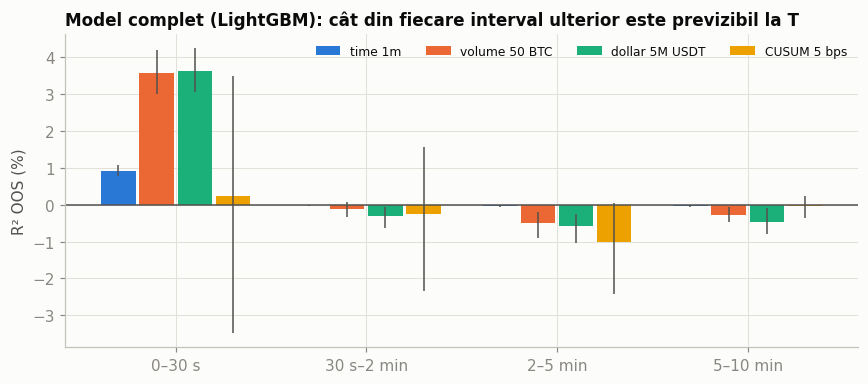

In [25]:
SEG_T = [f"S{a}_{b}" for a, b in SEGMENTS]
SEG = cached("res_segments", lambda: results_table("native", SETS, SEG_T, ["QI", "PVC", "FULL"]))
display(Markdown("**Informația de la momentul deciziei despre intervale ulterioare: R² OOS (%) pentru randamentul pe mid între T+a și T+b (modele reantrenate pe fiecare interval).**"))
display(wide(SEG, [("QI", "ridge"), ("PVC", "lgb"), ("FULL", "ridge"), ("FULL", "lgb")], SEG_T))
display(Markdown("**Aceleași intervale, ținta winsorizată la limitele din train.**"))
display(wide(SEG.assign(r2=SEG["r2_clip"], lo=SEG["lo_clip"], hi=SEG["hi_clip"]), [("QI", "ridge"), ("PVC", "lgb"), ("FULL", "ridge"), ("FULL", "lgb")], SEG_T))
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(SEG_T))
for k, s in enumerate(SETS):
    sub = SEG[(SEG["set"] == s) & (SEG["features"] == "FULL") & (SEG["model"] == "lgb")].set_index("țintă").reindex(SEG_T)
    ax.bar(xs + (k - 1.5) * 0.2, sub["r2"], width=0.18, color=COLOR[s], label=LABEL[s])
    ax.errorbar(xs + (k - 1.5) * 0.2, sub["r2"], yerr=[sub["r2"] - sub["lo"], sub["hi"] - sub["r2"]], fmt="none", ecolor=INK2, lw=1)
ax.set_xticks(xs, ["0–30 s", "30 s–2 min", "2–5 min", "5–10 min"])
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("R² OOS (%)")
ax.set_title("Model complet (LightGBM): cât din fiecare interval ulterior este previzibil la T")
ax.legend(fontsize=8, ncol=4)
fig.tight_layout()
plt.show()

**Randamentul cumulativ nu anticipează mișcarea ulterioară.** Cu informația de la `T`:

* **0–30 s:** R² 1,0% (`time_1m`), 3,3–3,7% (volume, dollar), stabil cu intervale strânse (CUSUM instabil).
* **30 s – 2 min, 2 – 5 min, 5 – 10 min:** zero sau negativ peste tot. `qi_1` are exact 0,00% (efectul s-a consumat), iar modelele complete devin negative, mai ales LightGBM pe barele de evenimente (până la −0,6%): învață pe train tipare care nu se repetă.

Deci R²-ul cumulativ la 2, 5 sau 10 minute este **mișcarea din primele secunde, rămasă în preț și diluată de varianța restului intervalului**, nu o predicție a perioadei întregi. Efectul `qi_1` nu se inversează (nicio pantă negativă ulterioară), ceea ce confirmă natura sa permanentă, găsită și în primul notebook.

**Aceeași prognoză (formată la T), evaluată pe randamentul de la T+δ la T+h: cât din semnal supraviețuiește întârzierii execuției.** R² OOS (%).

întârziere (s)                   0.0    0.1    1.0    5.0     30.0
set           model      țintă                                    
cusum_5bps    FULL · lgb C1     1.548  1.474  0.143 -1.712 -16.250
                         C10    0.641  0.813  0.830  0.533  -0.481
                         C2     2.031  2.221  0.730 -0.001  -5.585
                         C5    -0.365 -0.211 -0.640 -1.344  -4.041
              PVC · lgb  C1     0.522  0.685 -0.513 -1.878 -18.778
                         C10    1.472  1.682  1.659  1.228  -0.277
                         C2     2.768  2.927  1.789  0.634  -5.279
                         C5    -0.398 -0.204 -0.774 -1.602  -5.171
              QI · ridge C1     0.403  0.085 -0.258 -0.413  -0.881
                         C10    0.112  0.057 -0.004 -0.030  -0.029
                         C2     0.285  0.069 -0.180 -0.282  -0.442
                         C5     0.165  0.065 -0.032 -0.084  -0.101
dollar_5musdt FULL · lgb C1     1.349 -0.162 -2.129 -2.783  -6.663
                         C10   -0.468 -0.469 -0.459 -0.495  -0.639
                         C2     0.783  0.126 -0.683 -0.884  -1.543
                         C5     0.078 -0.078 -0.238 -0.300  -0.468
              PVC · lgb  C1     1.389  0.416 -0.905 -1.319  -3.406
                         C10   -0.412 -0.408 -0.386 -0.435  -0.615
                         C2     0.551  0.115 -0.475 -0.646  -1.173
                         C5     0.084  0.006 -0.075 -0.159  -0.436
              QI · ridge C1     0.143  0.022 -0.111 -0.178  -0.341
                         C10    0.014 -0.003 -0.020 -0.028  -0.030
                         C2     0.072  0.003 -0.070 -0.104  -0.139
                         C5     0.028 -0.003 -0.034 -0.048  -0.054
time_1m       FULL · lgb C1     0.514  0.447 -0.070 -0.628  -1.766
                         C10   -0.038 -0.039 -0.049 -0.063  -0.077
                         C2     0.200  0.172 -0.037 -0.256  -0.455
                         C5    -0.024 -0.032 -0.084 -0.149  -0.190
              PVC · lgb  C1     0.012  0.003 -0.080 -0.216  -0.470
                         C10   -0.016 -0.016 -0.016 -0.025  -0.033
                         C2     0.015  0.011 -0.015 -0.069  -0.104
                         C5    -0.016 -0.017 -0.025 -0.051  -0.061
              QI · ridge C1     0.537  0.474  0.013 -0.434  -1.330
                         C10    0.042  0.036 -0.004 -0.039  -0.061
                         C2     0.232  0.204 -0.007 -0.197  -0.393
                         C5     0.083  0.072 -0.005 -0.072  -0.120
volume_50btc  FULL · lgb C1     1.895  0.351 -1.499 -2.075  -5.178
                         C10   -0.439 -0.452 -0.459 -0.487  -0.609
                         C2     0.850  0.158 -0.641 -0.847  -1.470
                         C5    -0.044 -0.201 -0.355 -0.417  -0.617
              PVC · lgb  C1     1.163  0.092 -1.264 -1.758  -4.434
                         C10   -0.411 -0.407 -0.406 -0.444  -0.570
                         C2     0.341 -0.101 -0.658 -0.838  -1.384
                         C5    -0.163 -0.274 -0.393 -0.479  -0.735
              QI · ridge C1     0.138  0.024 -0.099 -0.158  -0.305
                         C10    0.017 -0.000 -0.018 -0.025  -0.026
                         C2     0.074  0.009 -0.059 -0.089  -0.118
                         C5     0.031  0.004 -0.023 -0.034  -0.037

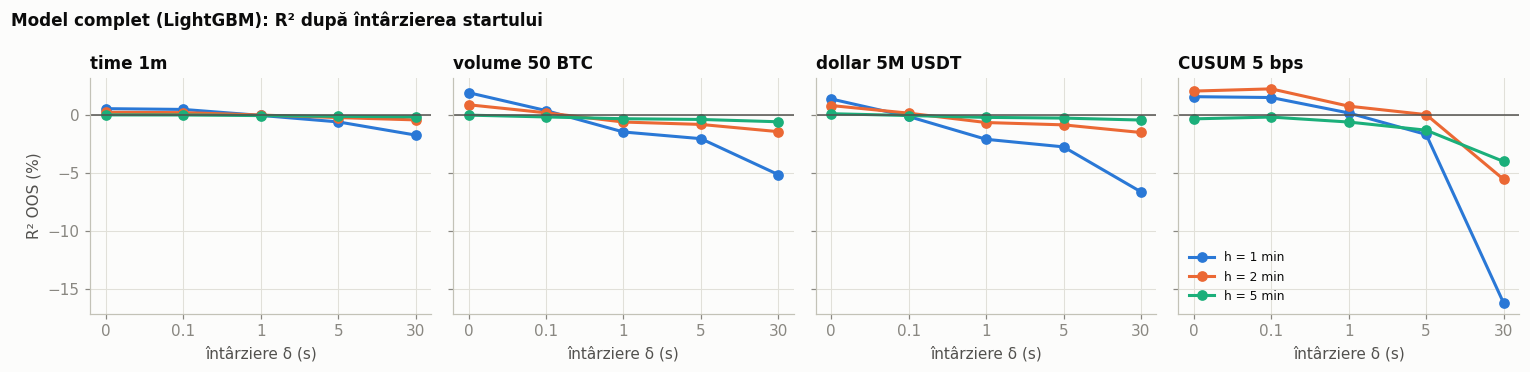

In [26]:
rows = []
for s in SETS:
    for t in ["C1", "C2", "C5", "C10"]:
        for fs, m in [("FULL", "lgb"), ("QI", "ridge"), ("PVC", "lgb")]:
            d = cell_data("native", s, t, fs)
            r = d["row"].to_numpy()
            for delay in [0.0] + DELAYS:
                yd = d["y"].to_numpy() if delay == 0 else TG[s]["Y"][f"D{delay:g}_{t}"][r].astype(np.float64)
                dd = d.assign(y=yd)[np.isfinite(yd)]
                st = r2_stats(dd, m)
                ic = ic_stats(dd, m)
                rows.append({"set": s, "țintă": t, "model": f"{fs} · {m}", "întârziere (s)": delay, "r2": st["r2"], "lo": st["lo"], "hi": st["hi"],
                             "IC": ic["IC"], "panta": ic["panta_calibrare"]})
DELAY = pd.DataFrame(rows)
display(Markdown("**Aceeași prognoză (formată la T), evaluată pe randamentul de la T+δ la T+h: cât din semnal supraviețuiește întârzierii execuției.** R² OOS (%)."))
display(DELAY.pivot_table(index=["set", "model", "țintă"], columns="întârziere (s)", values="r2").round(3))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, s in zip(axes, SETS):
    for t, col in zip(["C1", "C2", "C5"], [C["blue"], C["orange"], C["aqua"]]):
        sub = DELAY[(DELAY["set"] == s) & (DELAY["țintă"] == t) & (DELAY["model"] == "FULL · lgb")]
        ax.plot(np.arange(len(sub)), sub["r2"], marker="o", color=col, label=f"h = {t[1:]} min")
    ax.set_xticks(range(5), ["0", "0.1", "1", "5", "30"])
    ax.axhline(0, color=INK2, lw=1)
    ax.set_title(LABEL[s])
    ax.set_xlabel("întârziere δ (s)")
axes[0].set_ylabel("R² OOS (%)")
axes[-1].legend(fontsize=8)
fig.suptitle("Model complet (LightGBM): R² după întârzierea startului", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

**Cât supraviețuiește întârzierii.** Pe `time_1m`, R² la 1 minut trece de la 0,54% (`qi_1`) la 0,47% cu 100 ms, ~0 cu 1 s și negativ după (prognoza pariază o mișcare deja produsă). Pe volume și dollar, de la 1,4–1,9% la 0,2–0,4% cu 100 ms și negativ de la 1 s. Pe CUSUM, LightGBM păstrează ceva până la 1 s, dar cu intervale care includ zero. Concluzia este aceeași ca în primul notebook, acum măsurată sub-secundă: **informația utilizabilă trăiește sub o secundă pe barele de evenimente și ~1 s pe `time_1m`.**

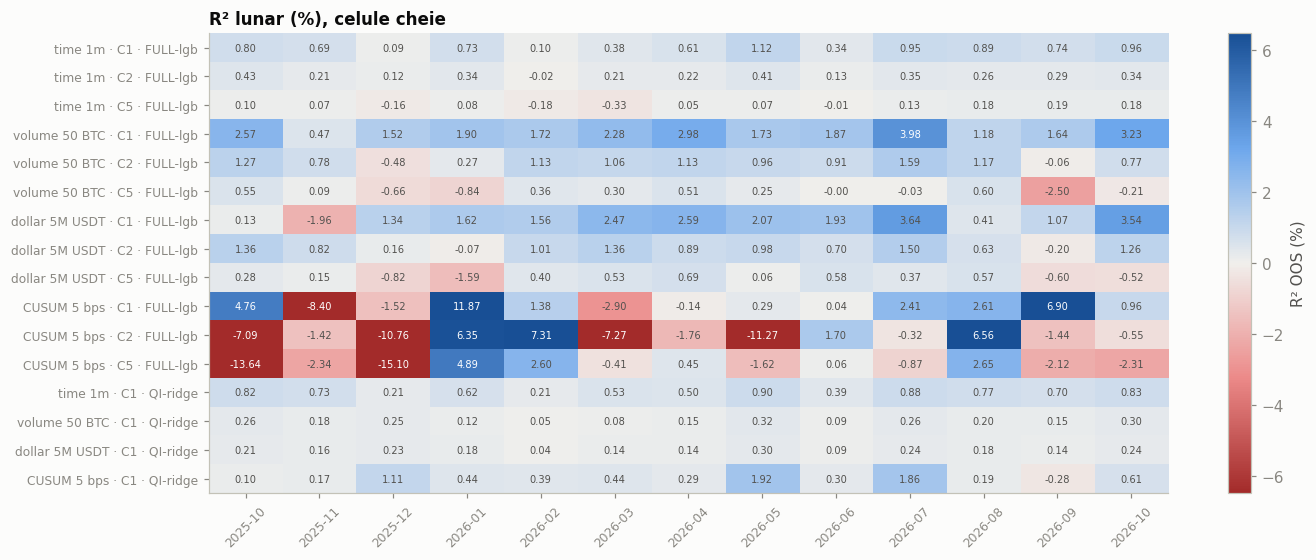

**R² OOS (%) pe condiții de piață cunoscute la decizie (model complet, LightGBM).**

celulă                                       CUSUM 5 bps · C1  CUSUM 5 bps · C5  dollar 5M USDT · C1  dollar 5M USDT · C5  time 1m · C1  time 1m · C5  volume 50 BTC · C1  volume 50 BTC · C5
condiție         nivel                                                                                                                                                                       
activitate       1 scăzută                             -2.025             3.492                3.131                0.854         1.129         0.024               3.442               0.729
                 2 normală                             -0.632            -1.129                2.297                0.215         0.720        -0.001               2.829               0.470
                 3 ridicată                             3.199            -0.772                0.786               -0.064         0.161        -0.057               1.381              -0.270
proveniență book ancorat (0)                            1.792             0.057                1.834                0.213         0.724         0.102               2.087              -0.271
                 reconstruit certificat (9)             1.396            -0.582                1.042               -0.002         0.386        -0.101               1.759               0.105
regim_vol        1 calm                                -5.634            -7.755                1.995               -0.230         0.873        -0.087               2.763              -0.349
                 2 normal                              -1.584            -2.382                1.257                0.097         0.609         0.020               1.924              -0.277
                 3 turbulent                            4.086             1.681                1.223                0.140         0.316        -0.031               1.659               0.131
sesiune          1 Asia 00–08                           2.292             2.081                1.487               -0.276         0.544        -0.055               2.192               0.392
                 2 Europa 08–13                         2.665            -2.828                2.125               -0.224         0.890         0.042               2.826              -0.673
                 3 SUA 13–21                            2.408            -2.573                1.007                0.125         0.311        -0.049               1.501              -0.273
                 4 târziu 21–24                        -2.009             4.865                1.757                1.302         0.806         0.070               2.023               1.333
weekend          weekend                               -1.279             3.734                2.587                0.907         0.895         0.054               2.871               0.809
                 zi lucrătoare                          2.369            -1.063                1.141               -0.026         0.443        -0.039               1.729              -0.150

In [27]:
KEY = [("native", s, t, "FULL", "lgb") for s in SETS for t in ("C1", "C2", "C5")] + [("native", s, "C1", "QI", "ridge") for s in SETS]
rows = []
for kind, s, t, fs, m in KEY:
    d = cell_data(kind, s, t, fs)
    A, Bm = daily_sums(d, d[m].to_numpy())
    mon = pd.DataFrame({"A": A, "B": Bm}, index=EVAL_DAYS).groupby(EVAL_DAYS.strftime("%Y-%m")).sum()
    for mo, r_ in mon.iterrows():
        rows.append({"celulă": f"{LABEL[s]} · {t} · {fs}-{m}", "luna": mo, "r2": 100 * (1 - r_["B"] / r_["A"]) if r_["A"] > 0 else np.nan})
MON = pd.DataFrame(rows).pivot(index="celulă", columns="luna", values="r2")
MON = MON.loc[[f"{LABEL[s]} · {t} · {fs}-{m}" for _, s, t, fs, m in KEY]]
fig, ax = plt.subplots(figsize=(13, 5.2))
lim = np.nanpercentile(np.abs(MON.to_numpy()), 95)
im = ax.imshow(MON.to_numpy(), aspect="auto", cmap=DIVERGING.reversed(), vmin=-lim, vmax=lim)
ax.set_yticks(range(len(MON)), MON.index, fontsize=8)
ax.set_xticks(range(MON.shape[1]), MON.columns, rotation=45, fontsize=8)
ax.grid(False)
for i in range(MON.shape[0]):
    for j in range(MON.shape[1]):
        v = MON.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 * lim else INK2)
fig.colorbar(im, ax=ax, label="R² OOS (%)")
ax.set_title("R² lunar (%), celule cheie")
fig.tight_layout()
plt.show()

rows = []
for kind, s, t, fs, m in [k for k in KEY if k[2] in ("C1", "C5") and k[3] == "FULL"]:
    d = cell_data(kind, s, t, fs)
    cd = cond_at(d["tns"].to_numpy())
    bs = pd.read_parquet(CACHE / f"feat_{s}" / "meta.parquet", columns=["book_state"])["book_state"].to_numpy()[d["row"].to_numpy()]
    cd["proveniență book"] = np.where(bs == 0, "ancorat (0)", "reconstruit certificat (9)")
    for cname in ["regim_vol", "activitate", "sesiune", "weekend", "proveniență book"]:
        for lev in sorted(cd[cname].dropna().unique()):
            mm = (cd[cname] == lev).to_numpy()
            st = r2_stats(d[mm], m)
            rows.append({"celulă": f"{LABEL[s]} · {t}", "condiție": cname, "nivel": lev, "r2": st["r2"], "IC": f"[{st['lo']:.2f}, {st['hi']:.2f}]",
                         "rânduri %": 100 * mm.mean()})
COND_TAB = pd.DataFrame(rows)
display(Markdown("**R² OOS (%) pe condiții de piață cunoscute la decizie (model complet, LightGBM).**"))
display(COND_TAB.pivot_table(index=["condiție", "nivel"], columns="celulă", values="r2", aggfunc="first").round(3))

**Stabilitate.** `qi_1` și modelul complet pe `time_1m` sunt pozitive în toate cele 13 luni la 1 și 2 minute; pe volume și dollar, la 1 minut, 12–13 luni din 13. La 5 minute, modelele complete au 7–11 luni pozitive din 13, aproape de aruncarea monedei, în timp ce `qi_1` rămâne pozitiv în 12–13 luni, dar cu R² de doar 0,03–0,08%. CUSUM are 9/13 la 1 minut și 3–8/13 mai departe.

**Condiții.** Semnalul este mai puternic în piețe calme, la activitate scăzută, în weekend și în sesiunea europeană, și mai slab în piețe agitate și în sesiunea SUA, în linie cu un efect de mărime fixă în bps raportat la o varianță variabilă. Pe `time_1m`, rândurile cu book ancorat (0,72%) au R² mai mare decât cele reconstruite (0,39%), dar cele două stări corespund unor perioade diferite (reconstruit = iulie 2025 – aprilie 2026), deci diferența nu poate fi atribuită provenienței. CUSUM schimbă semnul de la o condiție la alta, încă un semn că rezultatele lui sunt dominate de câteva episoade.

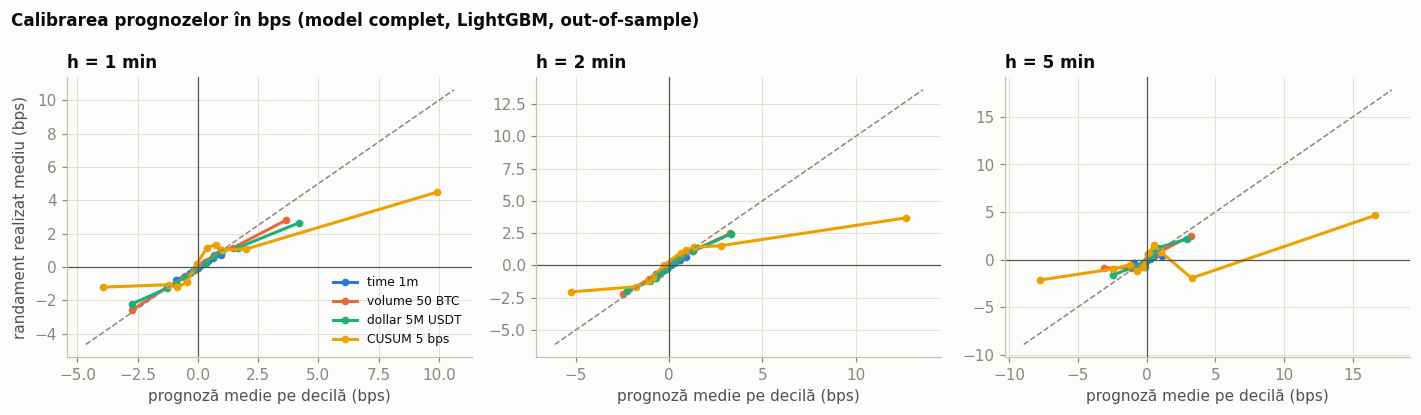

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, t in zip(axes, ["C1", "C2", "C5"]):
    for s in SETS:
        d = cell_data("native", s, t, "FULL")
        d = d[~d["crash"]]
        q = pd.qcut(d["lgb"], 10, labels=False, duplicates="drop")
        g = d.groupby(q).agg(f=("lgb", "mean"), y=("y", "mean"))
        ax.plot(g["f"], g["y"], marker="o", ms=4, color=COLOR[s], label=LABEL[s])
    lim = ax.get_xlim()
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_title(f"h = {t[1:]} min")
    ax.set_xlabel("prognoză medie pe decilă (bps)")
axes[0].set_ylabel("randament realizat mediu (bps)")
axes[0].legend(fontsize=8)
fig.suptitle("Calibrarea prognozelor în bps (model complet, LightGBM, out-of-sample)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

În bps, prognozele sunt mici: |f| mediu ≈ 0,4 bps pe `time_1m` (aceeași mărime pentru `qi_1` și pentru modelul complet), ≈ 1,0–1,3 bps pe volume și dollar și 2–4 bps pe CUSUM, comparat cu abateri standard ale țintei de 6–40 bps. Pe grafic, pentru `time_1m`, volume și dollar decilele stau aproape de diagonală la 1–2 minute, ușor sub ea la extreme; CUSUM promite la extreme mișcări de 10–17 bps care se realizează doar în proporție de 30–50% sau deloc. Panourile au scale proprii pe fiecare set; intervalele CUSUM sunt de un ordin de mărime mai largi.

## 13. Importanța features-urilor după López de Prado, adaptată regresiei pe date temporale

### 13.1 Surse și ce preiau din ele

* **López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley, ISBN 978-1-119-48208-6.** Capitolul 7 (*Cross-Validation in Finance*): 7.4.1 *Purging the Training Set*, 7.4.2 *Embargo*. Capitolul 8 (*Feature Importance*): 8.3 importanță *cu* efecte de substituție — 8.3.1 *Mean Decrease Impurity* (MDI), 8.3.2 *Mean Decrease Accuracy* (MDA); 8.4 importanță *fără* efecte de substituție — 8.4.1 *Single Feature Importance* (SFI), 8.4.2 *Orthogonal Features*. (Secțiunile și paginile verificate pe cuprinsul publicat al cărții.)
* **López de Prado, M. (2020). *Machine Learning for Asset Managers*. Cambridge University Press, Elements in Quantitative Finance, DOI 10.1017/9781108883658.** Capitolul 4 (*Optimal Clustering*, algoritmul ONC cu scorul de calitate silhouette) și capitolul 6 (*Feature Importance Analysis*), unde substituția dintre features corelate se tratează prin gruparea lor și prin importanță calculată pe clustere (*clustered MDI/MDA*): membrii unui cluster se permută împreună, astfel încât modelul să nu poată folosi o copie rămasă intactă.
* Ca fundament pentru permutare: Breiman, L. (2001), *Random Forests*, Machine Learning 45, 5–32 (importanța prin permutare); Strobl, C. et al. (2007), *Bias in random forest variable importance measures*, BMC Bioinformatics 8:25 (MDI favorizează features cu multe valori distincte).

### 13.2 Ce diferă față de cărți și de ce

| Metodă | În cărți | Aici | Motiv |
|---|---|---|---|
| Validare | k-fold purjat cu embargo | walk-forward expanding, purging pe capătul real al etichetei | Antrenarea precede mereu testul (ca în producție); embargo-ul nu mai are obiect. Orizonturile în bare au capete variabile, deci purging-ul folosește momentul real de închidere a barei t+k. |
| MDA | clasificare, scor log-loss/accuracy, permutare aleatoare a rândurilor | regresie, scor MSE exprimat ca ΔR² în puncte procentuale ale lui Σy², **deplasare circulară** a coloanei (sau a grupului) în foldul de test | Ținta este randamentul în bps. ΔR² e comparabil între ținte cu varianțe diferite. Deplasarea circulară păstrează distribuția și autocorelația feature-ului (și relațiile din interiorul grupului) și rupe doar alinierea cu ținta. Limită: ca orice permutare, rupe și relația cu celelalte features, deci modelul vede combinații nerealiste. |
| MDA grupat | clustere ONC (k-means pe corelații) | (a) **familii economice** fixate a priori; (b) **clustere statistice** învățate doar pe fereastra inițială de antrenare: clustering ierarhic (average linkage) pe distanța √(1 − \|ρ Spearman\|), numărul de clustere ales maximizând t-statisticul silhouette (scorul de calitate ONC) | Familiile răspund la întrebarea economică; clusterele tratează substituția fără a impune o taxonomie. Semnul corelației e ignorat: un feature și opusul lui sunt substitute. |
| SFI | un model pe fiecare feature, același CV | funcție în trepte pe 20 de cuantile (NaN = treaptă proprie, medii contractate spre zero) **și** pantă liniară, ambele învățate pe train, scor R² OOS pe fiecare fold; exhaustiv, pentru **toate** features × **toate** țintele | Rapid, captează neliniarități monotone și nemonotone, iar panta dă semnul relației. Un SFI slab nu exclude interacțiuni. |
| MDI | pădure aleatoare cu `max_features = 1`, importanța impurității, zerourile → NaN | identic (regresie, impuritate = varianță), în eșantion, pe fereastra de dezvoltare, plus o a doua pădure pe **etichete deplasate** | Diagnostic complementar. A doua pădure arată cât din clasament este forma distribuției, nu informație. |
| Câștig de split LightGBM | — | raportat separat, **numit „câștig de split”**, nu MDI | Nu este MDI: provine din boosting cu toate features la fiecare split (efect de mascare) și nu are calibrare. |

**Ce analizez exhaustiv și ce selectiv.** Exhaustiv: SFI pentru toate features și toate țintele native; MDA pe familii pentru toate celulele complete (toate seturile, toate orizonturile de ceas, în bare și intervalele ulterioare, plus țintele placebo). Selectiv: MDA pe fiecare feature și pe clustere, cu 20 de features placebo în model, și MDI, numai pentru șapte combinații set–orizont alese pe foldurile de dezvoltare după reguli fixate dinainte (secțiunea 13.5).

**Multiplicitate.** Pentru SFI: valoare p bootstrap (H0: R² ≤ 0) și corecție Benjamini–Hochberg pe fiecare țintă, plus comparația cu features placebo (câte features reale depășesc maximul placebo, față de numărul așteptat întâmplător `N_real / (N_placebo + 1)`). Pentru MDA detaliat: pragul este maximul importanței placebo. Pentru harta familiilor: pragul de zgomot vine din țintele placebo.

### 13.3 Combinațiile pentru analiza detaliată (alese acum, numai pe foldurile de dezvoltare)

Regulile, fixate înainte de a vedea vreo importanță, aplicate pe foldurile de dezvoltare (F1–F4) ale modelului complet LightGBM pe eșantionul nativ: (1) combinația set × orizont de ceas cu cel mai mare R²; (2) același set la primul orizont unde R² scade sub jumătate; (3) același set la 10 minute; (4) setul de evenimente cu cel mai mare R² la bara următoare, la k = 1 și (5) k = 5; (6) primul set la intervalul 2–5 minute (informație despre mișcarea ulterioară); (7) control negativ: același set pe ținta placebo.

**Extensie declarată.** Regula a ales barele volume și CUSUM, al căror semnal pe termen scurt s-a dovedit neexecutabil (secțiunile 8 și 10). Am adăugat, după ce am văzut alegerea regulii și înainte de orice rezultat de importanță detaliată, `time_1m` la 1 și 5 minute: cel mai robust semnal din studiu.

In [29]:
def dev_r2(kind, s, t, fs, model="lgb"):
    d = cell_data(kind, s, t, fs)
    d = d[d["tns"] < DEV_END.value]
    return r2_stats(d, model)["r2"]


# Selection rules (fixed in advance, applied to development folds only, FULL LightGBM on the native sample):
DEV_TAB = pd.DataFrame([{"set": s, "țintă": t, "r2_dev": dev_r2("native", s, t, "FULL")}
                        for s in SETS for t in [f"C{h}" for h in CLOCK_H] + ([f"B{k}" for k in BAR_K] if s != "time_1m" else [])])
clock_dev = DEV_TAB[DEV_TAB["țintă"].str.startswith("C")]
best = clock_dev.sort_values("r2_dev", ascending=False).iloc[0]
S1, T1_ = best["set"], best["țintă"]
dec = clock_dev[(clock_dev["set"] == S1) & (clock_dev["țintă"].str[1:].astype(int) > int(T1_[1:])) & (clock_dev["r2_dev"] <= best["r2_dev"] / 2)]
T2_ = dec.sort_values("țintă", key=lambda x: x.str[1:].astype(int)).iloc[0]["țintă"] if len(dec) else "C10"
bar_dev = DEV_TAB[DEV_TAB["țintă"] == "B1"].sort_values("r2_dev", ascending=False).iloc[0]
SB = bar_dev["set"]
FI_COMBOS = [("semnal maxim (ceas)", S1, T1_), ("semnal în declin (ceas)", S1, T2_), ("orizont lung (ceas)", S1, "C10"),
             ("semnal maxim (bare)", SB, "B1"), ("bare, orizont lung", SB, "B5"), ("mișcare ulterioară 2–5 min", S1, "S120_300"),
             ("control negativ (placebo)", S1, "P1")]
# Extension, decided after seeing which combinations the rule picked and before any detailed importance result: the rule selected event
# sets, whose short-horizon signal turned out not to be executable (section 10), so the most robust signal (time_1m) is added explicitly.
FI_COMBOS += [("extensie: time 1m, 1 minut", "time_1m", "C1"), ("extensie: time 1m, 5 minute", "time_1m", "C5")]
FI_COMBOS = list(dict.fromkeys(FI_COMBOS))
display(pd.DataFrame(FI_COMBOS, columns=["rol", "set", "țintă"]).assign(
    r2_dezvoltare=[DEV_TAB.set_index(["set", "țintă"])["r2_dev"].get((s, t), np.nan) for _, s, t in FI_COMBOS]).round(3))

,rol,set,țintă,r2_dezvoltare
0,semnal maxim (ceas),volume_50btc,C1,1.809
1,semnal în declin (ceas),volume_50btc,C2,0.842
2,orizont lung (ceas),volume_50btc,C10,-0.660
3,semnal maxim (bare),cusum_5bps,B1,15.057
4,"bare, orizont lung",cusum_5bps,B5,3.063
5,mișcare ulterioară 2–5 min,volume_50btc,S120_300,NaN
6,control negativ (placebo),volume_50btc,P1,NaN
7,"extensie: time 1m, 1 minut",time_1m,C1,0.435
8,"extensie: time 1m, 5 minute",time_1m,C5,-0.085


Regula a ales barele volume la 1, 2 și 10 minute și la intervalul 2–5 minute, CUSUM pe bara următoare și la cinci bare, plus ținta placebo; extensia adaugă `time_1m` la 1 și 5 minute.

### 13.4 Harta familie × orizont (MDA grupat, exhaustiv)

Pentru fiecare celulă completă și fiecare fold, permut circular în bloc toate coloanele unei familii pe un eșantion de 40.000 de rânduri de test și măsor creșterea erorii. Valorile sunt ΔR² în puncte procentuale, agregate pe folduri; ● marchează celulele pozitive în cel puțin 80% din folduri și cu t > 2 pe folduri. Sub fiecare coloană apare R² al modelului pe același eșantion, ca să se vadă când un clasament provine dintr-un model care nu mai prezice nimic.

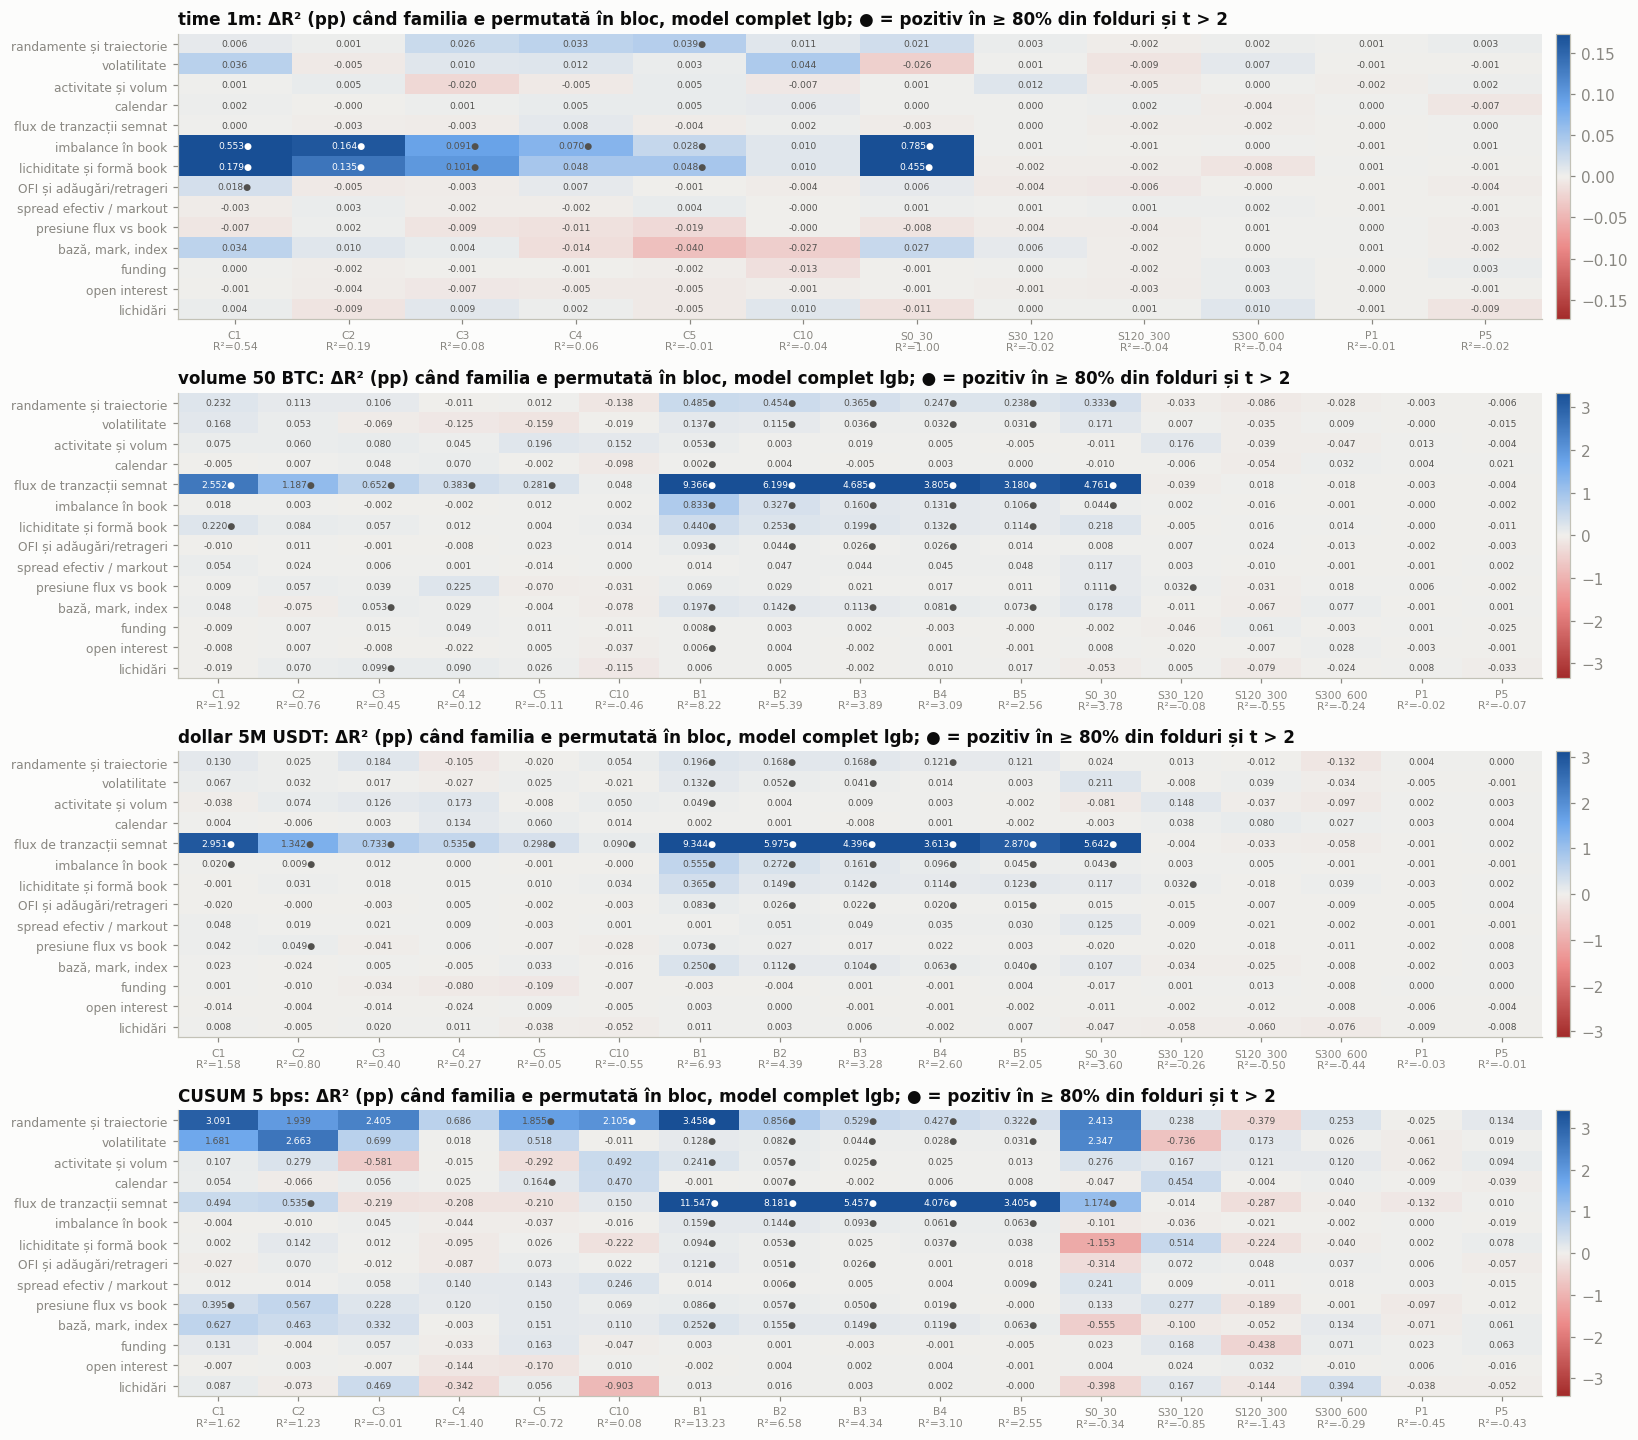

In [30]:
def family_mda(kind, s, t, model):
    """Pooled grouped-permutation importance per family: sum over folds of the increase in squared error when the family is circularly
    shifted, divided by the sum of y² on the same rows -> ΔR² in percentage points (comparable across targets with different variances)."""
    r = load_cell(kind, s, t, "FULL")
    rec = [f for f in r["folds"] if "mda_ridge" in f]
    key = "mda_ridge" if model == "ridge" else "mda_lgb"
    base = "mda_base_ridge" if model == "ridge" else "mda_base_lgb"
    y2 = np.array([f["mda_y2"] for f in rec])
    fams = list(rec[0][key].keys())
    per_fold = pd.DataFrame({g: [np.mean(f[key][g]) / f["mda_y2"] * 100 for f in rec] for g in fams}, index=[f["fold"] for f in rec])
    pooled = pd.Series({g: sum(np.mean(f[key][g]) for f in rec) / y2.sum() * 100 for g in fams})
    r2_model = 100 * (1 - sum(f[base] for f in rec) / y2.sum())
    return pooled, per_fold, r2_model


def mda_map(kind, s, targets, model):
    P, F, R = {}, {}, {}
    for t in targets:
        if (CELLS / f"{kind}__{s}__{t}__FULL.pkl").exists():
            P[t], F[t], R[t] = family_mda(kind, s, t, model)
    return pd.DataFrame(P), F, pd.Series(R)


MAP_T = {s: [f"C{h}" for h in CLOCK_H] + ([f"B{k}" for k in BAR_K] if s != "time_1m" else []) + SEG_T + ["P1", "P5"] for s in SETS}
MDA_MAPS = {(s, m): mda_map("native", s, MAP_T[s], m) for s in SETS for m in ("lgb", "ridge")}


def stab(F, g, t):
    v = F[t][g]
    return (v > 0).mean(), v.mean() / (v.std(ddof=1) / np.sqrt(len(v))) if len(v) > 1 and v.std() > 0 else np.nan


def plot_family_map(model):
    fig, axes = plt.subplots(len(SETS), 1, figsize=(15, 3.3 * len(SETS)))
    for ax, s in zip(axes, SETS):
        P, F, R = MDA_MAPS[(s, model)]
        P = P.reindex(FAMILY_DISPLAY_ORDER)
        lim = max(np.nanpercentile(np.abs(P.to_numpy()), 98), 1e-3)
        im = ax.imshow(P.to_numpy(), aspect="auto", cmap=DIVERGING.reversed(), vmin=-lim, vmax=lim)
        ax.set_yticks(range(len(P)), [FAMILY_LABEL[g] for g in P.index], fontsize=8)
        ax.set_xticks(range(P.shape[1]), [f"{c}\nR²={R[c]:.2f}" for c in P.columns], fontsize=7)
        ax.grid(False)
        for i, g in enumerate(P.index):
            for j, t in enumerate(P.columns):
                v = P.iat[i, j]
                if not np.isfinite(v):
                    continue
                share, tt = stab(F, g, t)
                mark = "●" if (share >= 0.8 and tt > 2) else ""
                ax.text(j, i, f"{v:.3f}{mark}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 * lim else INK2)
        ax.set_title(f"{LABEL[s]}: ΔR² (pp) când familia e permutată în bloc, model complet {model}; ● = pozitiv în ≥ 80% din folduri și t > 2")
        fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
    fig.tight_layout()
    plt.show()


plot_family_map("lgb")

**Harta LightGBM.** Două familii, câte una pe tip de bară, poartă aproape toată importanța:

* **`time_1m`: imbalance-ul din book** (0,55 pp la 1 minut → 0,16 → 0,09 → 0,07 → 0,03 → 0,01 pp la 10 minute), urmat de lichiditatea și forma book-ului (0,18 → 0,01 pp). Celelalte 12 familii rămân sub 0,04 pp la orice orizont, adică la nivelul zgomotului.
* **Volume și dollar: fluxul de tranzacții semnat** (2,6–3,0 pp la 1 minut → 1,2–1,3 → 0,7 → 0,4–0,5 → 0,3 → 0,05–0,09 pp), cu contribuții mici din traiectorie, lichiditate și volatilitate la 1 minut. Imbalance-ul din book contează sub 0,02 pp: la închiderea unei bare de evenimente, informația lui e deja în flux.
* **CUSUM:** valori mari (randamente și traiectorie 3,1 pp, volatilitate 1,7 pp la 1 minut), dar modelul complet are R² instabil (secțiunea 10.4) și chiar ținta placebo produce ΔR² de familie de până la 0,13 pp. Harta CUSUM pe ceas nu este interpretabilă.

Pe țintele placebo, cea mai mare importanță de familie este 0,013 pp pe `time_1m`, volume și dollar: acesta este pragul de zgomot al hărții.

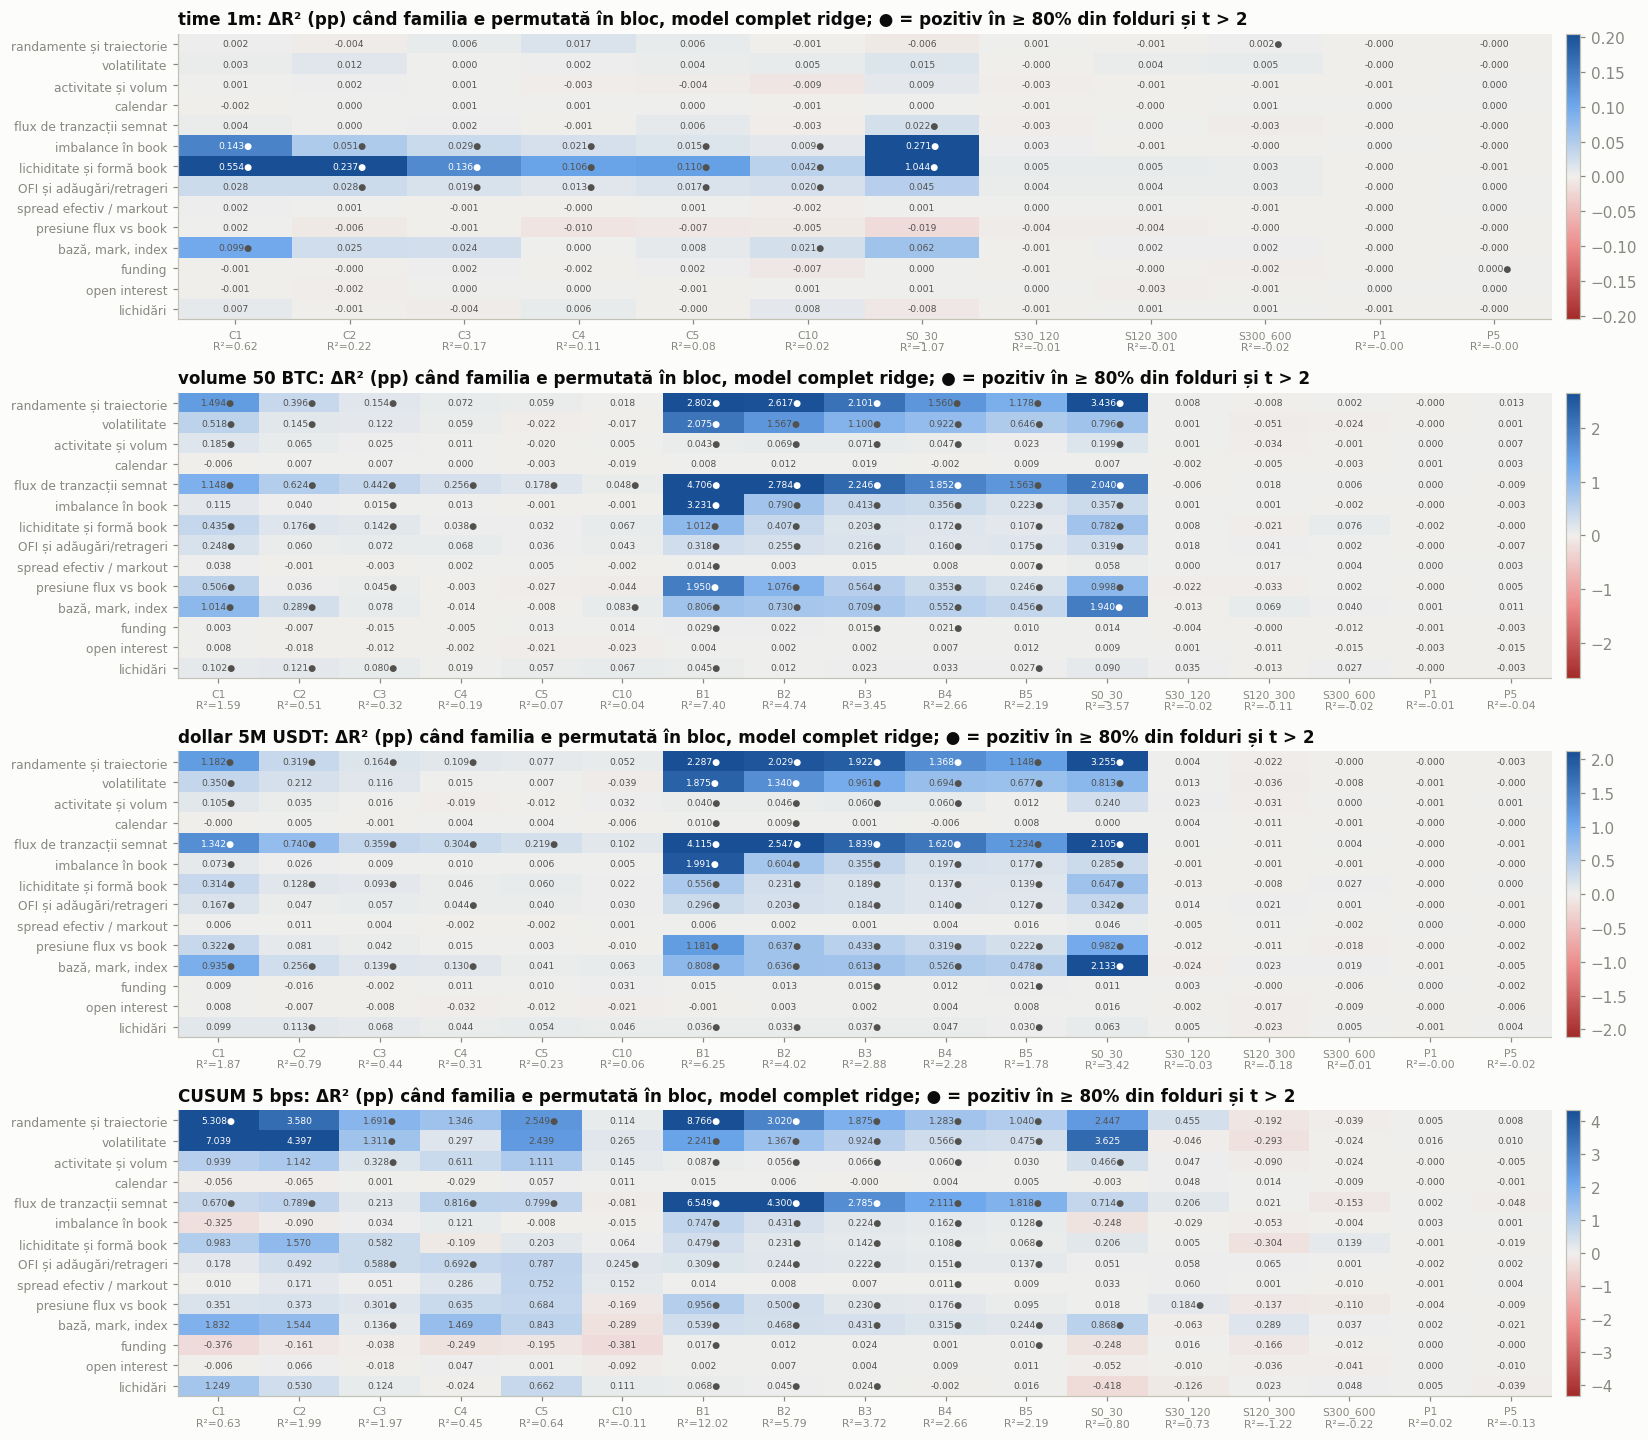

**Control negativ pentru hartă: ținte placebo (randamentul de peste 7 zile). Valorile dau pragul de zgomot al importanței pe familii.**

,set,model,țintă placebo,R² model,max ΔR² familie,min ΔR² familie
0,time_1m,lgb,P1,-0.0066,0.0013,-0.0020
1,time_1m,lgb,P5,-0.0195,0.0030,-0.0088
2,time_1m,ridge,P1,-0.0020,0.0003,-0.0008
3,time_1m,ridge,P5,-0.0007,0.0001,-0.0008
4,volume_50btc,lgb,P1,-0.0151,0.0131,-0.0033
5,volume_50btc,lgb,P5,-0.0659,0.0214,-0.0326
6,volume_50btc,ridge,P1,-0.0060,0.0008,-0.0028
7,volume_50btc,ridge,P5,-0.0395,0.0132,-0.0148
8,dollar_5musdt,lgb,P1,-0.0276,0.0037,-0.0093
9,dollar_5musdt,lgb,P5,-0.0090,0.0084,-0.0081


In [31]:
plot_family_map("ridge")
rows = []
for s in SETS:
    for m in ("lgb", "ridge"):
        P, F, R = MDA_MAPS[(s, m)]
        for t in [c for c in P.columns if c.startswith("P")]:
            rows.append({"set": s, "model": m, "țintă placebo": t, "R² model": R[t], "max ΔR² familie": P[t].max(), "min ΔR² familie": P[t].min()})
display(Markdown("**Control negativ pentru hartă: ținte placebo (randamentul de peste 7 zile). Valorile dau pragul de zgomot al importanței pe familii.**"))
display(pd.DataFrame(rows).round(4))

**Harta ridge și substituția.** În modelul liniar, pe `time_1m`, importanța se mută din imbalance (0,14 pp la 1 minut) în *lichiditate și formă book* (0,55 pp). Nu este o informație diferită: familia de lichiditate conține cantitățile și adâncimile separat pe bid și pe ask (`qty_bid1_btc`, `qty_ask1_btc`, `depth_*_top20`), din care un model liniar reconstruiește imbalance-ul. Când doar familia de imbalance este permutată, modelul se sprijină pe substitut. Clusterele statistice confirmă (cluster-ul lui `qi_1` conține exact aceste coloane), iar blocul „stare book” din secțiunea 13.6 le permută împreună. **Concluzia economică pentru `time_1m` este deci „starea curentă a nivelului 1 din book”, nu o familie anume.**

In [32]:
def dynamics_table(model="lgb"):
    """A family counts at a horizon only if its pooled ΔR² exceeds the placebo noise threshold, it is positive in >= 80% of the folds with
    t > 2 across folds, AND the model itself has R² > 0 at that horizon (importance inside a model that no longer predicts is not evidence)."""
    rows = []
    for s in SETS:
        P, F, R = MDA_MAPS[(s, model)]
        noise = P[[c for c in P.columns if c.startswith("P")]].abs().max(1)
        hs = [f"C{h}" for h in CLOCK_H]
        clock = P[hs]
        for g in FAMILY_DISPLAY_ORDER:
            if g not in clock.index:
                continue
            v = clock.loc[g]
            thr = max(noise.get(g, 0) * 2, 0.002)
            sig = pd.Series({t: (v[t] > thr) and (R[t] > 0) and (stab(F, g, t)[0] >= 0.8) and (stab(F, g, t)[1] > 2) for t in hs})
            if not sig.any():
                cls = "fără contribuție robustă"
            else:
                first = int(sig.idxmax()[1:])
                last_sig = int(sig[sig].index[-1][1:])
                if first >= 3:
                    cls = "apare abia mai târziu"
                elif last_sig >= 5:
                    cls = "persistentă (≥ 5 minute)"
                else:
                    cls = "domină imediat, apoi dispare"
            share = v / clock.clip(lower=0).sum(0)
            rows.append({"set": s, "familie": FAMILY_LABEL[g], "clasă": cls, "orizonturi robuste": ", ".join(sig[sig].index),
                         **{f"ΔR² {c}": v[c] for c in clock.columns}, "pondere C1 %": 100 * share.iloc[0], "prag zgomot": thr})
    return pd.DataFrame(rows)


DYN = dynamics_table("lgb")
display(Markdown("**Clasificarea familiilor după profilul pe orizonturi (ceas, LightGBM).** Un orizont contează doar dacă ΔR² > max(2 × |ΔR²| placebo, 0,002 pp), "
                 "este pozitiv în ≥ 80% din folduri cu t > 2 și modelul are R² > 0 la acel orizont."))
display(DYN[DYN["clasă"] != "fără contribuție robustă"].set_index(["set", "familie"]).round(4))
display(DYN.groupby(["set", "clasă"]).size().unstack(fill_value=0))

**Clasificarea familiilor după profilul pe orizonturi (ceas, LightGBM).** Un orizont contează doar dacă ΔR² > max(2 × |ΔR²| placebo, 0,002 pp), este pozitiv în ≥ 80% din folduri cu t > 2 și modelul are R² > 0 la acel orizont.

clasă  orizonturi robuste  ΔR² C1  ΔR² C2  ΔR² C3  ΔR² C4  ΔR² C5  ΔR² C10  pondere C1 %  prag zgomot
set           familie                                                                                                                                                
time_1m       imbalance în book          domină imediat, apoi dispare      C1, C2, C3, C4  0.5533  0.1645  0.0906  0.0703  0.0280   0.0099       66.4884       0.0020
              lichiditate și formă book  domină imediat, apoi dispare          C1, C2, C3  0.1788  0.1351  0.1008  0.0484  0.0484   0.0102       21.4807       0.0024
              OFI și adăugări/retrageri  domină imediat, apoi dispare                  C1  0.0177 -0.0051 -0.0034  0.0067 -0.0009  -0.0037        2.1299       0.0080
volume_50btc  flux de tranzacții semnat  domină imediat, apoi dispare      C1, C2, C3, C4  2.5517  1.1867  0.6522  0.3833  0.2813   0.0480       75.6020       0.0083
              lichiditate și formă book  domină imediat, apoi dispare                  C1  0.2197  0.0836  0.0573  0.0121  0.0041   0.0340        6.5084       0.0221
              bază, mark, index                 apare abia mai târziu                  C3  0.0479 -0.0746  0.0531  0.0293 -0.0038  -0.0777        1.4186       0.0020
              lichidări                         apare abia mai târziu                  C3 -0.0192  0.0699  0.0990  0.0897  0.0264  -0.1148       -0.5682       0.0653
dollar_5musdt flux de tranzacții semnat      persistentă (≥ 5 minute)  C1, C2, C3, C4, C5  2.9506  1.3424  0.7328  0.5349  0.2977   0.0904       89.5634       0.0030
              imbalance în book          domină imediat, apoi dispare              C1, C2  0.0198  0.0092  0.0124  0.0001 -0.0011  -0.0005        0.6015       0.0020
              presiune flux vs book      domină imediat, apoi dispare                  C2  0.0416  0.0489 -0.0413  0.0058 -0.0073  -0.0279        1.2613       0.0168
cusum_5bps    randamente și traiectorie         apare abia mai târziu                 C10  3.0911  1.9394  2.4046  0.6862  1.8551   2.1053       46.2672       0.2679
              flux de tranzacții semnat  domină imediat, apoi dispare                  C2  0.4945  0.5345 -0.2192 -0.2077 -0.2105   0.1496        7.4016       0.2636
              presiune flux vs book      domină imediat, apoi dispare                  C1  0.3947  0.5669  0.2275  0.1200  0.1500   0.0691        5.9080       0.1937

clasă,apare abia mai târziu,"domină imediat, apoi dispare",fără contribuție robustă,persistentă (≥ 5 minute)
set,,,,
cusum_5bps,1,2,11,0
dollar_5musdt,0,2,11,1
time_1m,0,3,11,0
volume_50btc,2,2,10,0


**Cum se schimbă contribuția între orizonturi (criteriu strict).** Din 14 familii, pe fiecare set doar două-trei au contribuții robuste, toate la orizonturile scurte:

* **`time_1m`:** imbalance-ul (robust la 1–4 minute) și lichiditatea/forma book-ului (1–3 minute); OFI doar la 1 minut. Ponderea imbalance-ului la 1 minut: 66%.
* **Volume și dollar:** fluxul semnat (1–4 minute pe volume, 1–5 minute pe dollar), cu o scădere de ~10 ori între 1 și 5 minute; lichiditatea doar la 1 minut.
* **Celule izolate** („apare abia mai târziu”: baza/indexul și lichidările la 3 minute pe volume, randamentele la 10 minute pe CUSUM) nu se repetă la orizonturile vecine și nici pe setul gemen (dollar), deci le tratez ca rezultate întâmplătoare într-o familie de 14 × 6 × 4 teste.

**Niciun set nu are o familie care să apară robust doar la orizonturi mai lungi.** Funding-ul, open interest-ul și lichidările nu au contribuții robuste până la 10 minute. Aceasta **nu** spune nimic despre orizonturi de ore, care nu au fost testate.

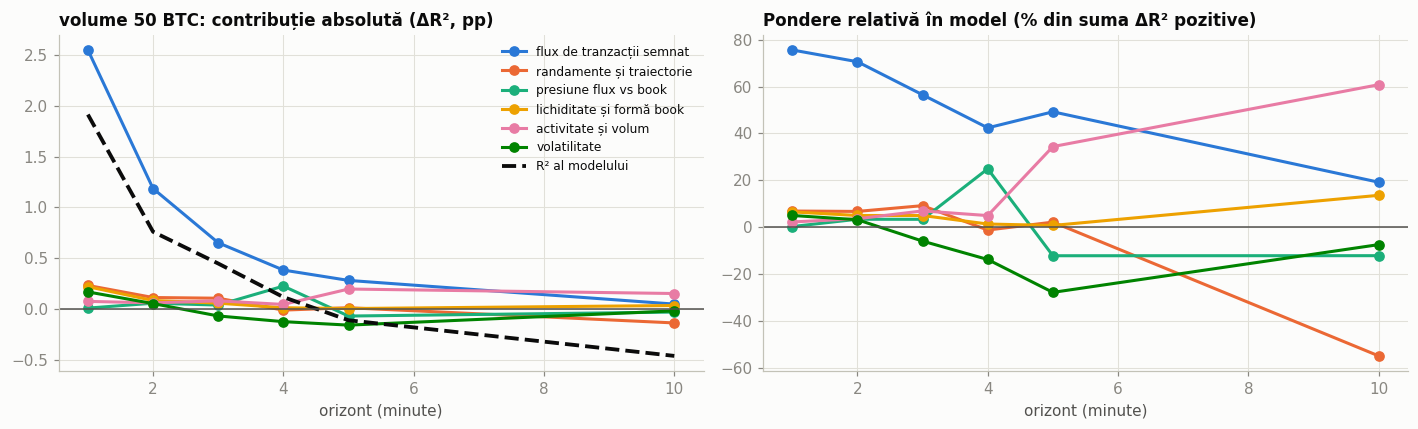

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
s = S1
P, F, R = MDA_MAPS[(s, "lgb")]
clock = P[[f"C{h}" for h in CLOCK_H]].reindex(FAMILY_DISPLAY_ORDER)
top = clock.max(1).sort_values(ascending=False).index[:6]
for k, g in enumerate(top):
    col = list(C.values())[k]
    axes[0].plot(CLOCK_H, clock.loc[g], marker="o", color=col, label=FAMILY_LABEL[g])
    axes[1].plot(CLOCK_H, 100 * clock.loc[g] / clock.clip(lower=0).sum(0), marker="o", color=col, label=FAMILY_LABEL[g])
axes[0].plot(CLOCK_H, R[[f"C{h}" for h in CLOCK_H]], color=INK, lw=2.5, ls="--", label="R² al modelului")
axes[0].set_title(f"{LABEL[s]}: contribuție absolută (ΔR², pp)")
axes[1].set_title("Pondere relativă în model (% din suma ΔR² pozitive)")
for ax in axes:
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xlabel("orizont (minute)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Importanța relativă nu este contribuție.** Pe barele volume (setul ales de regulă), fluxul semnat are 76% din importanța pozitivă la 1 minut și ~19% la 10 minute, iar alte familii (activitate, OFI) par să „câștige” pondere spre 10 minute. Dar la 10 minute modelul are R² negativ (−0,44%): ponderile de acolo împart zgomotul, nu informația. De aceea harta raportează R²-ul modelului sub fiecare coloană, iar clasificarea de mai sus cere R² > 0.

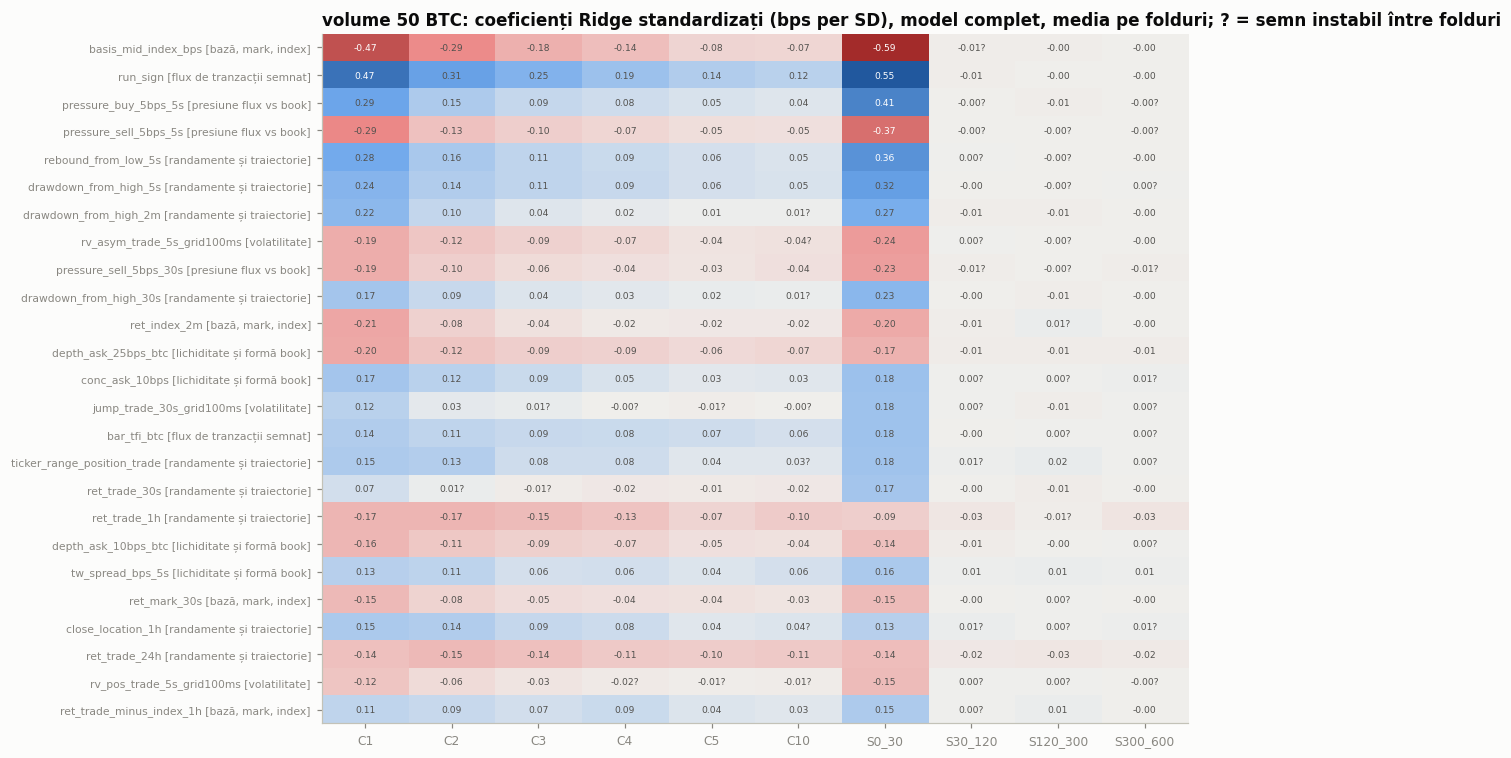

In [34]:
def ridge_coef_table(s, targets):
    rows = {}
    for t in targets:
        r = load_cell("native", s, t, "FULL")
        C_ = np.stack([f["coef"] for f in r["folds"] if "coef" in f])
        rows[t] = pd.DataFrame({"coef": C_.mean(0), "semn_stabil": (np.sign(C_) == np.sign(C_.mean(0))).mean(0)}, index=r["cols"])
    return rows


RC = ridge_coef_table(S1, [f"C{h}" for h in CLOCK_H] + SEG_T)
top = pd.concat([RC[t]["coef"].abs() for t in RC], axis=1).max(1).sort_values(ascending=False).index[:25]
coef = pd.DataFrame({t: RC[t].loc[top, "coef"] for t in RC})
stable = pd.DataFrame({t: RC[t].loc[top, "semn_stabil"] for t in RC})
fig, ax = plt.subplots(figsize=(11, 7))
lim = np.nanmax(np.abs(coef.to_numpy()))
ax.imshow(coef.to_numpy(), aspect="auto", cmap=DIVERGING.reversed(), vmin=-lim, vmax=lim)
ax.set_yticks(range(len(top)), [f"{c} [{FAMILY_LABEL[family_of(c)]}]" for c in top], fontsize=7)
ax.set_xticks(range(coef.shape[1]), coef.columns, fontsize=8)
ax.grid(False)
for i in range(coef.shape[0]):
    for j in range(coef.shape[1]):
        ax.text(j, i, f"{coef.iat[i, j]:.2f}{'' if stable.iat[i, j] >= 6 / 7 else '?'}", ha="center", va="center", fontsize=6,
                color="white" if abs(coef.iat[i, j]) > 0.6 * lim else INK2)
ax.set_title(f"{LABEL[S1]}: coeficienți Ridge standardizați (bps per SD), model complet, media pe folduri; ? = semn instabil între folduri")
fig.tight_layout()
plt.show()

**Sensul relațiilor (partial, din ridge).** Semnele coeficienților sunt stabile între folduri și **identice la 1, 2, 5 și 10 minute și la 0–30 s**, apoi coeficienții devin ~0 pe intervalele de după 30 s. Pe volume: semnul seriei curente de tranzacții, presiunea de cumpărare față de adâncimea de pe ask și distanța față de minimul ultimelor 5 s au coeficienți pozitivi (continuare), iar baza mid−index are coeficient negativ (când mid-ul perpetual-ului a urcat peste index, el revine). Pe `time_1m`, `qi_1`, adâncimea pe bid și costul de cumpărare sunt pozitive, adâncimea pe ask și costul de vânzare negative: aceeași informație de imbalance, împărțită între coloane. Nu apare nicio inversare de semn între orizonturi. Singura excepție de formă: randamentele pe 1 h și 24 h au coeficienți negativi stabili la toate orizonturile, care rămân ușor negativi (−0,02 … −0,03 bps per SD) și pe intervalele de după 30 s; este singurul indiciu de reversie lentă, mic și nesemnificativ individual (secțiunea 13.5).

### 13.5 Informația individuală (SFI, exhaustiv) și sensul relațiilor

In [35]:
N_PLACEBO_FEAT = 20
SFI_SUB = 300_000
SFI_BINS = 20
SFI_PRIOR = 200          # bin means are shrunk towards zero with the weight of 200 observations


def sfi_targets(s):
    return [f"C{h}" for h in CLOCK_H] + ([f"B{k}" for k in BAR_K] if s != "time_1m" else []) + [f"S{a}_{b}" for a, b in SEGMENTS] + ["P1"]


def placebo_specs(s, ncols):
    rng = np.random.default_rng(SEED + 7)
    n = len(META_TNS_ALL[s])
    src = rng.choice([i for i, c in enumerate(INFO[s]["columns"]) if c != "qi_1"], N_PLACEBO_FEAT, replace=False)
    return [(int(j), int(rng.integers(int(0.3 * n), int(0.7 * n)))) for j in src]


def sfi_worker(task):
    """Single-feature importance, out of sample: per fold, a 20-bin step function (NaN = own bin, bins from train quantiles, means shrunk
    to zero) and a linear slope, both learned on the training window only; daily squared errors on the test fold."""
    s, jlist = task
    threadpool_limits(1)
    X, tns, Y, T1, ok_tr, ok_te = CTX["XF"], CTX["tns"], CTX["Y"], CTX["T1"], CTX["ok_train"], CTX["ok_test"]
    day_all = (tns // (86400 * NS) - DAY0).astype(np.int64)
    out = {}
    for j in jlist:
        if j < X.shape[1]:
            x = X[:, j]
        else:
            src, sh = CTX["placebo"][j - X.shape[1]]
            x = np.roll(X[:, src], sh)
        for t in CTX["targets"]:
            yv = Y[t].astype(np.float64)
            Bb, Bl, betas = np.zeros(ND), np.zeros(ND), []
            for fi, (a, b) in enumerate(FOLDS):
                tr, te = CTX["rows"][(t, fi)]
                if len(tr) == 0:
                    continue
                trs = tr if len(tr) <= SFI_SUB else tr[np.linspace(0, len(tr) - 1, SFI_SUB).astype(np.int64)]
                lo, hi = CTX["clip"][(t, fi)]
                ytr = np.clip(yv[trs], lo, hi)
                xtr, xte, yte = x[trs], x[te], yv[te]
                fin = np.isfinite(xtr)
                if fin.sum() < 1000:
                    betas.append(np.nan)
                    continue
                edges = np.unique(np.nanquantile(xtr[fin], np.linspace(0, 1, SFI_BINS + 1)[1:-1]))
                nb = len(edges) + 2
                btr = np.where(fin, np.searchsorted(edges, np.nan_to_num(xtr), side="right"), nb - 1)
                fte = np.isfinite(xte)
                bte = np.where(fte, np.searchsorted(edges, np.nan_to_num(xte), side="right"), nb - 1)
                cnt = np.bincount(btr, minlength=nb)
                sm = np.bincount(btr, ytr, minlength=nb)
                pb = (sm / (cnt + SFI_PRIOR))[bte]
                mu, sd = xtr[fin].mean(), xtr[fin].std() or 1.0
                ztr = (xtr[fin] - mu) / sd
                beta = (ztr * ytr[fin]).sum() / (ztr * ztr).sum()
                pl = np.where(fte, beta * (np.nan_to_num(xte) - mu) / sd, 0.0)
                dte = day_all[te]
                Bb += np.bincount(dte, (yte - pb) ** 2, ND)
                Bl += np.bincount(dte, (yte - pl) ** 2, ND)
                betas.append(beta)
            out[(j, t)] = (Bb.astype(np.float32), Bl.astype(np.float32), np.array(betas, np.float32))
    return out


def run_sfi(s):
    p = CACHE / f"sfi_{s}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    tg = TG[s]
    tns = META_TNS_ALL[s]
    XF = np.asfortranarray(np.load(CACHE / f"feat_{s}" / "X.npy"))         # column-major copy: contiguous columns for the workers
    targets = sfi_targets(s)
    ok_tr, ok_te = tg["elig"] & ~tg["crash"], tg["elig"] & ~tg["crash"]
    rows, clip, A = {}, {}, {}
    day_all = (tns // (86400 * NS) - DAY0).astype(np.int64)
    for t in targets:
        Aa = np.zeros(ND)
        for fi, (a, b) in enumerate(FOLDS):
            tr, te = fold_rows(tns, tg["T1"][t], tg["Y"][t], ok_tr, ok_te, a, b)
            rows[(t, fi)] = (tr, te)
            clip[(t, fi)] = tuple(np.percentile(tg["Y"][t][tr].astype(np.float64), [0.1, 99.9])) if len(tr) else (0, 0)
            Aa += np.bincount(day_all[te], tg["Y"][t][te].astype(np.float64) ** 2, ND)
        A[t] = Aa
    CTX.clear()
    CTX.update({"XF": XF, "tns": tns, "Y": tg["Y"], "T1": tg["T1"], "ok_train": ok_tr, "ok_test": ok_te, "targets": targets,
                "rows": rows, "clip": clip, "placebo": placebo_specs(s, XF.shape[1])})
    ncol = XF.shape[1] + N_PLACEBO_FEAT
    chunks = [(s, list(range(i, ncol, WORKERS * 3))) for i in range(WORKERS * 3)]
    res = {}
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=mp.get_context("fork")) as ex:
        for part in ex.map(sfi_worker, chunks):
            res.update(part)
    names = list(INFO[s]["columns"]) + [f"PLACEBO_{k:02d}_{INFO[s]['columns'][src]}" for k, (src, _) in enumerate(CTX["placebo"])]
    CTX.clear()
    del XF
    gc.collect()
    out = {"names": names, "targets": targets, "A": A, "res": res}
    p.write_bytes(pickle.dumps(out, protocol=5))
    return out


def sfi_table(S):
    """R² (%) of each single-feature step function and linear fit, block-bootstrap p-value (H0: R² <= 0), BH q within each target."""
    rows = []
    for t in S["targets"]:
        A = S["A"][t]
        Bb = np.stack([S["res"][(j, t)][0] for j in range(len(S["names"]))], 1).astype(np.float64)
        Bl = np.stack([S["res"][(j, t)][1] for j in range(len(S["names"]))], 1).astype(np.float64)
        gain_b = A[:, None] - Bb
        boot = (WBOOT @ gain_b) / (WBOOT @ A)[:, None]
        r2b = gain_b.sum(0) / A.sum()
        r2l = (A[:, None] - Bl).sum(0) / A.sum()
        pb = (boot <= 0).mean(0)
        betas = np.stack([S["res"][(j, t)][2] for j in range(len(S["names"]))], 0)
        for j, nm in enumerate(S["names"]):
            rows.append({"feature": nm, "țintă": t, "r2_bin": 100 * r2b[j], "lo": 100 * np.percentile(boot[:, j], 2.5),
                         "hi": 100 * np.percentile(boot[:, j], 97.5), "p": pb[j], "r2_lin": 100 * r2l[j],
                         "panta_bps_per_sd": np.nanmean(betas[j]), "semn_stabil": np.nanmean(np.sign(betas[j]) == np.sign(np.nanmean(betas[j])))})
    T = pd.DataFrame(rows)
    T["placebo"] = T["feature"].str.startswith("PLACEBO_")
    T["q"] = np.nan
    for t, g in T.groupby("țintă"):
        T.loc[g.index, "q"] = bh(g["p"].to_numpy())
    return T


t_ = time.time()
SFI = {s: run_sfi(s) for s in SETS}
SFI_T = {s: sfi_table(SFI[s]) for s in SETS}
print(f"SFI exhaustiv: {sum(len(SFI[s]['names']) for s in SETS)} coloane (inclusiv {N_PLACEBO_FEAT} placebo pe set) × toate țintele native "
      f"× {len(FOLDS)} folduri, în {(time.time() - t_) / 60:.1f} min.")

SFI exhaustiv: 1507 coloane (inclusiv 20 placebo pe set) × toate țintele native × 7 folduri, în 0.1 min.


In [36]:
rows = []
for s in SETS:
    T = SFI_T[s]
    for t, g in T.groupby("țintă", sort=False):
        real, plc = g[~g["placebo"]], g[g["placebo"]]
        rows.append({"set": s, "țintă": t, "features reale cu q < 0,05": int((real["q"] < 0.05).sum()), "din": len(real),
                     "placebo cu q < 0,05": int((plc["q"] < 0.05).sum()), "din placebo": len(plc),
                     "reale peste maximul placebo": int((real["r2_bin"] > plc["r2_bin"].max()).sum()),
                     "așteptat întâmplător": len(real) / (len(plc) + 1), "cel mai bun feature": real.sort_values("r2_bin").iloc[-1]["feature"],
                     "R² maxim (%)": real["r2_bin"].max(), "R² maxim placebo (%)": plc["r2_bin"].max()})
SFI_SUM = pd.DataFrame(rows)
display(Markdown("**SFI exhaustiv (fiecare feature singur, funcție în trepte pe 20 de cuantile învățată pe train): câte features au informație individuală.**"))
display(SFI_SUM.set_index(["set", "țintă"]).round(4))

**SFI exhaustiv (fiecare feature singur, funcție în trepte pe 20 de cuantile învățată pe train): câte features au informație individuală.**

features reale cu q < 0,05  din  placebo cu q < 0,05  din placebo  reale peste maximul placebo  așteptat întâmplător               cel mai bun feature  R² maxim (%)  R² maxim placebo (%)
set           țintă                                                                                                                                                                                               
time_1m       C1                                25  355                    0           20                          120               16.9048                              qi_1        0.5361               -0.0044
              C2                                26  355                    0           20                          119               16.9048                              qi_1        0.2322               -0.0043
              C3                                18  355                    0           20                          133               16.9048                              qi_1        0.1480               -0.0058
              C4                                14  355                    0           20                           97               16.9048                              qi_1        0.1112               -0.0040
              C5                                11  355                    0           20                           85               16.9048                              qi_1        0.0827               -0.0030
              C10                                6  355                    0           20                           65               16.9048                              qi_1        0.0359               -0.0033
              S0_30                             41  355                    0           20                           94               16.9048                              qi_1        0.9958               -0.0053
              S30_120                            0  355                    0           20                           57               16.9048   path_efficiency_trade_2m_grid1s        0.0036               -0.0052
              S120_300                           0  355                    0           20                           37               16.9048             vwap_distance_15m_bps        0.0060               -0.0033
              S300_600                           0  355                    0           20                           26               16.9048               rebound_from_low_1h        0.0017               -0.0048
              P1                                 0  355                    0           20                           35               16.9048          liq_to_trade_notional_2m        0.0002               -0.0036
volume_50btc  C1                                43  357                    0           20                           96               17.0000                          run_sign        0.9956               -0.0050
              C2                                32  357                    0           20                           71               17.0000                          run_sign        0.5165               -0.0063
              C3                                18  357                    0           20                           66               17.0000                          run_sign        0.3503               -0.0066
              C4                                11  357                    0           20                           41               17.0000                          run_sign        0.2651                0.0033
              C5                                 8  357                    0           20                           37               17.0000                          run_sign        0.1938                0.0017
              C10                                1  357                    0           20                           27               17.0000         signed_large_flow_1h_usdt        0.1423               -0.0001
              B

**Informația individuală este concentrată și scurtă.** Numărul de features individual semnificative (BH q < 0,05):

* **`time_1m`:** 25 la 1 minut → 11 la 5 minute → 6 la 10 minute; 41 la 0–30 s și **zero** la 30 s–2 min, 2–5 min și 5–10 min. Cel mai bun este `qi_1` la toate orizonturile.
* **Volume și dollar:** 40–43 la 1 minut → 1 la 10 minute; 66–69 la 0–30 s, zero după. Cel mai bun este `run_sign` (semnul seriei curente de tranzacții agresive).
* **CUSUM:** doar 2 la 1–2 minute și 0 mai departe pe ceas; 112–139 pe orizonturi în bare (starea barei: `cusum_pre_reset`, `bar_return_log`).
* **Controale:** niciun feature placebo nu are q < 0,05, iar pe ținta placebo nu există niciun feature semnificativ. Coloana „peste maximul placebo” este puțin informativă aici: contracția spre zero face ca placebo-urile să aibă R² ușor negativ, deci multe features reale cu R² minuscul pozitiv îl depășesc; criteriul relevant este q.

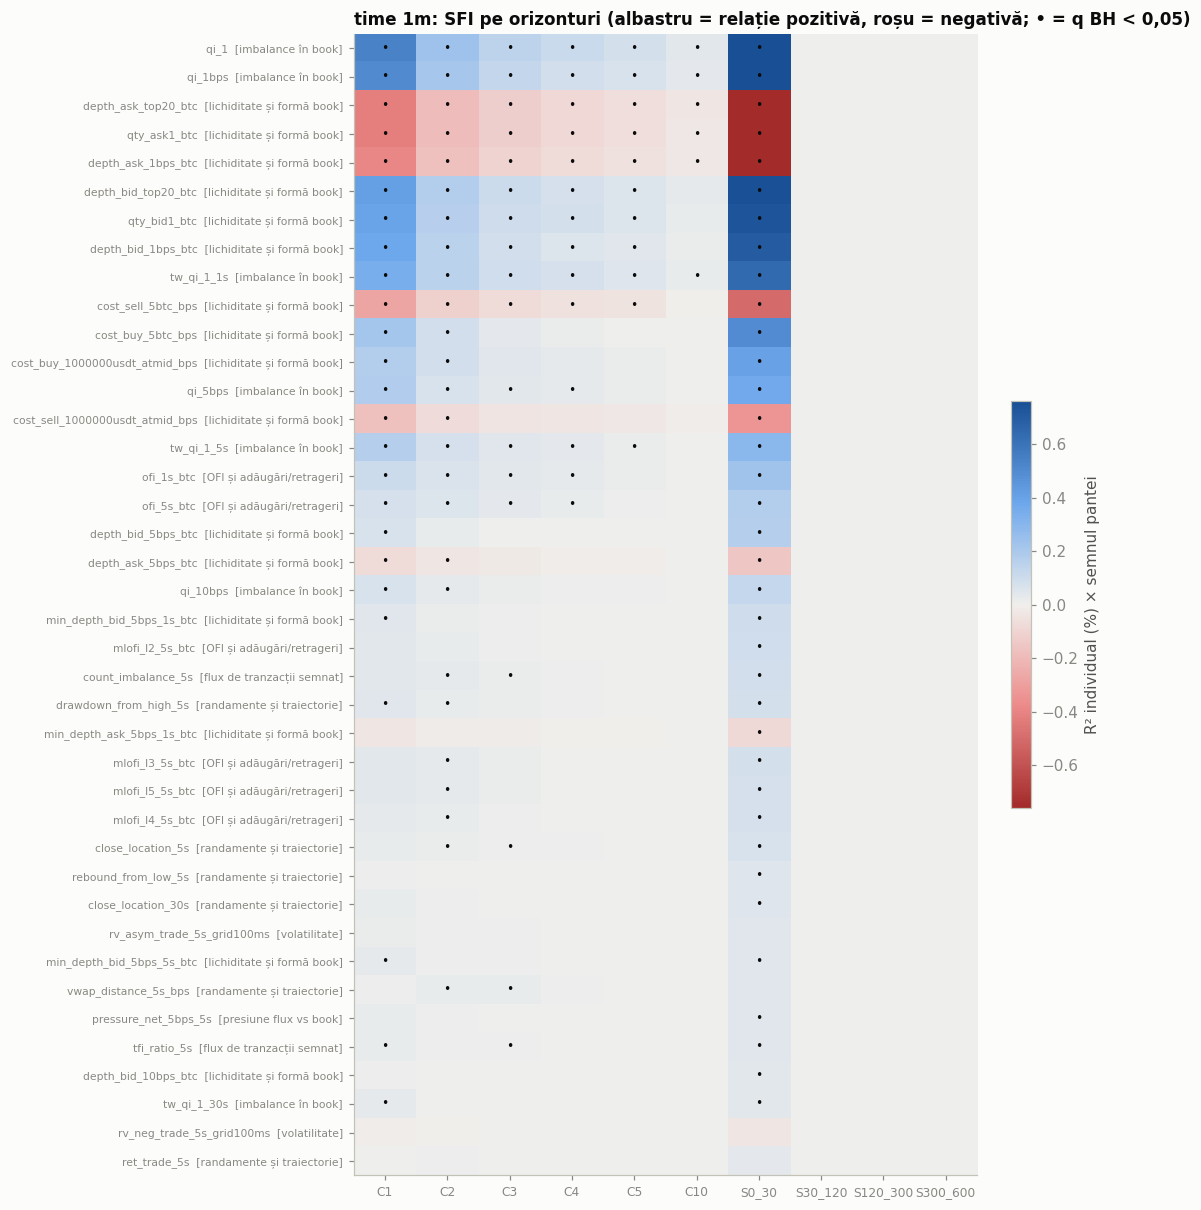

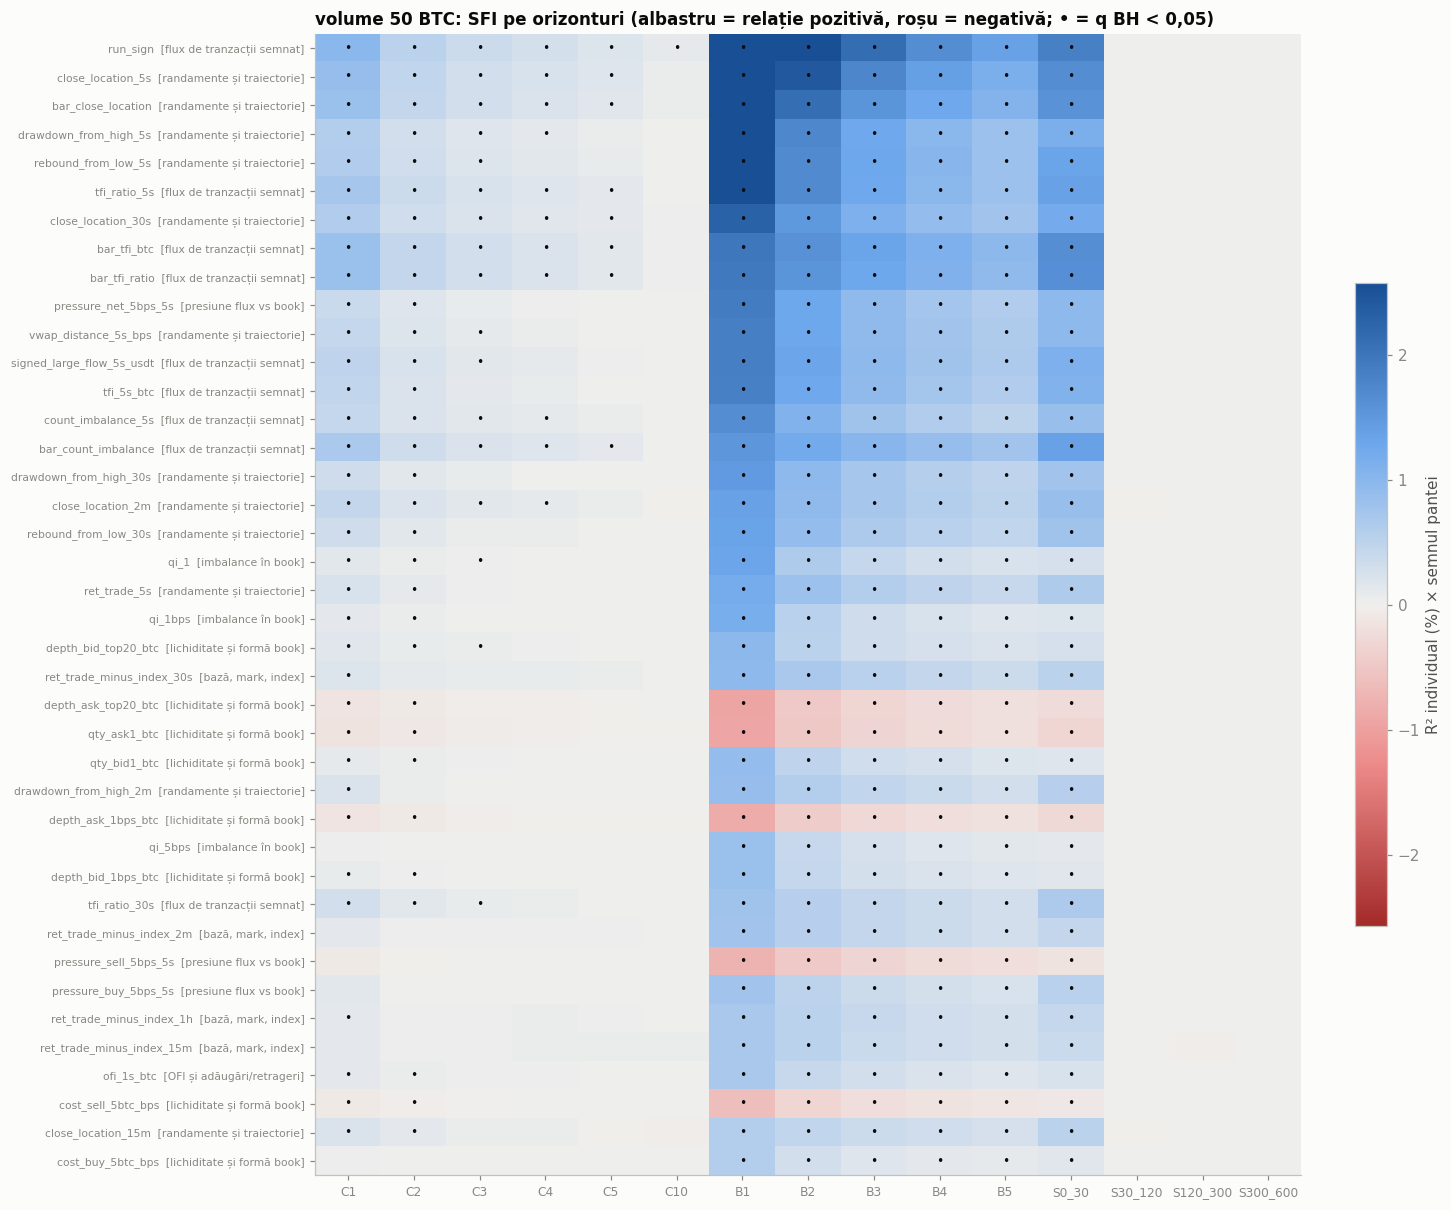

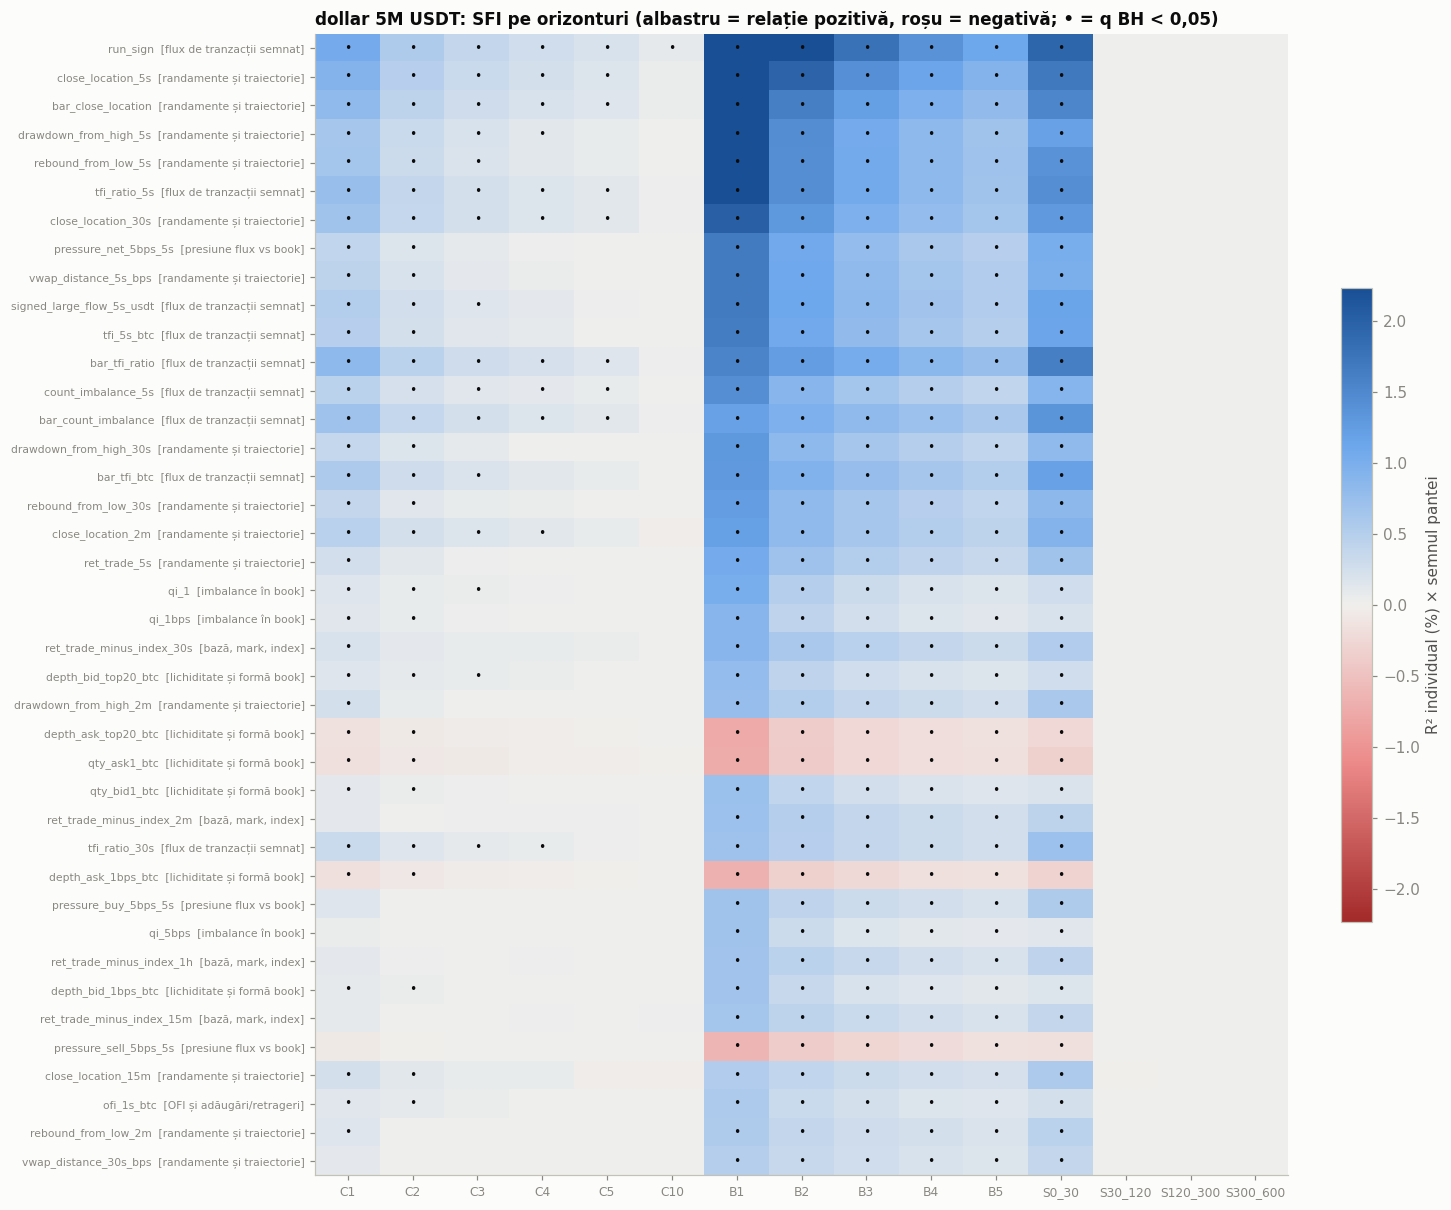

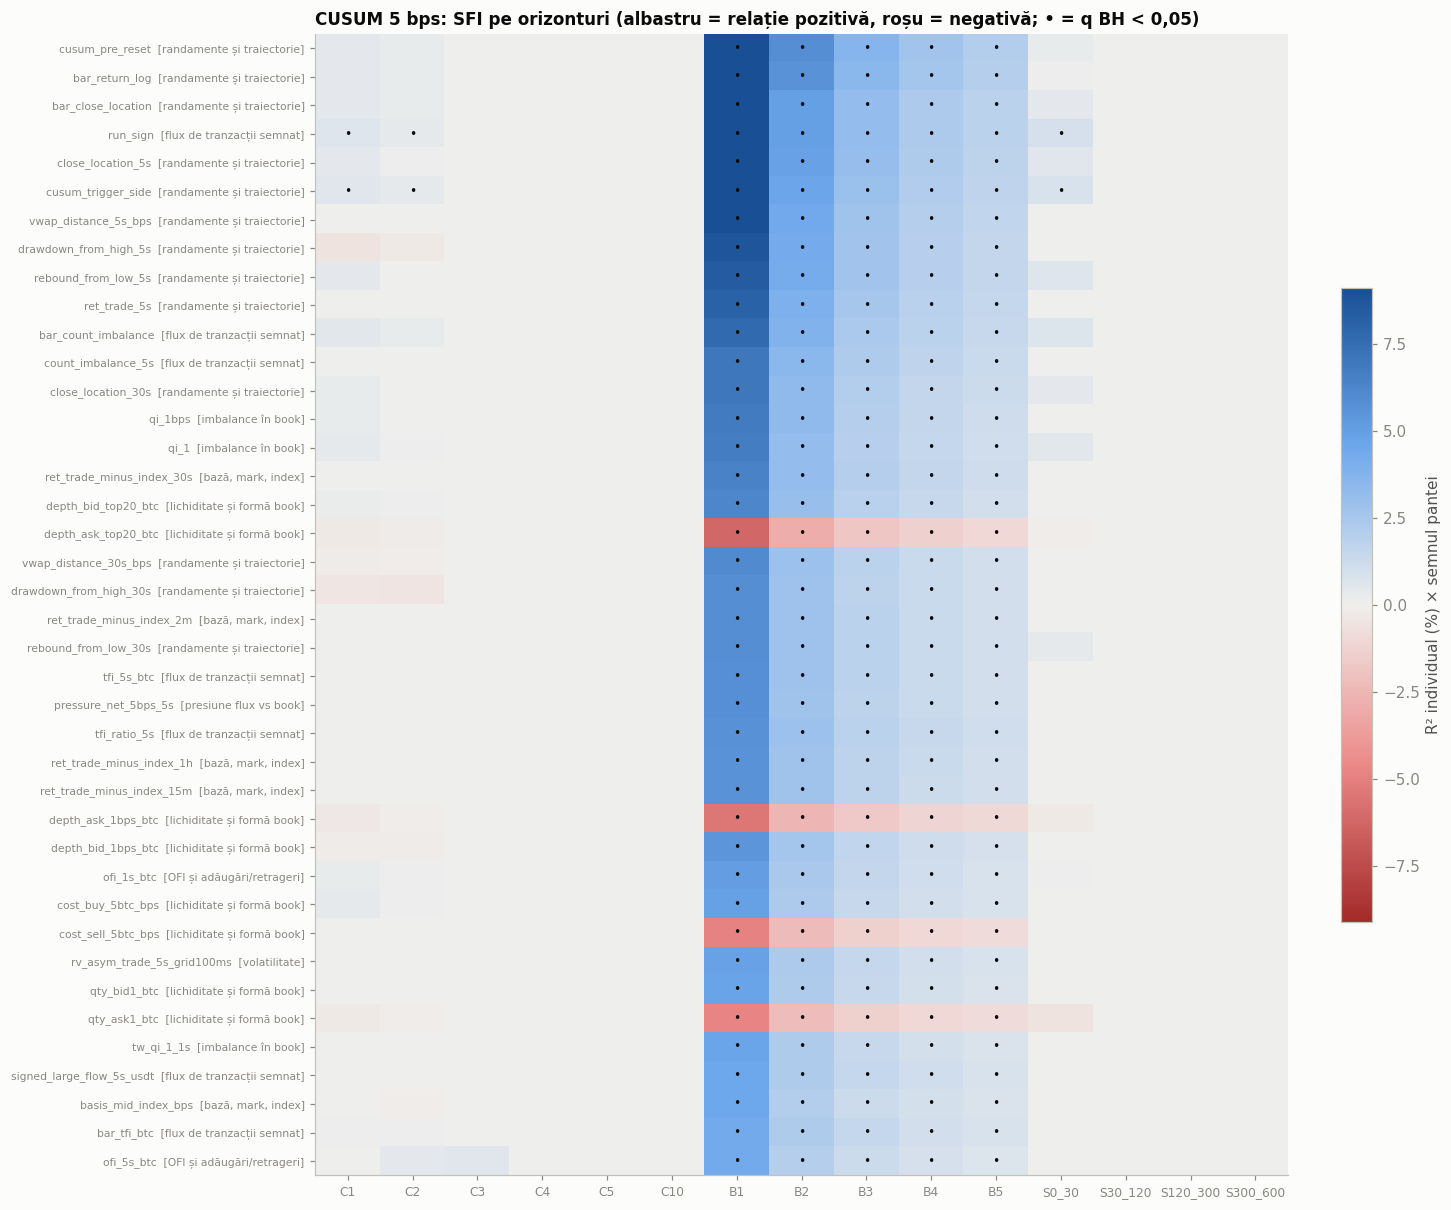

In [37]:
def sfi_heat(s, n_top=40):
    T = SFI_T[s]
    T = T[~T["placebo"]]
    targets = [t for t in sfi_targets(s) if not t.startswith("P")]
    piv = T.pivot(index="feature", columns="țintă", values="r2_bin")[targets]
    sgn = T.pivot(index="feature", columns="țintă", values="panta_bps_per_sd")[targets]
    q = T.pivot(index="feature", columns="țintă", values="q")[targets]
    top = piv.max(1).sort_values(ascending=False).index[:n_top]
    M = piv.loc[top]
    fig, ax = plt.subplots(figsize=(0.62 * len(targets) + 4, 0.24 * n_top + 1.5))
    lim = np.nanpercentile(np.abs(M.to_numpy()), 99)
    V = np.sign(sgn.loc[top].to_numpy()) * np.clip(M.to_numpy(), 0, None)
    im = ax.imshow(V, aspect="auto", cmap=DIVERGING.reversed(), vmin=-lim, vmax=lim)
    ax.set_yticks(range(len(top)), [f"{c}  [{FAMILY_LABEL[family_of(c)]}]" for c in top], fontsize=7)
    ax.set_xticks(range(len(targets)), targets, fontsize=8)
    ax.grid(False)
    for i in range(len(top)):
        for j in range(len(targets)):
            if q.loc[top].iat[i, j] < 0.05 and M.iat[i, j] > 0:
                ax.text(j, i, "•", ha="center", va="center", fontsize=8, color=INK)
    fig.colorbar(im, ax=ax, fraction=0.03, label="R² individual (%) × semnul pantei")
    ax.set_title(f"{LABEL[s]}: SFI pe orizonturi (albastru = relație pozitivă, roșu = negativă; • = q BH < 0,05)")
    fig.tight_layout()
    plt.show()


for s in SETS:
    sfi_heat(s)

**Cum arată hărțile.** Pe fiecare set, aceleași câteva rânduri sunt colorate de la 1 la 10 minute și la 0–30 s, iar coloanele intervalelor de după 30 s sunt goale. Pe `time_1m`: imbalance-ul, adâncimea și cantitatea de pe bid (relație pozitivă) și cele de pe ask (negativă), costul de cumpărare vs. vânzare. Pe volume și dollar: semnul seriei curente, poziția prețului în range-ul ultimelor 5 s, fluxul semnat pe 5 s și pe bară. Pe CUSUM, starea barei pe orizonturile în bare, cu semnificație aproape nulă pe ceas. Intensitatea scade monoton cu orizontul pentru fiecare rând, fără schimbări de culoare (semn).

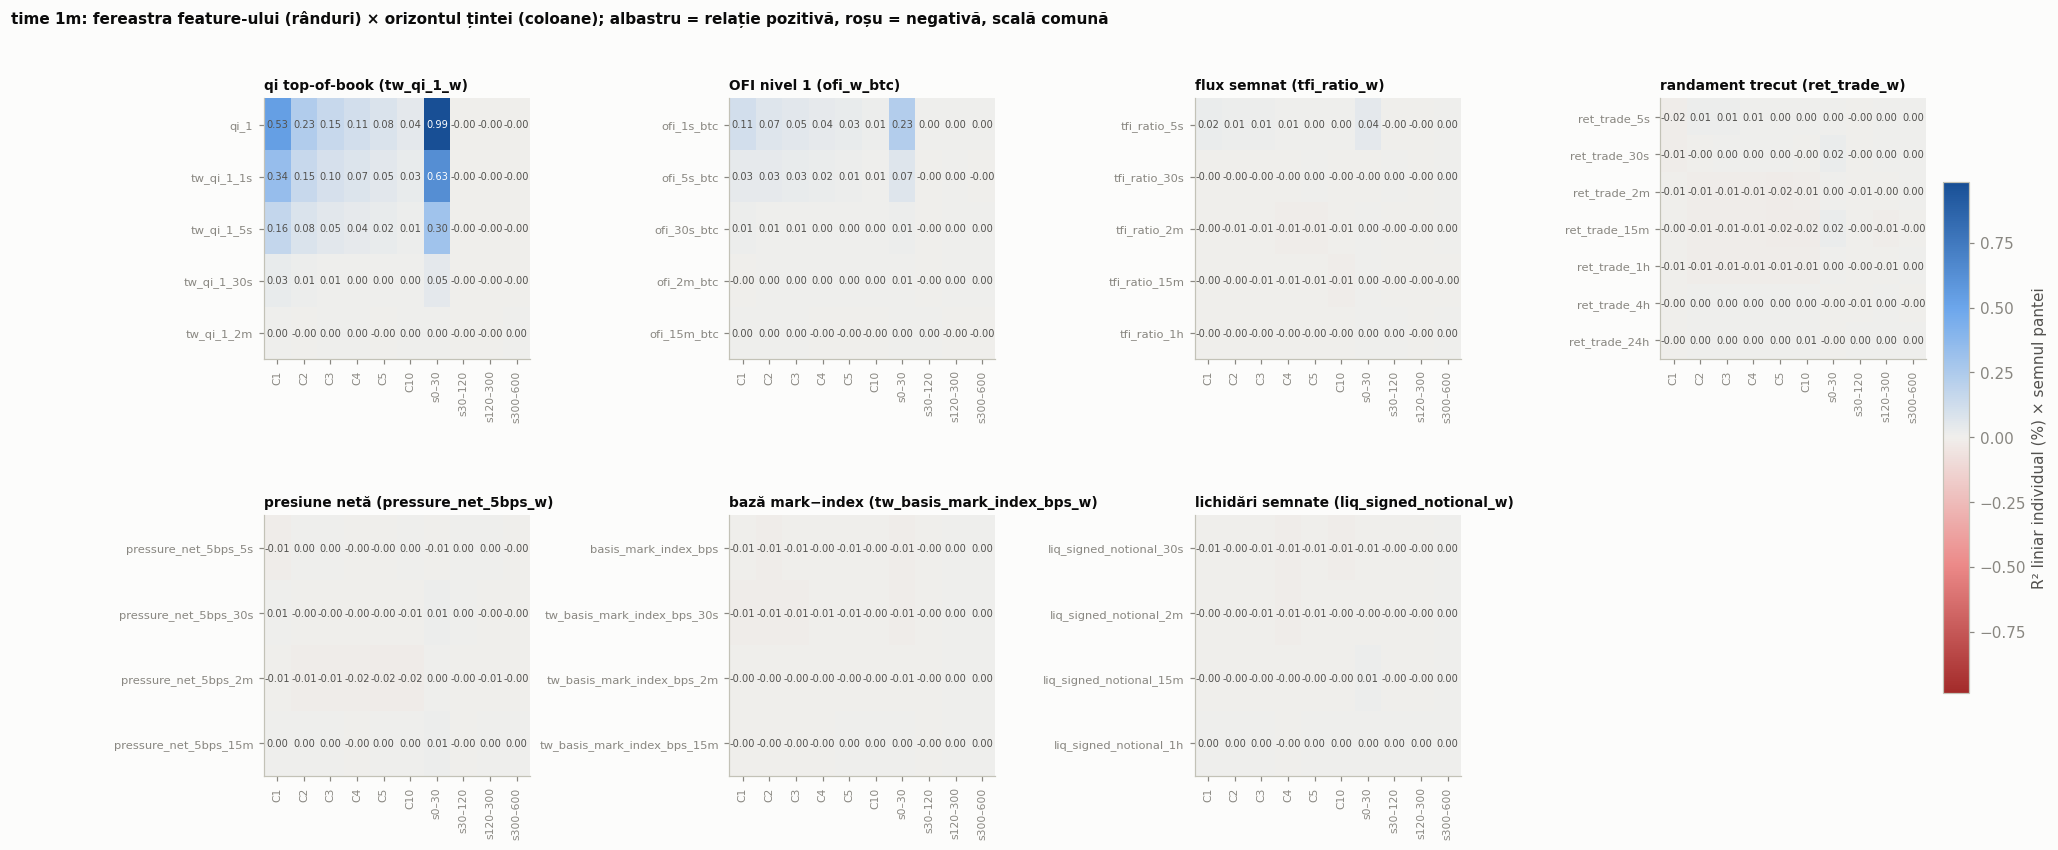

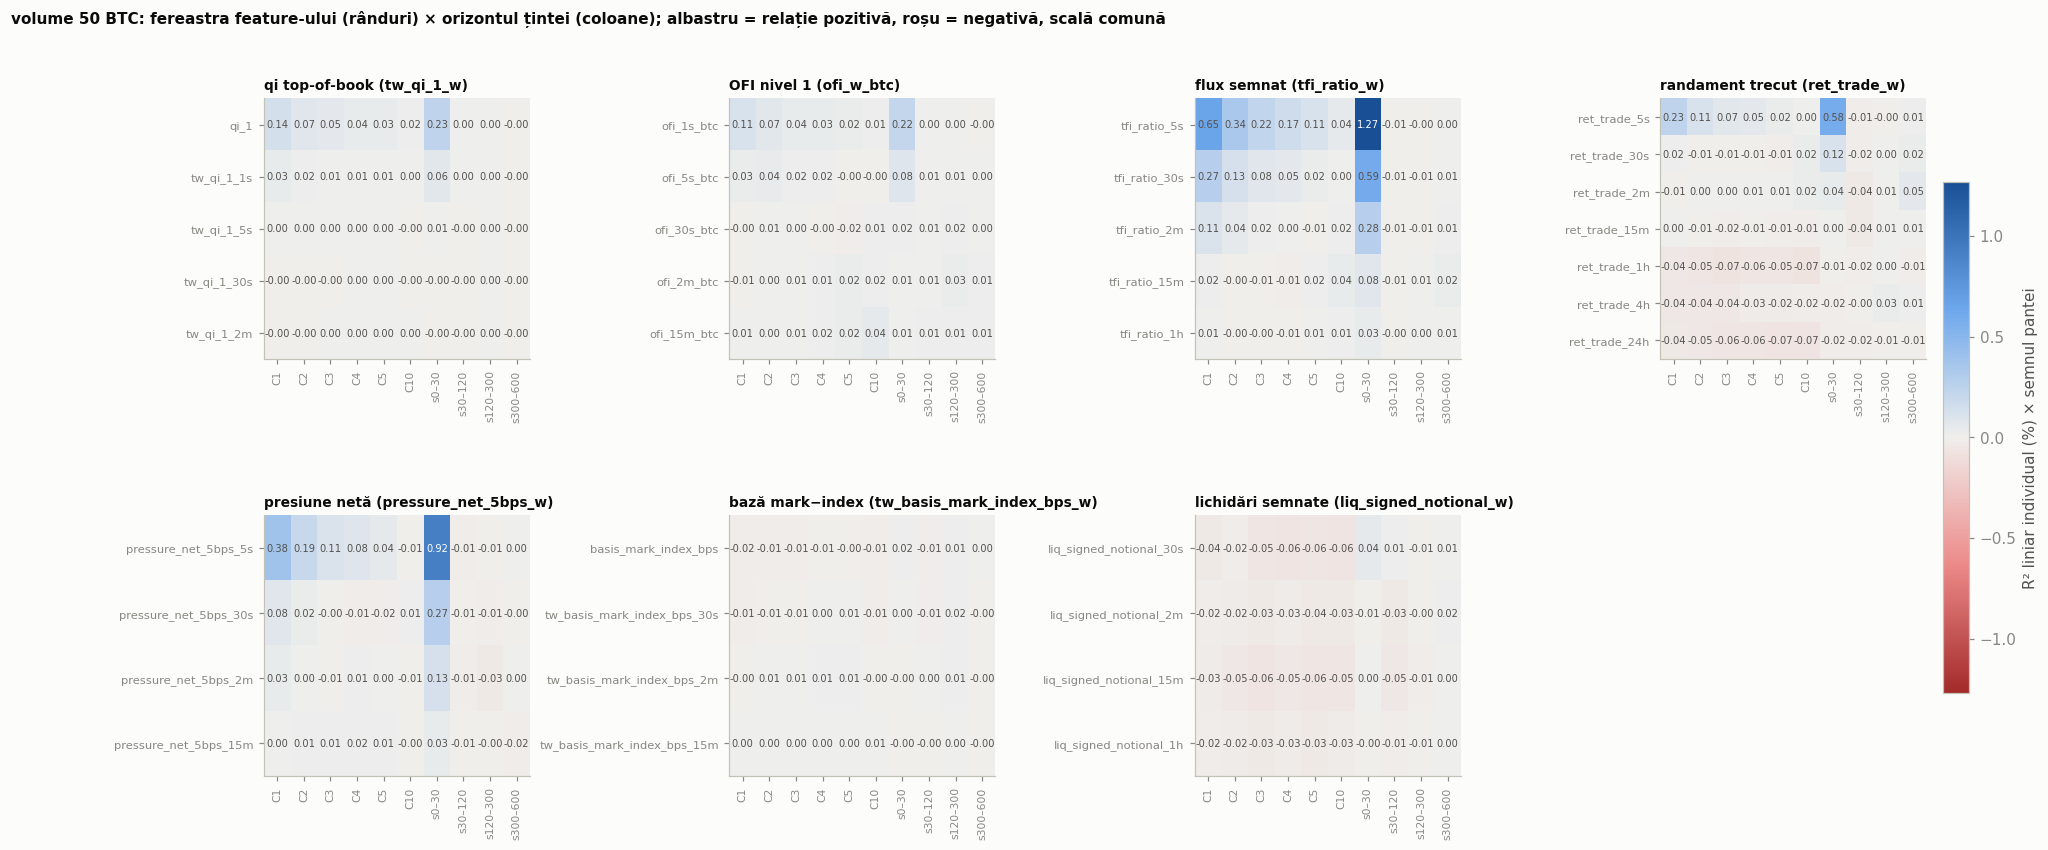

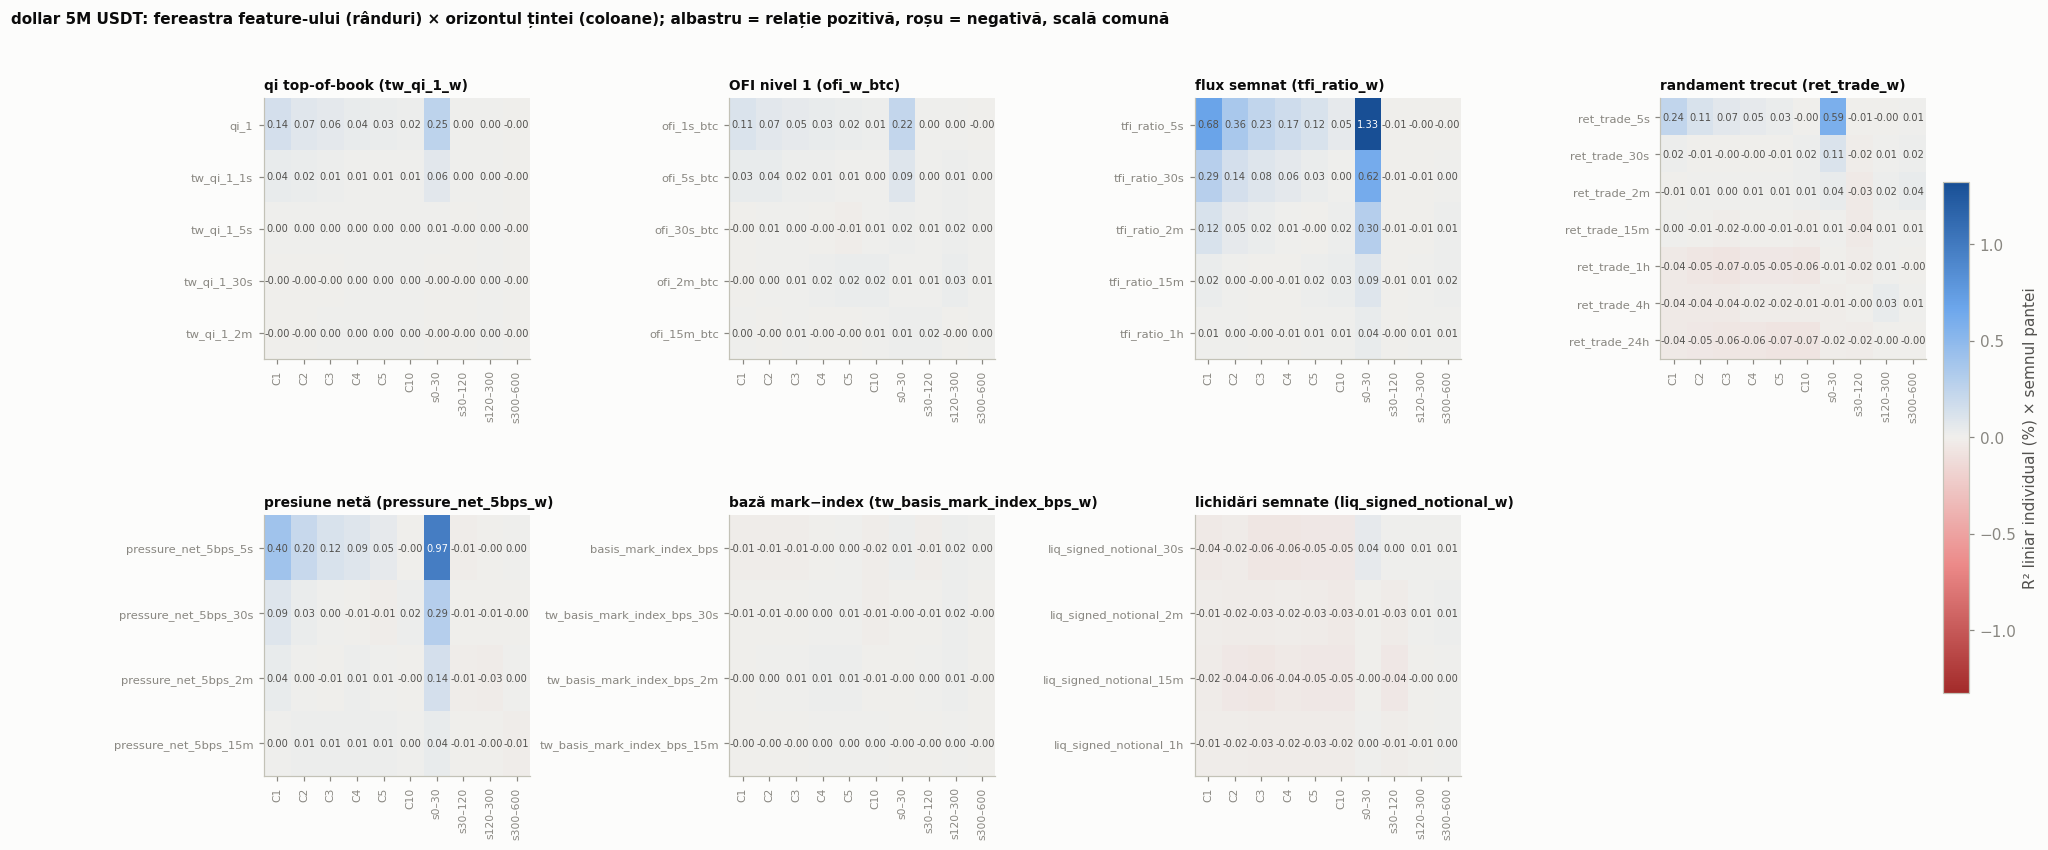

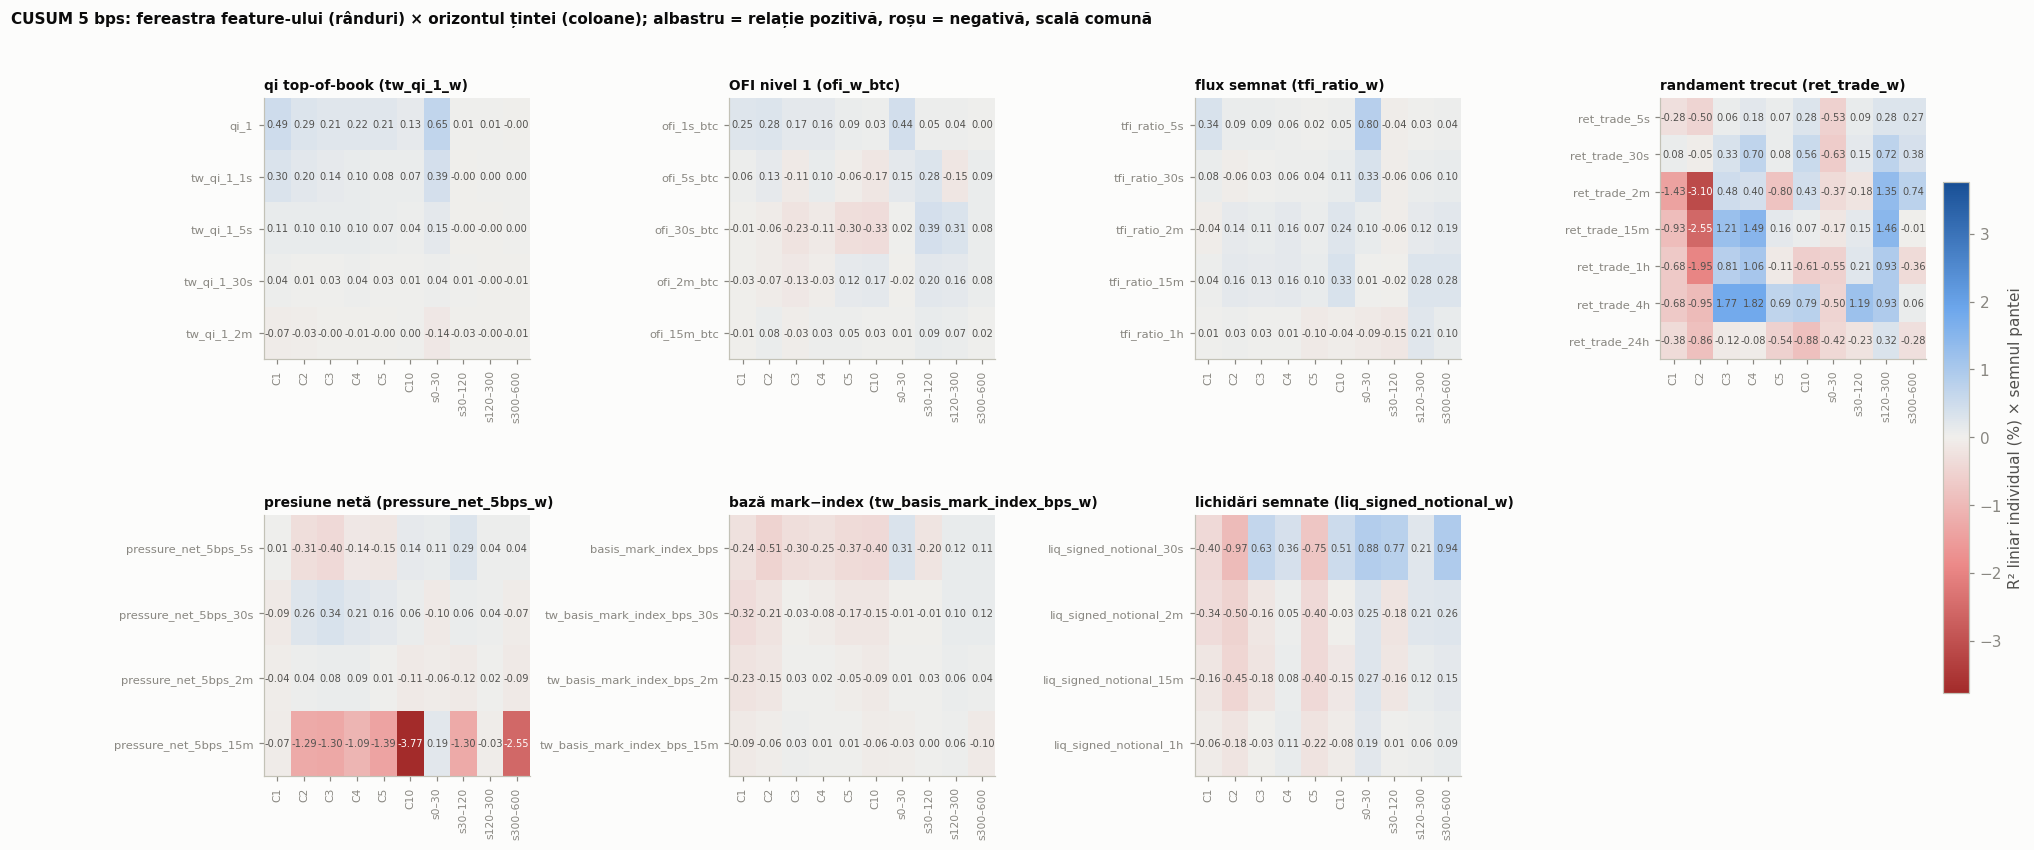

In [38]:
FEATURE_TYPES = {"qi top-of-book (tw_qi_1_w)": ["qi_1", "tw_qi_1_1s", "tw_qi_1_5s", "tw_qi_1_30s", "tw_qi_1_2m"],
                 "OFI nivel 1 (ofi_w_btc)": ["ofi_1s_btc", "ofi_5s_btc", "ofi_30s_btc", "ofi_2m_btc", "ofi_15m_btc"],
                 "flux semnat (tfi_ratio_w)": ["tfi_ratio_5s", "tfi_ratio_30s", "tfi_ratio_2m", "tfi_ratio_15m", "tfi_ratio_1h"],
                 "randament trecut (ret_trade_w)": ["ret_trade_5s", "ret_trade_30s", "ret_trade_2m", "ret_trade_15m", "ret_trade_1h", "ret_trade_4h", "ret_trade_24h"],
                 "presiune netă (pressure_net_5bps_w)": ["pressure_net_5bps_5s", "pressure_net_5bps_30s", "pressure_net_5bps_2m", "pressure_net_5bps_15m"],
                 "bază mark−index (tw_basis_mark_index_bps_w)": ["basis_mark_index_bps", "tw_basis_mark_index_bps_30s", "tw_basis_mark_index_bps_2m", "tw_basis_mark_index_bps_15m"],
                 "lichidări semnate (liq_signed_notional_w)": ["liq_signed_notional_30s_usdt", "liq_signed_notional_2m_usdt", "liq_signed_notional_15m_usdt", "liq_signed_notional_1h_usdt"]}


def window_horizon(s):
    """One colour scale for all panels of a set, so that tiny values stay pale; blue = positive slope, red = negative."""
    T = SFI_T[s].set_index(["feature", "țintă"])
    tg = [f"C{h}" for h in CLOCK_H] + SEG_T
    types = {k: [c for c in v if (c, "C1") in T.index] for k, v in FEATURE_TYPES.items()}
    types = {k: v for k, v in types.items() if v}
    mats = {k: np.array([[T.loc[(c, t), "r2_lin"] * np.sign(T.loc[(c, t), "panta_bps_per_sd"]) for t in tg] for c in feats]) for k, feats in types.items()}
    lim = max(max(np.nanmax(np.abs(M)) for M in mats.values()), 1e-4)
    ncol = 4
    nrow = int(np.ceil(len(types) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 4.0 * nrow), gridspec_kw={"wspace": 0.75, "hspace": 0.6})
    axes = np.atleast_2d(axes).ravel()
    for ax, (k, feats) in zip(axes, types.items()):
        M = mats[k]
        im = ax.imshow(M, aspect="auto", cmap=DIVERGING.reversed(), vmin=-lim, vmax=lim)
        ax.set_yticks(range(len(feats)), [c.replace("_usdt", "") for c in feats], fontsize=7.5)
        ax.set_xticks(range(len(tg)), [t.replace("S", "s").replace("_", "–") for t in tg], fontsize=7, rotation=90)
        ax.grid(False)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(M[i, j]) > 0.6 * lim else INK2)
        ax.set_title(k, fontsize=9)
    for ax in axes[len(types):]:
        ax.axis("off")
    fig.colorbar(im, ax=axes.tolist(), fraction=0.015, pad=0.01, label="R² liniar individual (%) × semnul pantei")
    fig.suptitle(f"{LABEL[s]}: fereastra feature-ului (rânduri) × orizontul țintei (coloane); albastru = relație pozitivă, roșu = negativă, scală comună",
                 x=0.01, ha="left", fontsize=10, fontweight="semibold")
    plt.show()


for s in SETS:
    window_horizon(s)

**Fereastra feature-ului nu se potrivește cu orizontul țintei.** La orice orizont, inclusiv 10 minute, cea mai informativă este fereastra cea mai scurtă: `qi_1` instantaneu > `tw_qi_1_1s` > 5 s > 30 s ≈ 0, iar `tw_qi_1_2m` are exact zero; `tfi_ratio_5s` > 30 s > 2 min > 15 min; `ret_trade_5s` domină pe barele de evenimente. Un OFI sau un flux calculat pe 2 minute **nu** aduce informație pentru ținta de 2 minute: informația vine din ultimele secunde, iar orizontul mai lung doar o diluează. Singura excepție de semn sunt randamentele pe ferestre lungi (15 min – 24 h), cu pante mici negative la 5–10 minute (reversie lentă), dar fără semnificație individuală (R² ≤ 0,07%), în linie cu notebook-ul despre volatilitate și bariere.

In [39]:
rows = []
for s in SETS:
    T = SFI_T[s]
    T = T[~T["placebo"]]
    seg = T[T["țintă"].isin(SEG_T)].pivot(index="feature", columns="țintă", values="panta_bps_per_sd")[SEG_T]
    q = T[T["țintă"].isin(SEG_T)].pivot(index="feature", columns="țintă", values="q")[SEG_T]
    st = T[T["țintă"].isin(SEG_T)].pivot(index="feature", columns="țintă", values="semn_stabil")[SEG_T]
    for f_ in seg.index:
        sg = np.sign(seg.loc[f_])
        good = (q.loc[f_] < 0.05) & (st.loc[f_] >= 0.85)
        if good.sum() >= 2 and (sg[good] > 0).any() and (sg[good] < 0).any():
            first_pos = sg[good].index[0]
            rows.append({"set": s, "feature": f_, "familie": FAMILY_LABEL[family_of(f_)],
                         **{f"panta {t} (bps/SD)": seg.at[f_, t] for t in SEG_T},
                         "tipar": "+ apoi −" if sg[good].iloc[0] > 0 else "− apoi +"})
SIGN = pd.DataFrame(rows)
display(Markdown("**Schimbări de semn între intervale succesive (pante univariate, semn stabil în ≥ 85% din folduri, q BH < 0,05 în cel puțin două intervale).**"))
display(SIGN.set_index(["set", "feature"]).round(3) if len(SIGN) else "Nicio schimbare de semn care să treacă ambele filtre.")

**Schimbări de semn între intervale succesive (pante univariate, semn stabil în ≥ 85% din folduri, q BH < 0,05 în cel puțin două intervale).**

'Nicio schimbare de semn care să treacă ambele filtre.'

**Nu există schimbări robuste de semn.** Niciun feature nu are un semn stabil și semnificativ într-un interval și semnul opus în altul. „Continuare pe termen scurt, reversie ulterior” nu apare la nivel individual în intervalele de până la 10 minute; reversia lentă din randamentele pe ferestre lungi rămâne sub pragul de semnificație.

### 13.6 Analiza detaliată: features și clustere, cu features placebo în model; MDI ca diagnostic

In [40]:
from sklearn.metrics import silhouette_samples


def learn_clusters(s):
    """Statistical clusters of features, learned on the initial training window only (before 2025-10-01): average-linkage hierarchical
    clustering on the distance sqrt(1 - |Spearman|). Sign is ignored: a feature and its negative are substitutes.
    Deviation from ONC (López de Prado 2020, ch. 4): choosing the number of clusters by the silhouette t-statistic selected the boundary
    solution with a few giant clusters that mix unrelated families, useless against substitution. The dendrogram is therefore cut at an
    average |rho| of 0.5 (distance sqrt(0.5)); the silhouette t-statistic of that cut is reported, together with the ONC-style choice."""
    X = np.load(CACHE / f"feat_{s}" / "X.npy", mmap_mode="r")
    tns = META_TNS_ALL[s]
    init = np.flatnonzero((tns >= START.value) & (tns < INIT_END.value) & TG[s]["elig"])
    rng = np.random.default_rng(SEED + 3)
    pick = np.sort(rng.choice(init, min(len(init), 60_000), replace=False))
    R = pd.DataFrame(np.asarray(X[pick])).rank(pct=True)
    R = R.fillna(R.median()).fillna(0.5)
    rho = np.nan_to_num(np.corrcoef(R.to_numpy(np.float64).T))
    D = np.sqrt(np.clip(1 - np.abs(rho), 0, None))
    np.fill_diagonal(D, 0)
    Z = linkage(squareform(D, checks=False), "average")
    lab = fcluster(Z, np.sqrt(0.5), "distance")
    sil = silhouette_samples(D, lab, metric="precomputed")
    onc = None
    for k in range(8, min(150, len(D) - 1), 2):
        l_ = fcluster(Z, k, "maxclust")
        s_ = silhouette_samples(D, l_, metric="precomputed")
        q = s_.mean() / s_.std()
        if onc is None or q > onc[0]:
            onc = (q, k, int(pd.Series(l_).value_counts().max()))
    cols = INFO[s]["columns"]
    return {"labels": dict(zip(cols, lab)), "k": int(lab.max()), "quality": sil.mean() / sil.std(), "onc_k": onc[1], "onc_quality": onc[0],
            "onc_largest": onc[2]}


CLU = cached("clusters", lambda: {s: learn_clusters(s) for s in SETS})
for s in SETS:
    lab = pd.Series(CLU[s]["labels"])
    print(f"{s:14s} tăietură la |ρ| mediu 0,5: {CLU[s]['k']} clustere (silhouette t = {CLU[s]['quality']:.2f}), mărimea mediană "
          f"{lab.value_counts().median():.0f}, maximă {lab.value_counts().max()}; cluster-ul lui qi_1: {', '.join(lab.index[lab == lab['qi_1']][:8])}. "
          f"Alegerea ONC după silhouette ar fi dat {CLU[s]['onc_k']} clustere (t = {CLU[s]['onc_quality']:.2f}), cel mai mare cu {CLU[s]['onc_largest']} membri.")

time_1m        tăietură la |ρ| mediu 0,5: 71 clustere (silhouette t = 1.44), mărimea mediană 2, maximă 62; cluster-ul lui qi_1: qty_bid1_btc, qty_ask1_btc, qi_1, depth_bid_top20_btc, depth_ask_top20_btc, depth_bid_1bps_btc, depth_ask_1bps_btc, qi_1bps. Alegerea ONC după silhouette ar fi dat 62 clustere (t = 1.52), cel mai mare cu 64 membri.
volume_50btc   tăietură la |ρ| mediu 0,5: 67 clustere (silhouette t = 1.22), mărimea mediană 2, maximă 67; cluster-ul lui qi_1: qty_bid1_btc, qi_1, depth_bid_top20_btc, depth_bid_1bps_btc, qi_1bps, cost_sell_5btc_bps, cost_sell_1000000usdt_atmid_bps, tw_qi_1_1s. Alegerea ONC după silhouette ar fi dat 28 clustere (t = 1.60), cel mai mare cu 112 membri.
dollar_5musdt  tăietură la |ρ| mediu 0,5: 66 clustere (silhouette t = 1.25), mărimea mediană 2, maximă 67; cluster-ul lui qi_1: qty_bid1_btc, qi_1, depth_bid_top20_btc, depth_bid_1bps_btc, qi_1bps, cost_sell_5btc_bps, cost_sell_1000000usdt_atmid_bps, tw_qi_1_1s. Alegerea ONC după silhouette ar fi dat 2

In [41]:
def fi_worker(task):
    """Detailed importance for one (combination, fold): FULL + placebo features; ridge and LightGBM refit with the configuration chosen in
    the main run; out-of-sample permutation importance for every feature (1 circular shift) and for every train-learned cluster (3 shifts)."""
    role, s, t, fi = task
    out_p = CACHE / "fi" / f"{s}__{t}__{fi}.pkl"
    if out_p.exists():
        return
    threadpool_limits(1)
    X, tns, Y, T1 = CTX["X"], CTX["tns"], CTX["Y"], CTX["T1"]
    cols = list(INFO[s]["columns"])
    plc = CTX["placebo"]
    y_all, t1 = Y[t].astype(np.float64), T1[t]
    a, b = FOLDS[fi]
    tr, te = fold_rows(tns, t1, y_all, CTX["ok_train"], CTX["ok_test"], a, b)
    rng = np.random.default_rng(int(hashlib.md5(repr((SEED, s, t, fi)).encode()).hexdigest()[:8], 16))

    def mat(idx):
        M = np.empty((len(idx), len(cols) + len(plc)), np.float32)
        M[:, :len(cols)] = X[idx]
        for k, (src, sh) in enumerate(plc):
            M[:, len(cols) + k] = X[(idx - sh) % len(tns), src]          # placebo = the same column, circularly shifted in time
        return M

    allc = np.arange(len(cols) + len(plc))
    lo, hi = np.percentile(y_all[tr], [0.1, 99.9])
    cut = tns[tr][int((1 - VAL_SHARE) * len(tr))]
    inner, val = tr[t1[tr] < cut], tr[tns[tr] >= cut]
    rin = np.sort(rng.choice(len(inner), min(len(inner), N_RIDGE), replace=False))
    rfull = np.sort(rng.choice(len(tr), min(len(tr), N_RIDGE), replace=False))
    Xh = {"in": mat(inner[rin]), "va": mat(val), "full": mat(tr[rfull])}
    pipe = RidgePipe().fit_prep(Xh["in"], rng)
    G, c = gram(pipe, Xh["in"], np.clip(y_all[inner[rin]], lo, hi))
    w, V = np.linalg.eigh(G)
    Bm = V @ ((V.T @ c)[:, None] / (np.maximum(w, 0)[:, None] + ALPHAS[None, :] * len(rin)))
    ia = int(np.argmin(((pipe.design(Xh["va"]) @ Bm - np.clip(y_all[val], lo, hi)[:, None]) ** 2).mean(0)))
    pipe = RidgePipe().fit_prep(Xh["full"], rng)
    G, c = gram(pipe, Xh["full"], np.clip(y_all[tr[rfull]], lo, hi))
    beta = np.linalg.solve(G + ALPHAS[ia] * len(rfull) * np.eye(len(c)), c)
    lin = np.sort(rng.choice(len(inner), min(len(inner), N_LGB_TRAIN), replace=False))
    lva = np.sort(rng.choice(len(val), min(len(val), N_LGB_VAL), replace=False))
    cfg = LGB_CONFIGS[CTX["cfg"][(s, t, fi)]]
    dtr = lgb.Dataset(mat(inner[lin]), np.clip(y_all[inner[lin]], lo, hi), free_raw_data=False)
    dva = lgb.Dataset(mat(val[lva]), np.clip(y_all[val[lva]], lo, hi), reference=dtr)
    bst = lgb.train({**LGB_BASE, **cfg}, dtr, MAX_ROUNDS, valid_sets=[dva], callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    del Xh, dtr, dva
    pool = te[~CTX["crash"][te]]
    ms = np.sort(rng.choice(pool, min(len(pool), N_MDA), replace=False))
    Xm, ym = mat(ms), y_all[ms]
    pr = lambda M: pipe.design(M) @ beta
    pl = lambda M: bst.predict(M, num_iteration=bst.best_iteration)
    base_r, base_l = ((pr(Xm) - ym) ** 2).sum(), ((pl(Xm) - ym) ** 2).sum()
    names = cols + [f"PLACEBO_{k:02d}" for k in range(len(plc))]
    feat_r, feat_l = np.zeros(len(names)), np.zeros(len(names))
    for j in allc:
        Xp = Xm.copy()
        Xp[:, j] = np.roll(Xm[:, j], int(rng.integers(len(ms) // 4, 3 * len(ms) // 4)))
        feat_r[j] = ((pr(Xp) - ym) ** 2).sum() - base_r
        feat_l[j] = ((pl(Xp) - ym) ** 2).sum() - base_l
    lab = CTX["clusters"]
    groups = {}
    for i, c_ in enumerate(cols):
        groups.setdefault(f"K{lab[c_]:02d}", []).append(i)
    for k in range(len(plc)):
        groups[f"PLACEBO_{k:02d}"] = [len(cols) + k]
    clu_r, clu_l = {}, {}
    for g, gi in groups.items():
        vr, vl = [], []
        for rep in range(3):
            Xp = Xm.copy()
            Xp[:, gi] = np.roll(Xm[:, gi], int(rng.integers(len(ms) // 4, 3 * len(ms) // 4)), axis=0)
            vr.append(((pr(Xp) - ym) ** 2).sum() - base_r)
            vl.append(((pl(Xp) - ym) ** 2).sum() - base_l)
        clu_r[g], clu_l[g] = np.mean(vr), np.mean(vl)
    fam_of = {i: family_of(c_) for i, c_ in enumerate(cols)}
    blocks = {"stare book (imbalance + lichiditate)": {"imbalance_book", "lichiditate_book"},
              "tot book-ul (stare + OFI + presiune + execuție)": {"imbalance_book", "lichiditate_book", "ofi", "presiune_book_flux", "calitate_execuție"},
              "flux de tranzacții semnat": {"flux_semnat"}, "PVC (preț, volum, calendar)": set(PVC_FAMILIES),
              "derivate și piața extinsă": {"bază_index", "funding", "open_interest", "lichidări"},
              "toată microstructura": {"flux_semnat", "imbalance_book", "lichiditate_book", "ofi", "presiune_book_flux", "calitate_execuție"}}
    blocks.update({f"familie: {FAMILY_LABEL[g]}": {g} for g in FAMILY_DISPLAY_ORDER})
    blk_r, blk_l = {}, {}
    for bname, fams in blocks.items():
        gi = [i for i in range(len(cols)) if fam_of[i] in fams]
        if not gi:
            continue
        vr, vl = [], []
        for rep in range(3):
            Xp = Xm.copy()
            Xp[:, gi] = np.roll(Xm[:, gi], int(rng.integers(len(ms) // 4, 3 * len(ms) // 4)), axis=0)
            vr.append(((pr(Xp) - ym) ** 2).sum() - base_r)
            vl.append(((pl(Xp) - ym) ** 2).sum() - base_l)
        blk_r[bname], blk_l[bname] = np.mean(vr), np.mean(vl)
    imp_gain = bst.feature_importance("gain")
    out = {"role": role, "names": names, "y2": float((ym ** 2).sum()), "n": len(ms), "base_r": base_r, "base_l": base_l,
           "feat_r": feat_r, "feat_l": feat_l, "clu_r": clu_r, "clu_l": clu_l, "groups": groups, "lgb_gain": imp_gain, "blk_r": blk_r, "blk_l": blk_l,
           "coef": beta[:len(names)] * 1.0, "iters": bst.best_iteration}
    (CACHE / "fi").mkdir(exist_ok=True)
    out_p.write_bytes(pickle.dumps(out, protocol=5))


def run_fi_combos():
    (CACHE / "fi").mkdir(exist_ok=True)
    for s in dict.fromkeys(c[1] for c in FI_COMBOS):
        tasks = [(role, s_, t, fi) for role, s_, t in FI_COMBOS if s_ == s for fi in range(len(FOLDS))
                 if not (CACHE / "fi" / f"{s_}__{t}__{fi}.pkl").exists()]
        if not tasks:
            continue
        cfg = {}
        for role, s_, t, _ in tasks:
            for rec in load_cell("native", s_, t, "FULL")["folds"]:
                cfg[(s_, t, rec["fold"])] = rec["lgb_cfg"]
        tasks = [x for x in tasks if (x[1], x[2], x[3]) in cfg]
        set_context_native(s)
        CTX["placebo"] = placebo_specs(s, len(INFO[s]["columns"]))
        CTX["clusters"] = CLU[s]["labels"]
        CTX["cfg"] = cfg
        with ProcessPoolExecutor(max_workers=WORKERS, mp_context=mp.get_context("fork")) as ex:
            list(ex.map(fi_worker, tasks))
    CTX.clear()


t_ = time.time()
run_fi_combos()
FI = {}
for role, s, t in FI_COMBOS:
    FI[(s, t)] = [pickle.loads(p.read_bytes()) for p in sorted((CACHE / "fi").glob(f"{s}__{t}__*.pkl"))]
print(f"Importanță detaliată pentru {len(FI_COMBOS)} combinații × {len(FOLDS)} folduri: {(time.time() - t_) / 60:.1f} min.")

Importanță detaliată pentru 9 combinații × 7 folduri: 0.0 min.


In [42]:
from sklearn.ensemble import RandomForestRegressor


def run_mdi(s, t):
    """MDI as in AFML 8.3.1: random forest with max_features = 1 (avoids masking), in-sample impurity decrease, zeros -> NaN.
    Trained once on the development window (before 2026-06-01), 200k rows, FULL + placebo features, median-imputed. A second forest on
    circularly shifted labels shows how much of the MDI ranking is shape (number of distinct values, skew) rather than information."""
    X = np.load(CACHE / f"feat_{s}" / "X.npy", mmap_mode="r")
    tns = META_TNS_ALL[s]
    y = TG[s]["Y"][t].astype(np.float64)
    ok = np.flatnonzero(TG[s]["elig"] & ~TG[s]["crash"] & np.isfinite(y) & (tns >= START.value) & (TG[s]["T1"][t] < DEV_END.value))
    rng = np.random.default_rng(SEED + 11)
    idx = np.sort(rng.choice(ok, min(len(ok), 200_000), replace=False))
    plc = placebo_specs(s, X.shape[1])
    M = np.empty((len(idx), X.shape[1] + len(plc)), np.float32)
    M[:, :X.shape[1]] = X[idx]
    for k, (src, sh) in enumerate(plc):
        M[:, X.shape[1] + k] = X[(idx - sh) % len(tns), src]
    med = np.nanmedian(M, 0)
    M = np.where(np.isnan(M), np.where(np.isfinite(med), med, 0), M)
    lo, hi = np.percentile(y[idx], [0.1, 99.9])
    yy = np.clip(y[idx], lo, hi)
    out = {}
    for lab, target in (("real", yy), ("etichete deplasate", np.roll(yy, len(yy) // 2))):
        rf = RandomForestRegressor(n_estimators=120, max_features=1, min_samples_leaf=500, max_samples=0.3, n_jobs=WORKERS, random_state=SEED)
        rf.fit(M, target)
        imp = np.array([tr_.feature_importances_ for tr_ in rf.estimators_])
        imp[imp == 0] = np.nan
        mean = np.nanmean(imp, 0)
        out[lab] = mean / np.nansum(mean)
    names = list(INFO[s]["columns"]) + [f"PLACEBO_{k:02d}" for k in range(len(plc))]
    return pd.DataFrame(out, index=names)


MDI = {(s, t): cached(f"mdi_{s}_{t}", lambda s=s, t=t: run_mdi(s, t)) for role, s, t in FI_COMBOS}
print("MDI calculat pentru combinațiile detaliate (diagnostic, în eșantion).")

MDI calculat pentru combinațiile detaliate (diagnostic, în eșantion).


In [43]:
def combo_tables(s, t, model="lgb"):
    recs = FI[(s, t)]
    names = recs[0]["names"]
    y2 = sum(r["y2"] for r in recs)
    fk, ck = ("feat_l", "clu_l") if model == "lgb" else ("feat_r", "clu_r")
    feat = pd.DataFrame({"pooled": sum(r[fk] for r in recs) / y2 * 100}, index=names)
    perf = np.stack([r[fk] / r["y2"] * 100 for r in recs], 1)
    feat["folduri pozitive"] = (perf > 0).mean(1)
    groups = recs[0]["groups"]
    clu = pd.DataFrame({"pooled": pd.Series({g: sum(r[ck][g] for r in recs) for g in groups}) / y2 * 100})
    perc = pd.DataFrame({r_i: pd.Series(r[ck]) / r["y2"] * 100 for r_i, r in enumerate(recs)})
    clu["folduri pozitive"] = (perc > 0).mean(1)
    clu["membri"] = pd.Series({g: len(v) for g, v in groups.items()})
    clu["exemple"] = pd.Series({g: ", ".join(names[i] for i in v[:4]) + (" …" if len(v) > 4 else "") for g, v in groups.items()})
    clu["familii"] = pd.Series({g: ", ".join(sorted({FAMILY_LABEL.get(family_of(names[i]), "placebo") for i in v})) for g, v in groups.items()})
    base = sum(r["base_l" if model == "lgb" else "base_r"] for r in recs)
    r2 = 100 * (1 - base / y2)
    return feat, clu, r2


rows, top_clusters = [], {}
for role, s, t in FI_COMBOS:
    for model in ("lgb", "ridge"):
        feat, clu, r2 = combo_tables(s, t, model)
        pf = feat[feat.index.str.startswith("PLACEBO")]["pooled"]
        pc = clu[clu.index.str.startswith("PLACEBO")]["pooled"]
        real_f, real_c = feat[~feat.index.str.startswith("PLACEBO")], clu[~clu.index.str.startswith("PLACEBO")]
        rows.append({"rol": role, "set": s, "țintă": t, "model": model, "R² eșantion MDA (%)": r2,
                     "features peste max placebo": int((real_f["pooled"] > pf.max()).sum()), "din": len(real_f),
                     "așteptat întâmplător": len(real_f) / (len(pf) + 1),
                     "clustere peste max placebo": int((real_c["pooled"] > pc.max()).sum()), "din clustere": len(real_c),
                     "max placebo feature (pp)": pf.max(), "max placebo cluster (pp)": pc.max()})
        if model == "lgb":
            top_clusters[(role, s, t)] = (real_c.sort_values("pooled", ascending=False), pc.max(), real_f.sort_values("pooled", ascending=False), pf.max())
FI_SUM = pd.DataFrame(rows)
display(Markdown("**Importanță prin permutare out-of-sample, cu 20 de features placebo în model (aceeași coloană deplasată circular cu luni întregi).**"))
display(FI_SUM.set_index(["rol", "set", "țintă", "model"]).round(4))

**Importanță prin permutare out-of-sample, cu 20 de features placebo în model (aceeași coloană deplasată circular cu luni întregi).**

R² eșantion MDA (%)  features peste max placebo  din  așteptat întâmplător  clustere peste max placebo  din clustere  max placebo feature (pp)  max placebo cluster (pp)
rol                         set          țintă    model                                                                                                                                                                          
semnal maxim (ceas)         volume_50btc C1       lgb                 1.7104                          22  357               17.0000                          14            67                    0.0116                    0.0124
                                                  ridge               1.6911                          82  357               17.0000                          29            67                    0.0096                    0.0081
semnal în declin (ceas)     volume_50btc C2       lgb                 0.8954                         100  357               17.0000                          33            67                    0.0009                    0.0008
                                                  ridge               0.6971                          36  357               17.0000                          13            67                    0.0092                    0.0118
orizont lung (ceas)         volume_50btc C10      lgb                -0.4858                          14  357               17.0000                          10            67                    0.0238                    0.0177
                                                  ridge               0.1137                           2  357               17.0000                          12            67                    0.0323                    0.0092
semnal maxim (bare)         cusum_5bps   B1       lgb                13.0687                          69  359               17.0952                          28            63                    0.0029                    0.0019
                                                  ridge              11.6614                         241  359               17.0952                          44            63                    0.0032                    0.0020
bare, orizont lung          cusum_5bps   B5       lgb                 2.6223                          32  359               17.0952                          18            63                    0.0043                    0.0046
                                                  ridge               2.1739                         119  359               17.0952                          26            63                    0.0030                    0.0034
mișcare ulterioară 2–5 min  volume_50btc S120_300 lgb                -0.5002                          70  357               17.0000                          15            67                    0.0020                    0.0015
                                                  ridge              -0.0763                          10  357               17.0000                           1            67                    0.0033                    0.0041
control negativ (placebo)   volume_50btc P1       lgb                -0.0219                          18  357               17.0000                           5            67                    0.0008                    0.0009
                                                  ridge              -0.0147                           0  357               17.0000                           3            67                    0.0018                    0.0009
extensie: time 1m, 1 minut  time_1m      C1       lgb                 0.5527                          95  355               16.9048                          26            71                    0.0007                    0.0005
                                                  ridge               0.6160                          61  355               16.9048                          27            71                    0.0012                

**Cum se citesc numerele.** Pragul este cea mai mare importanță dintre cele 20 de features placebo. Numărul de features care îl depășesc trebuie comparat cu cel așteptat întâmplător (~17) **și** cu R²-ul modelului: pe volume la 10 minute și pe intervalul 2–5 minute, modelul are R² negativ, dar 14, respectiv 70 de features „depășesc” placebo-ul. Acolo importanța arată pe ce se sprijină un model care învață zgomot, nu informație. Pe ținta placebo, 18 features depășesc pragul, exact cât se așteaptă întâmplător. Combinațiile cu semnal real (volume la 1–2 minute, CUSUM pe bare, `time_1m` la 1 minut) se recunosc prin magnitudine: câteva features sau clustere sunt de zeci-sute de ori peste prag.

In [44]:
rows = []
for role, s, t in FI_COMBOS:
    recs = FI[(s, t)]
    y2 = sum(r["y2"] for r in recs)
    for model, key in (("lgb", "blk_l"), ("ridge", "blk_r")):
        for b in recs[0][key]:
            per = np.array([r[key][b] / r["y2"] * 100 for r in recs])
            rows.append({"rol": role, "set": s, "țintă": t, "model": model, "bloc": b, "ΔR² (pp)": sum(r[key][b] for r in recs) / y2 * 100,
                         "folduri pozitive": (per > 0).mean()})
BLK = pd.DataFrame(rows)
display(Markdown("**Permutare pe blocuri economice (3 deplasări circulare pe fold), ΔR² în puncte procentuale.** Blocurile mari rezolvă substituția dintre familii: "
                 "de exemplu, cantitățile de pe bid și de pe ask din familia de lichiditate reconstruiesc imbalance-ul dacă doar familia de imbalance este permutată."))
display(BLK[BLK["model"] == "lgb"].pivot_table(index="bloc", columns=["rol"], values="ΔR² (pp)", aggfunc="first").round(4))
display(BLK[BLK["model"] == "ridge"].pivot_table(index="bloc", columns=["rol"], values="ΔR² (pp)", aggfunc="first").round(4))

**Permutare pe blocuri economice (3 deplasări circulare pe fold), ΔR² în puncte procentuale.** Blocurile mari rezolvă substituția dintre familii: de exemplu, cantitățile de pe bid și de pe ask din familia de lichiditate reconstruiesc imbalance-ul dacă doar familia de imbalance este permutată.

rol,"bare, orizont lung",control negativ (placebo),"extensie: time 1m, 1 minut","extensie: time 1m, 5 minute",mișcare ulterioară 2–5 min,orizont lung (ceas),semnal maxim (bare),semnal maxim (ceas),semnal în declin (ceas)
bloc,,,,,,,,,
"PVC (preț, volum, calendar)",0.3941,-0.0047,0.0407,0.0373,-0.0282,0.0618,3.6890,0.3820,0.2297
derivate și piața extinsă,0.0948,-0.0106,0.0123,-0.0312,-0.1389,-0.2337,0.2920,0.0605,0.0502
familie: OFI și adăugări/retrageri,0.0161,-0.0033,0.0020,-0.0021,0.0206,0.0156,0.1250,0.0100,-0.0012
familie: activitate și volum,0.0224,0.0021,-0.0004,0.0052,-0.0065,0.3021,0.2572,-0.0541,0.0093
"familie: bază, mark, index",0.0725,-0.0005,0.0193,-0.0373,-0.0681,-0.0064,0.2588,0.0193,-0.0023
familie: calendar,0.0035,-0.0008,-0.0003,0.0005,0.0337,0.0098,0.0031,0.0085,0.0075
familie: flux de tranzacții semnat,3.2830,0.0011,0.0051,0.0015,-0.0602,0.1099,11.2836,2.5699,1.1378
familie: funding,0.0045,-0.0003,0.0002,-0.0012,0.0076,-0.0720,0.0023,-0.0138,0.0030
familie: imbalance în book,0.0721,-0.0010,0.4111,0.0300,-0.0085,0.0053,0.1843,0.0180,0.0075


rol,"bare, orizont lung",control negativ (placebo),"extensie: time 1m, 1 minut","extensie: time 1m, 5 minute",mișcare ulterioară 2–5 min,orizont lung (ceas),semnal maxim (bare),semnal maxim (ceas),semnal în declin (ceas)
bloc,,,,,,,,,
"PVC (preț, volum, calendar)",0.7300,-0.0033,0.0125,0.0158,-0.0480,0.0241,5.2168,1.1977,0.3802
derivate și piața extinsă,0.2459,0.0055,0.0837,0.0219,0.0623,0.1594,0.5804,1.3346,0.4196
familie: OFI și adăugări/retrageri,0.1251,-0.0008,0.0281,0.0205,0.0202,0.0563,0.3274,0.1387,0.0650
familie: activitate și volum,0.0303,0.0006,-0.0002,-0.0157,-0.0135,-0.0072,0.0809,0.1330,0.0362
"familie: bază, mark, index",0.2243,0.0025,0.0765,0.0302,0.0734,0.1101,0.4946,1.0653,0.2318
familie: calendar,-0.0029,0.0005,0.0013,-0.0006,0.0005,-0.0163,0.0101,-0.0075,-0.0010
familie: flux de tranzacții semnat,1.6261,-0.0021,0.0077,0.0013,0.0001,0.0532,5.9779,1.2741,0.5813
familie: funding,0.0061,0.0004,-0.0007,-0.0011,0.0043,0.0195,0.0135,0.0057,0.0083
familie: imbalance în book,0.1498,-0.0001,0.1480,0.0118,0.0025,0.0052,0.7301,0.1034,0.0315


**Blocurile economice rezolvă substituția.** Pe `time_1m` la 1 minut (LightGBM), imbalance-ul singur valorează 0,41 pp și lichiditatea singură 0,25 pp, dar **starea book-ului permutată împreună valorează 1,28 pp**: mai mult decât suma, pentru că fiecare familie o acoperea parțial pe cealaltă. Restul book-ului (OFI, presiune, execuție) nu mai adaugă nimic (1,32 pp pentru tot book-ul), iar fluxul, PVC și derivatele sunt sub 0,05 pp. La 5 minute rămâne doar starea book-ului (0,12 pp).

Pe volume la 1 minut, fluxul semnat valorează 2,6 pp, PVC 0,38 pp, tot book-ul 0,22 pp, derivatele 0,06 pp. În ridge, PVC și baza mid−index (1,1 pp) capătă mai multă greutate: modelul liniar folosește distanța mid-ului față de index ca substitut parțial al fluxului. Pe CUSUM la bara următoare, fluxul (11,3 pp) și traiectoria barei (3,6 pp) domină. Pe intervalul 2–5 minute și pe ținta placebo, blocurile sunt aproape de zero sau negative, iar modelul are oricum R² negativ.

In [45]:
for (role, s, t), (cl, pmax, fe, fpmax) in top_clusters.items():
    display(Markdown(f"**{role} — {LABEL[s]}, {t}:** clustere învățate pe train (LightGBM; prag = max placebo {pmax:.4f} pp)."))
    v = cl.head(8).copy()
    v["peste placebo"] = v["pooled"] > pmax
    display(v[["pooled", "folduri pozitive", "membri", "familii", "exemple", "peste placebo"]].rename(columns={"pooled": "ΔR² (pp)"}).round(4))
    w = fe.head(10).copy()
    w["peste placebo"] = w["pooled"] > fpmax
    w["familie"] = [FAMILY_LABEL.get(family_of(c), "") for c in w.index]
    display(w[["pooled", "folduri pozitive", "familie", "peste placebo"]].rename(columns={"pooled": "ΔR² feature singur permutat (pp)"}).round(4))

**semnal maxim (ceas) — volume 50 BTC, C1:** clustere învățate pe train (LightGBM; prag = max placebo 0.0124 pp).

,ΔR² (pp),folduri pozitive,membri,familii,exemple,peste placebo
K31,2.1129,1.0000,1,flux de tranzacții semnat,run_sign,True
K07,0.9781,1.0000,2,flux de tranzacții semnat,"run_length_trades, run_volume_btc",True
K24,0.1471,1.0000,16,"OFI și adăugări/retrageri, bază, mark, index, ...","tfi_5s_btc, tfi_ratio_5s, count_imbalance_5s, ...",True
K29,0.1158,0.5714,33,"OFI și adăugări/retrageri, bază, mark, index, ...","bar_return_log, bar_close_location, bar_tfi_bt...",True
K16,0.0450,1.0000,9,"imbalance în book, lichiditate și formă book","qty_bid1_btc, qi_1, depth_bid_top20_btc, depth...",True
K52,0.0306,0.7143,6,"activitate și volum, spread efectiv / markout,...","burstiness_fano_2m_cell1s, eff_spread_qw_bps_3...",True
K26,0.0306,0.4286,4,"bază, mark, index","basis_mark_index_change_15m_bps, basis_mark_in...",True
K37,0.0231,0.4286,2,flux de tranzacții semnat,"sign_acf_lag1_n1000, sign_acf_lag10_n1000",True


,ΔR² feature singur permutat (pp),folduri pozitive,familie,peste placebo
run_sign,2.0895,1.0000,flux de tranzacții semnat,True
run_length_trades,0.4450,1.0000,flux de tranzacții semnat,True
run_volume_btc,0.1740,1.0000,flux de tranzacții semnat,True
close_location_5s,0.0806,0.7143,randamente și traiectorie,True
rv_neg_trade_2m_grid1s,0.0690,0.7143,volatilitate,True
eff_spread_qw_bps_30s,0.0373,0.7143,spread efectiv / markout,True
liq_long_to_bid_depth_10bps_2m,0.0369,0.8571,lichidări,True
rv_trade_15m_grid1s,0.0337,0.5714,volatilitate,True
depth_ask_25bps_btc,0.0312,0.8571,lichiditate și formă book,True
sign_acf_lag1_n1000,0.0197,0.2857,flux de tranzacții semnat,True


**semnal în declin (ceas) — volume 50 BTC, C2:** clustere învățate pe train (LightGBM; prag = max placebo 0.0008 pp).

,ΔR² (pp),folduri pozitive,membri,familii,exemple,peste placebo
K31,0.9259,1.0000,1,flux de tranzacții semnat,run_sign,True
K07,0.4246,1.0000,2,flux de tranzacții semnat,"run_length_trades, run_volume_btc",True
K24,0.0748,0.8571,16,"OFI și adăugări/retrageri, bază, mark, index, ...","tfi_5s_btc, tfi_ratio_5s, count_imbalance_5s, ...",True
K55,0.0609,0.4286,67,"OFI și adăugări/retrageri, activitate și volum...","bar_duration_s, trade_count_30s, volume_30s_bt...",True
K20,0.0336,0.8571,4,randamente și traiectorie,"ret_trade_4h, ret_trade_24h, ticker_range_posi...",True
K60,0.0218,0.5714,1,volatilitate,max_abs_ret_trade_1h_grid1s,True
K22,0.0207,0.7143,5,lichidări,"liq_signed_notional_30s_usdt, liq_signed_notio...",True
K51,0.0180,0.5714,2,presiune flux vs book,"tfi_ratio_x_ofi_norm_15m, tfi_ratio_x_ret_trad...",True


,ΔR² feature singur permutat (pp),folduri pozitive,familie,peste placebo
run_sign,0.9130,1.0000,flux de tranzacții semnat,True
run_length_trades,0.2245,1.0000,flux de tranzacții semnat,True
run_volume_btc,0.0981,0.8571,flux de tranzacții semnat,True
range_log_2m,0.0435,0.8571,volatilitate,True
close_location_5s,0.0418,0.7143,randamente și traiectorie,True
tfi_ratio_x_ret_trade_15m,0.0304,0.5714,presiune flux vs book,True
liq_long_to_bid_depth_10bps_15m,0.0289,0.4286,lichidări,True
bv_trade_2m_grid1s,0.0286,0.5714,volatilitate,True
max_abs_ret_trade_1h_grid1s,0.0264,0.4286,volatilitate,True
max_abs_ret_trade_2m_grid1s,0.0210,0.2857,volatilitate,True


... (17 outputs left out)

,ΔR² feature singur permutat (pp),folduri pozitive,familie,peste placebo
qi_1,0.0990,1.0000,imbalance în book,True
qi_1bps,0.0892,1.0000,imbalance în book,True
qty_ask1_btc,0.0299,0.8571,lichiditate și formă book,True
depth_bid_top20_btc,0.0237,1.0000,lichiditate și formă book,True
depth_bid_1bps_btc,0.0103,0.8571,lichiditate și formă book,True
drawdown_from_high_5s,0.0091,0.7143,randamente și traiectorie,True
depth_ask_1bps_btc,0.0091,0.5714,lichiditate și formă book,True
qty_bid1_btc,0.0086,0.8571,lichiditate și formă book,True
ofi_1s_btc,0.0077,0.8571,OFI și adăugări/retrageri,True
std_basis_mark_index_bps_15m,0.0061,0.2857,"bază, mark, index",True


**extensie: time 1m, 5 minute — time 1m, C5:** clustere învățate pe train (LightGBM; prag = max placebo 0.0012 pp).

,ΔR² (pp),folduri pozitive,membri,familii,exemple,peste placebo
K17,0.1031,1.0000,14,"imbalance în book, lichiditate și formă book","qty_bid1_btc, qty_ask1_btc, qi_1, depth_bid_to...",True
K67,0.0133,0.7143,62,"OFI și adăugări/retrageri, activitate și volum...","bar_n_trades, bar_volume_btc, bar_range_log, t...",True
K22,0.0119,0.7143,3,randamente și traiectorie,"ret_trade_24h, ticker_range_position_trade, ti...",True
K68,0.0094,0.8571,6,activitate și volum,"mean_trade_size_15m_btc, large_trade_share_15m...",True
K26,0.0068,0.4286,11,"flux de tranzacții semnat, presiune flux vs bo...","tfi_15m_btc, tfi_ratio_15m, count_imbalance_15...",True
K33,0.0054,0.5714,11,lichiditate și formă book,"spread_bps, gap_ask12_bps, gap_bid12_bps, cost...",True
K51,0.0045,0.5714,4,lichidări,"liq_count_15m, liq_any_15m, log1p_liq_notional...",True
K32,0.0040,0.7143,3,"funding, open interest","oi_log_change_known_24h, oi_level_rz_7d, fundi...",True


,ΔR² feature singur permutat (pp),folduri pozitive,familie,peste placebo
qty_ask1_btc,0.0210,1.0000,lichiditate și formă book,True
qi_1,0.0209,1.0000,imbalance în book,True
size_concentration_15m,0.0065,0.5714,activitate și volum,True
std_basis_mark_index_bps_15m,0.0061,0.5714,"bază, mark, index",True
ret_trade_24h,0.0060,0.5714,randamente și traiectorie,True
qty_bid1_btc,0.0059,0.8571,lichiditate și formă book,True
ret_trade_1h,0.0050,0.2857,randamente și traiectorie,True
tw_depth1_15m_btc,0.0049,0.4286,lichiditate și formă book,True
tw_basis_mid_index_bps_2m,0.0048,0.2857,"bază, mark, index",True
activity_vs_ticker24h_1h,0.0043,0.5714,activitate și volum,True


**Clustere și features.** Pe volume, două clustere mici concentrează informația: `run_sign` singur (2,1 pp) și seria curentă (`run_length_trades`, `run_volume_btc`, 1,0 pp); clusterul de imbalance + lichiditate valorează doar 0,05 pp. Pe `time_1m`, un singur cluster de 14 membri (imbalance + cantitățile și adâncimile pe fiecare parte) valorează 1,11 pp la 1 minut și 0,10 pp la 5 minute, în timp ce `qi_1` permutat singur pierde doar 0,10 pp: diferența este substituția din interiorul clusterului. La 5 minute, singurele features stabile (pozitive în ≥ 86% din folduri) sunt tot din acest cluster; randamentele pe 1–24 h și volatilitatea bazei apar cu valori mici și instabile (pozitive în 29–57% din folduri).

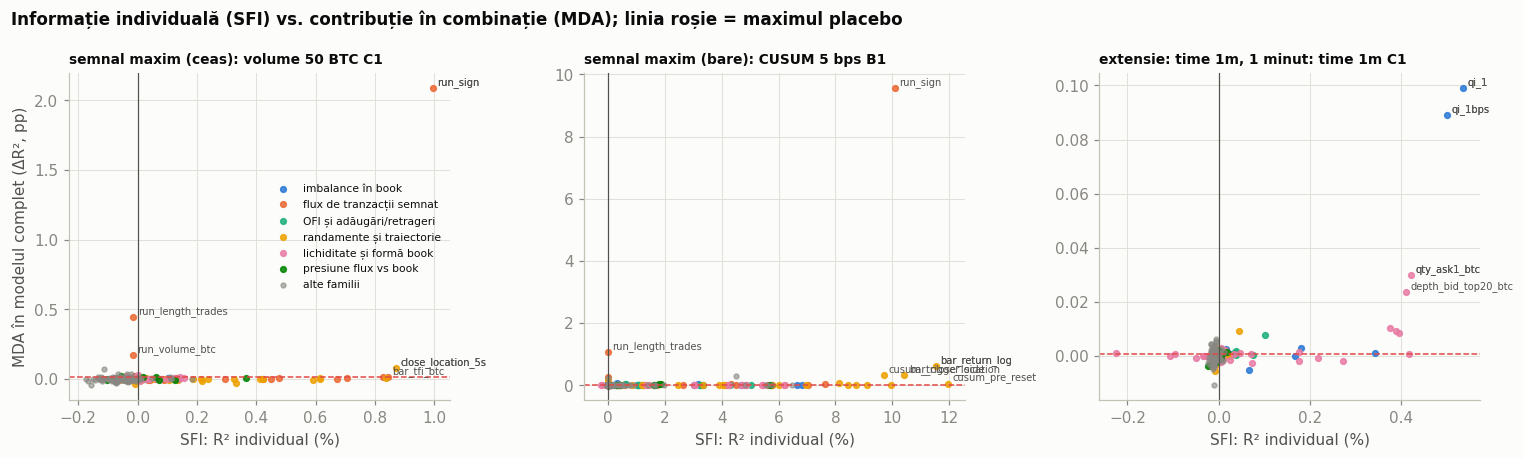

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (role, s, t) in zip(axes, [c for c in FI_COMBOS if c[0] in ("semnal maxim (ceas)", "semnal maxim (bare)", "extensie: time 1m, 1 minut")]):
    feat, clu, r2 = combo_tables(s, t, "lgb")
    sfi = SFI_T[s][SFI_T[s]["țintă"] == t].set_index("feature")["r2_bin"]
    real = [c for c in feat.index if not c.startswith("PLACEBO")]
    x, y = sfi.reindex(real), feat.loc[real, "pooled"]
    fams = [family_of(c) for c in real]
    for k, g in enumerate(["imbalance_book", "flux_semnat", "ofi", "randamente_traiectorie", "lichiditate_book", "presiune_book_flux"]):
        m = np.array([f_ == g for f_ in fams])
        ax.scatter(x[m], y[m], s=14, color=list(C.values())[k], label=FAMILY_LABEL[g], alpha=0.85)
    m = ~np.isin(fams, ["imbalance_book", "flux_semnat", "ofi", "randamente_traiectorie", "lichiditate_book", "presiune_book_flux"])
    ax.scatter(x[m], y[m], s=10, color=MUTED, label="alte familii", alpha=0.6)
    for c in y.sort_values().index[-4:].tolist() + x.sort_values().index[-3:].tolist():
        ax.annotate(c, (x[c], y[c]), fontsize=6.5, color=INK2, xytext=(3, 2), textcoords="offset points")
    ax.axhline(feat[feat.index.str.startswith("PLACEBO")]["pooled"].max(), color=C["red"], lw=1, ls="--")
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlabel("SFI: R² individual (%)")
    ax.set_title(f"{role}: {LABEL[s]} {t}", fontsize=9)
axes[0].set_ylabel("MDA în modelul complet (ΔR², pp)")
axes[0].legend(fontsize=7)
fig.suptitle("Informație individuală (SFI) vs. contribuție în combinație (MDA); linia roșie = maximul placebo", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

**Individual vs. în combinație.** Două tipare clare:

* **Substitute** (SFI mare, MDA mică): pe volume, `bar_close_location`, `close_location_30s`, `bar_count_imbalance`, `tfi_ratio_5s`; pe `time_1m`, adâncimile pe o parte și media `tw_qi_1_1s`. Fiecare are informație proprie, dar aceeași cu a lui `run_sign`, respectiv `qi_1`.
* **Modulatori** (SFI ≈ 0, MDA mare și stabilă): `run_length_trades` și `run_volume_btc` (0,45 și 0,17 pp pe volume la 1 minut, pozitive în toate foldurile; 1,06 pp pe CUSUM), plus durata barei și overshoot-ul CUSUM pe bara următoare. Sunt mărimi fără semn: nu spun direcția, dar scalează cât de mult contează semnul seriei curente. Singurul tip de interacțiune robustă găsit este deci **intensitatea seriei de tranzacții agresive × direcția ei**, la scara de secunde.

Nu am găsit features fără informație individuală care să devină importante la orizonturi lungi.

In [47]:
from scipy.stats import spearmanr
rows = []
for role, s, t in FI_COMBOS:
    M = MDI[(s, t)].fillna(0.0)                     # a feature never chosen by any tree has zero impurity decrease
    feat, clu, r2 = combo_tables(s, t, "lgb")
    sfi = SFI_T[s][SFI_T[s]["țintă"] == t].set_index("feature")["r2_bin"]
    real = [c for c in M.index if not c.startswith("PLACEBO")]
    gain = pd.Series(np.mean([r["lgb_gain"] for r in FI[(s, t)]], 0), index=FI[(s, t)][0]["names"])
    pl = M.loc[[c for c in M.index if c.startswith("PLACEBO")], "real"]
    rows.append({"rol": role, "set": s, "țintă": t,
                 "ρ(MDI, MDA)": spearmanr(M.loc[real, "real"], feat.loc[real, "pooled"])[0],
                 "ρ(MDI, SFI)": spearmanr(M.loc[real, "real"], sfi.reindex(real))[0],
                 "ρ(MDA, SFI)": spearmanr(feat.loc[real, "pooled"], sfi.reindex(real))[0],
                 "ρ(MDI real, MDI etichete deplasate)": spearmanr(M.loc[real, "real"], M.loc[real, "etichete deplasate"])[0],
                 "ρ(câștig split LGBM, MDA)": spearmanr(gain.loc[real], feat.loc[real, "pooled"])[0],
                 "features MDI > max placebo": int((M.loc[real, "real"] > pl.max()).sum()),
                 "top-5 MDI": ", ".join(M.loc[real, "real"].sort_values(ascending=False).index[:5]),
                 "top-5 MDA": ", ".join(feat.loc[real, "pooled"].sort_values(ascending=False).index[:5])})
MDI_CMP = pd.DataFrame(rows)
display(Markdown("**MDI (pădure aleatoare cu max_features = 1, în eșantion) față de MDA, SFI și câștigul de split LightGBM: corelații de rang Spearman.**"))
display(MDI_CMP.set_index(["rol", "set", "țintă"]).round(3))

**MDI (pădure aleatoare cu max_features = 1, în eșantion) față de MDA, SFI și câștigul de split LightGBM: corelații de rang Spearman.**

,,,"ρ(MDI, MDA)","ρ(MDI, SFI)","ρ(MDA, SFI)","ρ(MDI real, MDI etichete deplasate)","ρ(câștig split LGBM, MDA)",features MDI > max placebo,top-5 MDI,top-5 MDA
rol,set,țintă,,,,,,,,
semnal maxim (ceas),volume_50btc,C1,0.125,0.327,0.173,0.044,-0.016,204,"rebound_from_low_5s, run_sign, close_location_...","run_sign, run_length_trades, run_volume_btc, c..."
semnal în declin (ceas),volume_50btc,C2,0.106,0.100,0.123,0.051,0.063,156,"run_sign, rebound_from_low_5s, bar_tfi_ratio, ...","run_sign, run_length_trades, run_volume_btc, r..."
orizont lung (ceas),volume_50btc,C10,-0.021,-0.287,0.233,0.410,-0.059,108,"max_abs_ret_trade_15m_grid1s, size_concentrati...","notional_15m_vs_slot_median_28d, signed_large_..."
semnal maxim (bare),cusum_5bps,B1,0.434,0.712,0.390,0.064,0.586,312,"run_sign, cusum_trigger_side, close_location_5...","run_sign, run_length_trades, bar_return_log, c..."
"bare, orizont lung",cusum_5bps,B5,0.181,0.717,0.191,-0.054,0.331,220,"run_sign, cusum_trigger_side, vwap_distance_5s...","run_sign, run_length_trades, close_location_5s..."
mișcare ulterioară 2–5 min,volume_50btc,S120_300,-0.077,-0.410,0.130,0.413,-0.108,16,"pressure_buy_5bps_2m, volume_1h_btc, liq_long_...","rv_trade_2m_grid1s, rv_trade_15m_grid1s, notio..."
control negativ (placebo),volume_50btc,P1,0.030,-0.285,0.079,0.206,-0.011,18,"size_concentration_5s, ret_trade_4h, drawdown_...","rv_neg_trade_2m_grid1s, ret_trade_4h, size_con..."
"extensie: time 1m, 1 minut",time_1m,C1,0.097,0.190,0.195,0.098,0.097,103,"tw_qi_1_1s, cost_buy_5btc_bps, qty_ask1_btc, d...","qi_1, qi_1bps, qty_ask1_btc, depth_bid_top20_b..."
"extensie: time 1m, 5 minute",time_1m,C5,0.117,0.061,0.145,0.162,0.035,90,"qty_ask1_btc, qi_1bps, range_log_1h, liq_short...","qty_ask1_btc, qi_1, size_concentration_15m, st..."


**MDI rămâne un diagnostic slab.** MDI corelează doar 0,10–0,43 cu MDA out-of-sample; mai bine cu SFI acolo unde semnalul e puternic (0,71 pe CUSUM). Acolo unde nu există semnal (volume la 10 minute, intervalul 2–5 minute, placebo), MDI pe etichete deplasate corelează 0,2–0,4 cu MDI real, deci clasamentul reflectă forma distribuției, nu informația; în plus, pe combinațiile cu semnal, 90–312 features au MDI peste maximul placebo, mult mai multe decât cele cu contribuție out-of-sample. Câștigul de split LightGBM nu urmărește MDA (corelații de −0,1 … 0,6). Concluziile despre importanță se sprijină pe MDA grupat și pe SFI, nu pe MDI.

In [48]:
rows = []
for role, s, t in FI_COMBOS:
    recs = FI[(s, t)]
    dev = [r for r, (a, b) in zip(recs, FOLDS) if b <= DEV_END]
    late = [r for r, (a, b) in zip(recs, FOLDS) if b > DEV_END]
    if not dev or not late:
        continue
    names = recs[0]["names"]
    real = [i for i, c in enumerate(names) if not c.startswith("PLACEBO")]
    fd = sum(r["feat_l"] for r in dev) / sum(r["y2"] for r in dev)
    fl = sum(r["feat_l"] for r in late) / sum(r["y2"] for r in late)
    g = list(recs[0]["groups"])
    cd = np.array([sum(r["clu_l"][k] for r in dev) for k in g]) / sum(r["y2"] for r in dev)
    cl = np.array([sum(r["clu_l"][k] for r in late) for k in g]) / sum(r["y2"] for r in late)
    sd_ = pd.Series(SFI_T[s][SFI_T[s]["țintă"] == t].set_index("feature")["r2_bin"])
    top_d = set(np.array(names)[real][np.argsort(-fd[real])[:10]])
    top_l = set(np.array(names)[real][np.argsort(-fl[real])[:10]])
    top_cd = set(np.array(g)[np.argsort(-cd)[:5]])
    top_cl = set(np.array(g)[np.argsort(-cl)[:5]])
    rows.append({"rol": role, "set": s, "țintă": t, "ρ features (dezvoltare vs târziu)": spearmanr(fd[real], fl[real])[0],
                 "top-10 features comune": len(top_d & top_l), "ρ clustere (dezvoltare vs târziu)": spearmanr(cd, cl)[0],
                 "top-5 clustere comune": len(top_cd & top_cl),
                 "top-5 dezvoltare": ", ".join(np.array(names)[real][np.argsort(-fd[real])[:5]]),
                 "top-5 târziu": ", ".join(np.array(names)[real][np.argsort(-fl[real])[:5]])})
display(Markdown("**Stabilitatea clasamentelor între perioada de dezvoltare (F1–F4) și perioada târzie (F5–F7), LightGBM.**"))
display(pd.DataFrame(rows).set_index(["rol", "set", "țintă"]).round(3) if rows else "Nu există folduri în ambele perioade.")

**Stabilitatea clasamentelor între perioada de dezvoltare (F1–F4) și perioada târzie (F5–F7), LightGBM.**

,,,ρ features (dezvoltare vs târziu),top-10 features comune,ρ clustere (dezvoltare vs târziu),top-5 clustere comune,top-5 dezvoltare,top-5 târziu
rol,set,țintă,,,,,,
semnal maxim (ceas),volume_50btc,C1,-0.030,3,-0.004,4,"run_sign, run_length_trades, run_volume_btc, c...","run_sign, run_length_trades, run_volume_btc, l..."
semnal în declin (ceas),volume_50btc,C2,-0.069,4,0.058,4,"run_sign, run_length_trades, run_volume_btc, r...","run_sign, run_length_trades, max_abs_ret_trade..."
orizont lung (ceas),volume_50btc,C10,0.012,1,0.131,1,"run_sign, log1p_liq_notional_15m, ret_trade_15...","ticker_vwap_distance_trade_bps, std_basis_mark..."
semnal maxim (bare),cusum_5bps,B1,0.291,9,0.524,4,"run_sign, run_length_trades, bar_return_log, b...","run_sign, run_length_trades, basis_mid_index_b..."
"bare, orizont lung",cusum_5bps,B5,0.091,5,0.454,2,"run_sign, run_length_trades, close_location_5s...","run_sign, run_length_trades, run_duration_s, r..."
mișcare ulterioară 2–5 min,volume_50btc,S120_300,0.006,1,0.161,1,"rv_trade_2m_grid1s, size_concentration_1h, rv_...","notional_15m_vs_slot_median_28d, ret_trade_24h..."
control negativ (placebo),volume_50btc,P1,0.001,0,-0.355,0,"rv_neg_trade_2m_grid1s, ret_trade_4h, size_con...","liq_count_15m, liq_to_trade_notional_1h, trade..."
"extensie: time 1m, 1 minut",time_1m,C1,0.056,5,-0.036,1,"qi_1bps, qi_1, qty_ask1_btc, depth_bid_top20_b...","qi_1, qi_1bps, qty_ask1_btc, depth_bid_top20_b..."
"extensie: time 1m, 5 minute",time_1m,C5,0.057,2,0.043,2,"qty_ask1_btc, qi_1, size_concentration_15m, re...","qi_1, tw_depth1_15m_btc, std_basis_mark_index_..."


**Stabilitate între perioade.** Corelația clasamentelor complete între dezvoltare și perioada târzie este ~0, pentru că sute de features au importanță practic nulă și ordinea lor e zgomot. Primele locuri sunt însă stabile acolo unde există semnal: pe volume la 1 minut, aceleași trei features din seria curentă conduc în ambele perioade; pe `time_1m`, `qi_1`, `qi_1bps` și cantitatea de pe ask; pe CUSUM, 9 din primele 10 coincid. Pe combinațiile fără semnal (10 minute, 2–5 minute, placebo), suprapunerea este 0–1 din 10.

## 14. Relevanța economică (verificare simplă, nu strategie)

Pentru celulele cu semnal: semnul prognozei, prag pe |prognoză| ales pe foldurile anterioare (cuantila 90% sau 98% a prognozelor out-of-sample deja văzute), tranzacții nesuprapuse (următorul semnal după expirarea orizontului), execuție la mid, întârziere δ între decizie și intrare. Randamentul brut mediu pe tranzacție este comparat cu costuri **ipotetice** dus-întors (2, 4, 7, 10 bps), nu cu comisioanele reale ale contului, pe care nu le am. Spread-ul tipic este de un tick (~0,01 bps), deci costul dominant sunt comisioanele și latența. Nu sumez randamentele unor observații suprapuse.

In [49]:
def trade_eval(s, t, fs, m, q_sel, delays=(0.0, 0.1, 1.0, 5.0, 30.0)):
    """Threshold on |forecast| for fold k = quantile of the OOS |forecasts| of folds before k (causal; fold 1 is skipped). Non-overlapping:
    after a signal, the next one is taken only after the horizon has elapsed. Gross per trade = sign(f) * mid return from T+delta to T+h."""
    d = cell_data("native", s, t, fs).sort_values("tns")
    h_ns = int(t[1:]) * 60 * NS
    out = []
    taken = []
    for fi in sorted(d["fold"].unique()):
        prev = d[d["fold"] < fi]
        if len(prev) < 1000:
            continue
        thr = np.quantile(np.abs(prev[m]), q_sel)
        cur = d[(d["fold"] == fi) & ~d["crash"]]
        cand = cur[np.abs(cur[m]) >= thr]
        last = -np.inf
        for tn_, row_, f_ in zip(cand["tns"].to_numpy(), cand["row"].to_numpy(), cand[m].to_numpy()):
            if tn_ >= last + h_ns:
                taken.append((tn_, row_, np.sign(f_), f_))
                last = tn_
    if not taken:
        return []
    tk = pd.DataFrame(taken, columns=["tns", "row", "side", "f"])
    days = (END - FOLDS[1][0]).days
    for delay in delays:
        y = TG[s]["Y"][t][tk["row"]] if delay == 0 else TG[s]["Y"][f"D{delay:g}_{t}"][tk["row"]]
        g = (tk["side"].to_numpy() * y.astype(np.float64))
        ok = np.isfinite(g)
        day = tk["tns"].to_numpy()[ok] // (86400 * NS)
        gd = pd.Series(g[ok]).groupby(day).agg(["sum", "count"])
        mean = g[ok].mean()
        # day-clustered standard error of the mean gross per trade
        resid = gd["sum"] - mean * gd["count"]
        se = np.sqrt((resid ** 2).sum()) / gd["count"].sum()
        out.append({"set": s, "țintă": t, "model": f"{fs} · {m}", "selecție": f"top {100 * (1 - q_sel):.0f}%", "întârziere (s)": delay,
                    "tranzacții": int(ok.sum()), "pe zi": ok.sum() / days, "|prognoză| medie (bps)": np.abs(tk["f"]).mean(),
                    "brut mediu (bps)": mean, "t (cluster pe zile)": mean / se if se > 0 else np.nan, "rata de câștig": (g[ok] > 0).mean()})
    return out


ECON = cached("res_econ", lambda: pd.DataFrame([r for s in SETS for t in ("C1", "C2", "C5") for fs, m in (("FULL", "lgb"), ("QI", "ridge"))
                                                 for q in (0.90, 0.98) for r in trade_eval(s, t, fs, m, q)]))
FEES = [2, 4, 7, 10]
E = ECON.copy()
for c_ in FEES:
    E[f"net la {c_} bps dus-întors"] = E["brut mediu (bps)"] - c_
display(Markdown("**Amplitudine economică (prag ales pe folduri anterioare, tranzacții nesuprapuse, execuție la mid; costurile sunt ipoteze, nu comisioanele contului).**"))
display(E[E["model"] == "FULL · lgb"].set_index(["set", "țintă", "selecție", "întârziere (s)"])
        [["tranzacții", "pe zi", "|prognoză| medie (bps)", "brut mediu (bps)", "t (cluster pe zile)", "rata de câștig"] + [f"net la {c_} bps dus-întors" for c_ in FEES]].round(2))

**Amplitudine economică (prag ales pe folduri anterioare, tranzacții nesuprapuse, execuție la mid; costurile sunt ipoteze, nu comisioanele contului).**

tranzacții  pe zi  |prognoză| medie (bps)  brut mediu (bps)  t (cluster pe zile)  rata de câștig  net la 2 bps dus-întors  net la 4 bps dus-întors  net la 7 bps dus-întors  \
set           țintă selecție întârziere (s)                                                                                                                                                                                
time_1m       C1    top 10%  0.0                  22693  67.74                    1.28              0.72                 9.80            0.56                    -1.28                    -3.28                    -6.28   
                             0.1                  22691  67.73                    1.28              0.65                 8.73            0.55                    -1.35                    -3.35                    -6.35   
                             1.0                  22687  67.72                    1.28              0.26                 3.34            0.53                    -1.74                    -3.74                    -6.74   
                             5.0                  22643  67.59                    1.28             -0.00                -0.01            0.51                    -2.00                    -4.00                    -7.00   
                             30.0                 22648  67.61                    1.28             -0.04                -0.82            0.49                    -2.04                    -4.04                    -7.04   
                    top 2%   0.0                   6896  20.59                    1.69              0.87                 4.92            0.55                    -1.13                    -3.13                    -6.13   
                             0.1                   6896  20.59                    1.69              0.78                 4.38            0.54                    -1.22                    -3.22                    -6.22   
                             1.0                   6896  20.59                    1.69              0.37                 1.98            0.53                    -1.63                    -3.63                    -6.63   
                             5.0                   6885  20.55                    1.69             -0.03                -0.15            0.50                    -2.03                    -4.03                    -7.03   
                             30.0                  6891  20.57                    1.69             -0.17                -1.10            0.49                    -2.17                    -4.17                    -7.17   
              C2    top 10%  0.0                  23866  71.24                    1.03              0.66                 8.21            0.54                    -1.34                    -3.34                    -6.34   
                             0.1                  23865  71.24                    1.03              0.60                 7.44            0.54                    -1.40                    -3.40                    -6.40   
                             1.0                  23858  71.22                    1.03              0.25                 3.10            0.52                    -1.75                    -3.75                    -6.75   
                             5.0                  23798  71.04                    1.03             -0.00                -0.01            0.51                    -2.00                    -4.00                    -7.00   
                             30.0                 23788  71.01                    1.03             -0.12                -1.69            0.50                    -2.12                    -4.12                    -7.12   
                    top 2%   0.0                   4811  14.36                    1.41              0.96                 4.10            0.54                    -1.04                    -3.04                    -6.04   
                             0.1                   4810  14.36                    1.4

**Amplitudinea economică.**

* **`time_1m`:** cele mai puternice 2% dintre semnale (~20 pe zi) câștigă brut 0,87 bps pe tranzacție la 1 minut fără latență, 0,78 bps cu 100 ms, 0,37 bps cu 1 s și 0 cu 5 s. Pragul de rentabilitate este sub 1 bps dus-întors, deci nicio ipoteză realistă de cost nu este acoperită.
* **Volume și dollar:** la închiderea barei, top 2% câștigă brut 6,1–6,4 bps la 1 minut fără latență (aparent peste un cost de 2–4 bps), 3,2–3,5 bps cu 100 ms, ~0–0,5 bps cu 1 s. **Latența zero la închiderea unei bare de evenimente nu este fezabilă:** momentul deciziei este chiar recepția tranzacției care a închis bara. Cu 100 ms rămâne un brut de ~3,5 bps, care ar acoperi doar un cost ipotetic de 2 bps dus-întors; cu orice cost de taker sau cu 1 s de latență, nimic.
* **CUSUM:** câteva zeci-sute de tranzacții, t sub 1,6; zgomot.

Fără coadă de ordine, impact, latență reală și comisioane reale, pragul de 100 ms + 2 bps rămâne **un indiciu care cere o simulare cu latență măsurată**, nu o strategie.

In [50]:
def pick(T, s, t, fs, m, col="r2"):
    v = T[(T["set"] == s) & (T["țintă"] == t) & (T["features"] == fs) & (T["model"] == m)]
    return float(v[col].iloc[0]) if len(v) else np.nan


KEYN = pd.DataFrame([{"set": s, "orizont": t,
                      "complet LGBM": pick(NAT, s, t, "FULL", "lgb"), "complet ridge": pick(NAT, s, t, "FULL", "ridge"),
                      "qi_1 ridge": pick(NAT, s, t, "QI", "ridge"), "PVC LGBM": pick(NAT, s, t, "PVC", "lgb"),
                      "ceas comun complet LGBM": pick(COM, s, t, "FULL", "lgb"),
                      "δ = 1 s complet LGBM": DELAY[(DELAY["set"] == s) & (DELAY["țintă"] == t) & (DELAY["model"] == "FULL · lgb") & (DELAY["întârziere (s)"] == 1.0)]["r2"].mean()
                      if t in ("C1", "C2", "C5", "C10") else np.nan}
                     for s in SETS for t in NAT_T])
display(Markdown("**Cifrele-cheie folosite în rezumat (R² OOS, %).**"))
display(KEYN.set_index(["set", "orizont"]).round(3))

**Cifrele-cheie folosite în rezumat (R² OOS, %).**

complet LGBM  complet ridge  qi_1 ridge  PVC LGBM  ceas comun complet LGBM  δ = 1 s complet LGBM
set           orizont                                                                                                  
time_1m       C1              0.514          0.602       0.537     0.012                   -0.010                -0.070
              C2              0.200          0.252       0.232     0.015                   -0.010                -0.037
              C3              0.055          0.164       0.148    -0.023                      NaN                   NaN
              C4              0.047          0.121       0.113    -0.027                      NaN                   NaN
              C5             -0.024          0.092       0.083    -0.016                   -0.038                -0.084
              C10            -0.038          0.038       0.042    -0.016                   -0.036                -0.049
volume_50btc  C1              1.895          1.639       0.138     1.163                   -0.039                -1.499
              C2              0.850          0.558       0.074     0.341                   -0.020                -0.641
              C3              0.420          0.321       0.052     0.338                      NaN                   NaN
              C4              0.236          0.259       0.039     0.254                      NaN                   NaN
              C5             -0.044          0.170       0.031    -0.163                   -0.056                -0.355
              C10            -0.439          0.092       0.017    -0.411                   -0.067                -0.459
dollar_5musdt C1              1.349          1.806       0.143     1.389                   -0.048                -2.129
              C2              0.783          0.729       0.072     0.551                   -0.005                -0.683
              C3              0.410          0.394       0.056     0.428                      NaN                   NaN
              C4              0.270          0.277       0.033     0.446                      NaN                   NaN
              C5              0.078          0.189       0.028     0.084                   -0.023                -0.238
              C10            -0.468          0.118       0.014    -0.412                   -0.019                -0.459
cusum_5bps    C1              1.548          0.392       0.403     0.522                   -0.041                 0.143
              C2              2.031          3.059       0.285     2.768                   -0.018                 0.730
              C3              1.150          2.589       0.157     1.770                      NaN                   NaN
              C4              0.332          1.403       0.186     1.108                      NaN                   NaN
              C5             -0.365          1.426       0.165    -0.398                   -0.025                -0.640
              C10             0.641          0.422       0.112     1.472                   -0.062                 0.830

## 15. Concluzii

**Susținute de date (exploratoriu, pe istoricul deja folosit):**

1. Informația predictivă despre randamentul pe mid este concentrată în primele secunde după decizie. Pe `time_1m`, `qi_1` explică 0,54% din varianța randamentului de 1 minut și 1,0% din cea a primelor 30 s, stabil în toate lunile, fără reversie ulterioară. Rezultatul replică primul notebook cu un alt design (randament brut în bps, ținte pe mid, 7 folduri, purging pe capătul real).
2. Niciun set de bare, niciun model și nicio familie nu prezice mișcarea de după 30 s (30 s – 2 min, 2 – 5 min, 5 – 10 min).
3. Scorurile mari ale barelor de evenimente la închidere (inclusiv pe bara următoare) sunt continuarea sweep-ului care a închis bara: dispar în 100 ms – 1 s și nu există pe un ceas comun. Comparația echitabilă între bare le pune pe toate la zero când informația are vârsta tipică a ultimei bare (zeci de secunde).
4. Pe barele de timp, peste starea nivelului 1 din book, restul microstructurii (flux, OFI, presiune, derivate, lichidări) nu aduce informație robustă.
5. Fereastra cea mai scurtă a fiecărui tip de feature este cea mai informativă la orice orizont; ferestrele de 30 s – 24 h nu aduc informație individuală pentru ținte de până la 10 minute.
6. MDI și câștigul de split LightGBM nu sunt măsuri fiabile aici; importanța se judecă pe MDA grupat, cu placebo, și pe SFI.

**Doar indicii (necesită confirmare pe date noi sau o simulare realistă):**

* Brutul de ~3,5 bps la 100 ms pentru cele mai puternice 2% dintre semnalele de flux la închiderea barelor volume/dollar.
* Interacțiunea „intensitatea seriei de tranzacții agresive × direcția ei” ca sursă principală de informație la scara de secunde.
* Rolul bazei mid−index la închiderea barelor de evenimente (important doar în ridge).
* Reversia lentă din randamentele pe 1–24 h la 5–10 minute (R² ≤ 0,07%, nesemnificativ individual).
* Asimetria după declanșările CUSUM (continuare după mișcările în sus).
* R² mai mare pe book ancorat decât pe book reconstruit, confundat cu perioada.

**Netestat:** orizonturi peste 10 minute (deci nimic despre funding, open interest sau lichidări la ore); niveluri mai adânci ale book-ului ca secvențe (nu sunt pe grila de 100 ms); latența reală, poziția în coadă și comisioanele contului; seturile adaptive și `cusum_10bps`; dinamica din crash (acoperire insuficientă); ordinea evenimentelor în ultimele secunde, care este exact întrebarea experimentului următor.

**Limite ale designului.** LightGBM a fost calibrat doar între două capacități, iar cu ~355 de features și un semnal atât de slab a fost adesea sub modelul liniar; o regularizare mai fină ar putea schimba puțin cifrele LightGBM, dar nu concluziile, pe care ridge și `qi_1` liniar le susțin independent. Pe ceasul comun, modelele sunt antrenate pe toate vârstele informației, deci analiza pe clase de vechime este doar descriptivă.

## 16. Propunerea pentru experimentul cu istoric explicit

**Ce ar putea lipsi din reprezentarea actuală.** Toată informația găsită aici trăiește în primele secunde după decizie și vine din starea curentă a nivelului 1 din book și din fluxul agresiv al ultimelor secunde. Features-urile actuale văd acele secunde doar prin câteva agregate fixe (valoarea instantanee, medii pe 1 s și 5 s, sume pe 5 s), deci pierd **ordinea și viteza** evenimentelor: dacă coada de la best bid se golește sau se reface, cât de repede, dacă tranzacțiile agresive accelerează, dacă mid-ul a început deja să se miște. Două observații sugerează că acolo ar mai putea fi ceva: (1) fereastra cea mai scurtă domină sistematic, iar valoarea instantanee bate media pe 1 s, deci rezoluția temporală contează; (2) la închiderea barelor de evenimente, starea seriei de tranzacții (`run_sign`) explică de 5–10 ori mai mult decât imbalance-ul, dar se consumă în 100 ms–1 s, adică exact la scara pe care agregatele nu o rezolvă. Nimic din acest studiu nu justifică istoric lung: ferestrele de 30 s – 24 h nu aduc informație individuală, iar intervalele de după 30 s nu sunt previzibile.

**Ce secvențe.** Grila de top-of-book de 100 ms deja produsă (`derived/book_grid/btcusdt_v2/grid100ms`: bid, ask, cantitățile de la nivelul 1, starea și vârsta), plus, pe aceeași grilă, agregate de tranzacții pe fiecare pas de 100 ms (volum cumpărat și vândut agresiv, număr de tranzacții, semnul seriei curente). Fără niveluri mai adânci în prima etapă: ele nu sunt pe grilă, iar nivelul 1 a purtat aproape toată informația. Contextul lent (volatilitate, activitate relativă, calendar) intră ca vector static, nu ca secvență.

**Ce rezoluție și orizont.** Pas de 100 ms, istoric de 30 s (300 de pași; 60 s ca variantă de sensibilitate). Ținte pe mid între `T + δ` și `T + h`, cu h ∈ {1 s, 5 s, 30 s, 60 s} și întârziere δ ∈ {100 ms, 1 s} — nu δ = 0, care pe barele de evenimente nu este executabil. Momentele de decizie pe **ceas comun** (momente aleatoare), ca să nu reintroducă selecția momentelor de închidere; închiderile barelor doar ca analiză secundară, cu δ > 0.

**Comparația care ar demonstra contribuția istoricului.** Aceleași momente, ținte, folduri walk-forward și purging, aceeași familie de modele acolo unde este posibil:

| Variantă | Intrare | Ce izolează |
|---|---|---|
| A | features actuale recalculate la `T` (cel mai bun dintre ridge și LightGBM) | baseline-ul de azi |
| B | A + rezumate construite manual din aceeași fereastră de 30 s (OFI, flux, schimbări de cantitate pe 100 ms, 500 ms, 1 s, 5 s; variația mid-ului; timpul de la ultima schimbare a nivelului 1) | „mai multe date” fără structură temporală |
| C | A + secvența de 30 s, cu cel mai simplu model care poate folosi ordinea (de exemplu un model liniar cu lag-uri distribuite pe grila de 100 ms, apoi o rețea mică convoluțională sau recurentă) | contribuția istoricului |
| D | ca C, dar cu ordinea pașilor permutată aleator în fereastră (același conținut, fără ordine) | contribuția ordinii |

Istoricul este util numai dacă **C − B > 0 și C − D > 0** la δ = 100 ms, cu interval bootstrap pe blocuri de zile care exclude zero în majoritatea foldurilor și peste o distribuție placebo (aceeași procedură pe ținte deplasate cu 7 zile). Criteriul trebuie scris înainte de rulare și confirmat **numai pe date de după 2026-10-31**, pentru că tot istoricul de aici a fost deja explorat. Dacă B ajunge la C, istoricul nu adaugă nimic dincolo de rezumate mai fine și nu merită un model secvențial. Dacă nici C nu supraviețuiește lui δ = 1 s, câștigul nu poate fi folosit decât cu infrastructură de latență foarte mică, iar decizia este economică, nu statistică.

## 17. Reproductibilitate

In [51]:
FINGERPRINT_END = source_fingerprint()
peak_self = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 ** 2
peak_child = resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss / 1024 ** 2
print(f"Durata acestei execuții: {(time.time() - T0) / 60:.1f} min (cu cache-ul existent; prima rulare completă, fără cache, a durat aproximativ 3 ore pe 8 procese).")
print(f"Memorie maximă: proces principal {peak_self:.1f} GB, cel mai mare proces copil {peak_child:.1f} GB.")
print(f"Fișierele sursă (dataset, manifest, grila de 100 ms) sunt neschimbate: {FINGERPRINT_END == FINGERPRINT_START}")
assert FINGERPRINT_END == FINGERPRINT_START

Durata acestei execuții: 3.1 min (cu cache-ul existent; prima rulare completă, fără cache, a durat aproximativ 3 ore pe 8 procese).
Memorie maximă: proces principal 6.9 GB, cel mai mare proces copil 0.2 GB.
Fișierele sursă (dataset, manifest, grila de 100 ms) sunt neschimbate: True
